# F1 Podium Prediction: Milestone 1

**Task:** binary classification, will a driver finish on the podium (`positionOrder <= 3`)?
**Unit of analysis:** one driver entering one race, i.e. unique `(raceId, driverId)`.
**Prediction cutoff:** after qualifying, before the race starts.

## Notebook map
1. Setup
2. Audit and EDA (before cleaning)
3. Cleaning
4. Data-engineering questions (Q1-Q3)
5. Feature selection and engineering
6. Preprocessing and experiments
7. Train / validation / test split
8. Modeling
9. Feature-group ablation
10. Explainability (XAI)
11. Inference function

In [259]:
import os
import re
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 150)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 110

In [260]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Time-based split boundaries (seasons), from the project brief
TRAIN_END = 2019        # train: year <= 2019
VAL_YEARS = (2020, 2021)  # validation
TEST_START = 2022       # test: year >= 2022
LAST_SEASON = 2024      # the brief covers 1950-2024; later seasons (if the dataset has them) are out of scope

TARGET = "podium"       # engineered later from positionOrder <= 3

# Locate the dataset: Kaggle first, then a local ./data folder
CANDIDATES = [
    Path("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020")
]
DATA_DIR = next((p for p in CANDIDATES if p.exists()), None)
assert DATA_DIR is not None, "Dataset folder not found. Add the Kaggle dataset or put CSVs in ./data"
print("Using data from:", DATA_DIR)

Using data from: /kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020


In [261]:
TABLES = [
    "circuits", "constructors", "constructor_results", "constructor_standings",
    "drivers", "driver_standings", "races", "results", "qualifying",
    "lap_times", "pit_stops", "sprint_results", "seasons", "status",
]

# Read exactly as stored. "\N" stays a literal string here on purpose;
# sentinel handling is a documented step in the cleaning section.
RAW = {}
for name in TABLES:
    path = DATA_DIR / f"{name}.csv"
    if path.exists():
        RAW[name] = pd.read_csv(path, dtype=str, keep_default_na=False)
    else:
        print(f"Missing file: {name}.csv")

missing = set(TABLES) - set(RAW)
assert not missing, f"Missing tables: {missing}"
print(f"Loaded {len(RAW)} tables.")

Loaded 14 tables.


In [262]:
# All cleaning happens on these copies. RAW is never modified.
def fresh_copies():
    return {name: df.copy(deep=True) for name, df in RAW.items()}

T = fresh_copies()
print("Working copies ready:", list(T.keys()))

Working copies ready: ['circuits', 'constructors', 'constructor_results', 'constructor_standings', 'drivers', 'driver_standings', 'races', 'results', 'qualifying', 'lap_times', 'pit_stops', 'sprint_results', 'seasons', 'status']


In [263]:
overview = pd.DataFrame({
    "rows": {k: len(v) for k, v in RAW.items()},
    "cols": {k: v.shape[1] for k, v in RAW.items()},
    "columns": {k: ", ".join(v.columns[:8]) + (" ..." if v.shape[1] > 8 else "") for k, v in RAW.items()},
}).sort_values("rows", ascending=False)
overview

,rows,cols,columns
lap_times,589081,6,"raceId, driverId, lap, position, time, millise..."
driver_standings,34863,7,"driverStandingsId, raceId, driverId, points, p..."
results,26759,18,"resultId, raceId, driverId, constructorId, num..."
constructor_standings,13391,7,"constructorStandingsId, raceId, constructorId,..."
constructor_results,12625,5,"constructorResultsId, raceId, constructorId, p..."
pit_stops,11371,7,"raceId, driverId, stop, lap, time, duration, m..."
qualifying,10494,9,"qualifyId, raceId, driverId, constructorId, nu..."
races,1125,18,"raceId, year, round, circuitId, name, date, ti..."
drivers,861,9,"driverId, driverRef, number, code, forename, s..."
sprint_results,360,16,"resultId, raceId, driverId, constructorId, num..."


In [264]:
SENTINEL = r"\N"

def sentinel_report(df, name=""):
    """Count literal \\N sentinels per column."""
    counts = (df == SENTINEL).sum()
    out = pd.DataFrame({"sentinel_count": counts, "pct": counts / len(df) * 100})
    out = out[out.sentinel_count > 0].sort_values("sentinel_count", ascending=False)
    out.index.name = name
    return out

def check_pk(df, cols, name=""):
    """Check that the key is unique and non-null."""
    cols = [cols] if isinstance(cols, str) else list(cols)
    nulls = df[cols].isin([SENTINEL, ""]).any(axis=1).sum() + df[cols].isna().any(axis=1).sum()
    dups = df.duplicated(subset=cols).sum()
    status = "OK" if (nulls == 0 and dups == 0) else "PROBLEM"
    print(f"[{status}] {name} PK {cols}: duplicates={dups}, nulls={nulls}")
    return dups, nulls

def check_fk(child, child_col, parent, parent_col, name=""):
    """Count child FK values that don't exist in the parent table."""
    c = child[child_col]
    c = c[(c != SENTINEL) & c.notna()]
    orphans = (~c.isin(parent[parent_col])).sum()
    status = "OK" if orphans == 0 else "PROBLEM"
    print(f"[{status}] FK {name}: orphans={orphans}")
    return orphans

## Prediction cutoff and leakage policy

**Allowed (known after qualifying, before lights out):**
grid position, qualifying position and times, circuit, season/era,
driver and constructor history from *previous* races only,
standings *before* this race (shifted).

**Forbidden (post-race, leakage):**
current-race `position`, `positionText`, `positionOrder`, `points`,
`laps`, `time`, `milliseconds`, `fastestLap*`, `statusId`,
lap times, pit stops, and post-race driver/constructor standings.

**Judgement call:** sprint results (2021+) happen before the main race,
so they are technically pre-race. The decision is documented in the feature section.

# 2. Audit and EDA (before cleaning)

Goals: quantify sentinels, key integrity, duplicate grain, podium base rate,
qualifying coverage drift, and grid anomalies, so each cleaning decision
in Section 3 is backed by evidence. Section 3 ends with the same checks
re-run so the impact of cleaning is visible.

,table,column,sentinel_count,pct
0,constructor_results,status,12608,99.8653
3,races,sprint_time,1110,98.6667
4,races,sprint_date,1107,98.4000
5,races,fp3_time,1072,95.2889
7,races,fp2_time,1057,93.9556
6,races,quali_time,1057,93.9556
8,races,fp1_time,1057,93.9556
9,races,fp3_date,1053,93.6000
1,drivers,number,802,93.1475
10,races,fp2_date,1035,92.0000


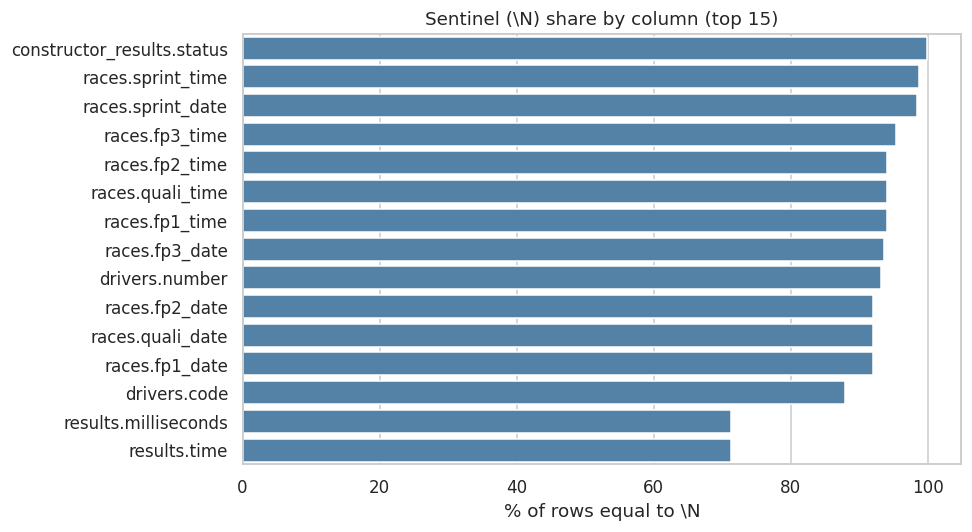

In [265]:
rows = []
for name, df in T.items():
    rep = sentinel_report(df, name)
    for col, r in rep.iterrows():
        rows.append({"table": name, "column": col,
                     "sentinel_count": int(r.sentinel_count), "pct": r.pct})
sent_df = pd.DataFrame(rows).sort_values("pct", ascending=False)
display(sent_df.head(25))

top = sent_df.head(15).copy()
top["label"] = top["table"] + "." + top["column"]
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=top, y="label", x="pct", color="steelblue", ax=ax)
ax.set_xlabel("% of rows equal to \\N")
ax.set_ylabel("")
ax.set_title("Sentinel (\\N) share by column (top 15)")
plt.tight_layout(); plt.show()

In [266]:
pk_spec = {
    "circuits": "circuitId", "constructors": "constructorId", "drivers": "driverId",
    "races": "raceId", "results": "resultId", "qualifying": "qualifyId",
    "status": "statusId", "seasons": "year", "sprint_results": "resultId",
    "constructor_results": "constructorResultsId",
    "constructor_standings": "constructorStandingsId",
    "driver_standings": "driverStandingsId",
    "pit_stops": ["raceId", "driverId", "stop"],
    "lap_times": ["raceId", "driverId", "lap"],
}
print("PRIMARY KEYS")
pk_results_before = {n: check_pk(T[n], c, n) for n, c in pk_spec.items()}

fk_spec = [
    ("results", "raceId", "races", "raceId"),
    ("results", "driverId", "drivers", "driverId"),
    ("results", "constructorId", "constructors", "constructorId"),
    ("results", "statusId", "status", "statusId"),
    ("qualifying", "raceId", "races", "raceId"),
    ("qualifying", "driverId", "drivers", "driverId"),
    ("qualifying", "constructorId", "constructors", "constructorId"),
    ("races", "circuitId", "circuits", "circuitId"),
    ("races", "year", "seasons", "year"),
    ("driver_standings", "raceId", "races", "raceId"),
    ("driver_standings", "driverId", "drivers", "driverId"),
    ("constructor_standings", "raceId", "races", "raceId"),
    ("constructor_standings", "constructorId", "constructors", "constructorId"),
    ("constructor_results", "raceId", "races", "raceId"),
    ("constructor_results", "constructorId", "constructors", "constructorId"),
    ("sprint_results", "raceId", "races", "raceId"),
    ("sprint_results", "driverId", "drivers", "driverId"),
    ("sprint_results", "statusId", "status", "statusId"),
    ("pit_stops", "raceId", "races", "raceId"),
    ("pit_stops", "driverId", "drivers", "driverId"),
    ("lap_times", "raceId", "races", "raceId"),
    ("lap_times", "driverId", "drivers", "driverId"),
]
print("\nFOREIGN KEYS")
fk_results_before = {
    f"{c}.{cc} -> {p}.{pc}": check_fk(T[c], cc, T[p], pc, f"{c}.{cc} -> {p}.{pc}")
    for c, cc, p, pc in fk_spec
}

PRIMARY KEYS
[OK] circuits PK ['circuitId']: duplicates=0, nulls=0
[OK] constructors PK ['constructorId']: duplicates=0, nulls=0
[OK] drivers PK ['driverId']: duplicates=0, nulls=0
[OK] races PK ['raceId']: duplicates=0, nulls=0
[OK] results PK ['resultId']: duplicates=0, nulls=0
[OK] qualifying PK ['qualifyId']: duplicates=0, nulls=0
[OK] status PK ['statusId']: duplicates=0, nulls=0
[OK] seasons PK ['year']: duplicates=0, nulls=0
[OK] sprint_results PK ['resultId']: duplicates=0, nulls=0
[OK] constructor_results PK ['constructorResultsId']: duplicates=0, nulls=0
[OK] constructor_standings PK ['constructorStandingsId']: duplicates=0, nulls=0
[OK] driver_standings PK ['driverStandingsId']: duplicates=0, nulls=0
[OK] pit_stops PK ['raceId', 'driverId', 'stop']: duplicates=0, nulls=0
[OK] lap_times PK ['raceId', 'driverId', 'lap']: duplicates=0, nulls=0

FOREIGN KEYS
[OK] FK results.raceId -> races.raceId: orphans=0
[OK] FK results.driverId -> drivers.driverId: orphans=0
[OK] FK results.

In [267]:
ERAS = [
    (1950, 1957, "1950-57 front-engine"),
    (1958, 1965, "1958-65 rear-engine"),
    (1966, 1976, "1966-76 3L and wings"),
    (1977, 1988, "1977-88 turbo/ground effect"),
    (1989, 1994, "1989-94 post-turbo"),
    (1995, 2008, "1995-2008 V10/V8"),
    (2009, 2013, "2009-13 late V8"),
    (2014, 2021, "2014-21 hybrid"),
    (2022, 2024, "2022-24 ground effect"),
]
def era_of(y):
    for a, b, label in ERAS:
        if a <= y <= b:
            return label
    return np.nan

races_eda = T["races"][["raceId", "year", "round", "circuitId", "name"]].rename(columns={"name": "race_name"})
eda = T["results"].merge(races_eda, on="raceId", how="left")

num_cols = ["resultId", "raceId", "driverId", "constructorId", "grid",
            "positionOrder", "year", "round", "circuitId", "statusId"]
for c in num_cols:
    eda[c] = pd.to_numeric(eda[c].replace(SENTINEL, np.nan), errors="coerce")

eda["podium"] = (eda["positionOrder"] <= 3).astype(int)
eda["era"] = eda["year"].apply(era_of)

print("Rows in results:", len(eda), "| seasons:", int(eda.year.min()), "-", int(eda.year.max()))
print("Overall podium rate:", round(eda.podium.mean(), 4))
eda[["raceId", "driverId", "year", "grid", "positionOrder", "podium", "era"]].head()

Rows in results: 26759 | seasons: 1950 - 2024
Overall podium rate: 0.1269


,raceId,driverId,year,grid,positionOrder,podium,era
0,18,1,2008,1,1,1,1995-2008 V10/V8
1,18,2,2008,5,2,1,1995-2008 V10/V8
2,18,3,2008,7,3,1,1995-2008 V10/V8
3,18,4,2008,11,4,0,1995-2008 V10/V8
4,18,5,2008,3,5,0,1995-2008 V10/V8


Rows involved in duplicate keys: 176
Extra rows that would be dropped (keeping one per key): 91
Affected races: 42 | affected drivers: 47


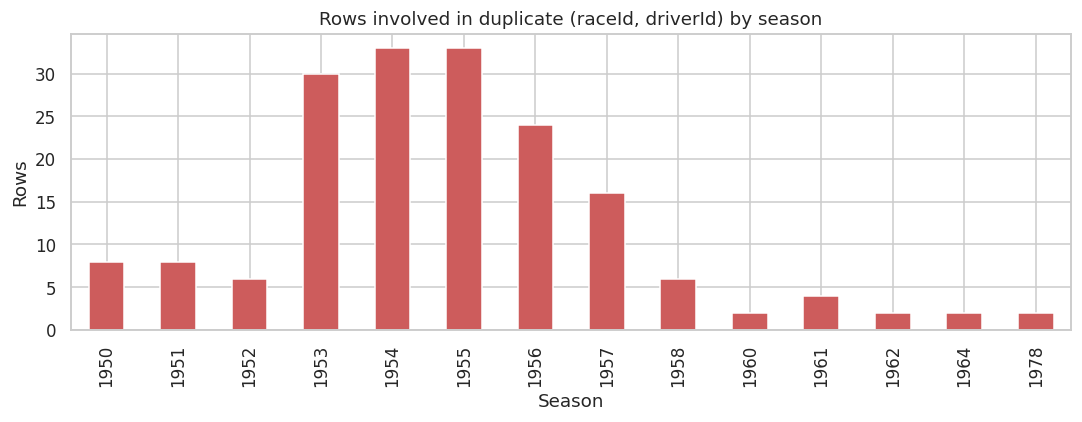

,raceId,year,driverId,constructorId,grid,positionOrder,podium
13188,540,1978,229,54,0,26,0
13191,540,1978,229,57,0,29,0
17362,717,1964,373,172,1,7,0
24298,717,1964,373,172,1,12,0
17740,733,1962,465,172,0,22,0
17743,733,1962,465,97,0,25,0
17961,742,1961,475,102,20,19,0
17963,742,1961,475,172,5,21,0
24297,745,1961,418,172,15,11,0
18062,745,1961,418,172,11,17,0


Duplicate groups containing a podium row: 22


In [268]:
key = ["raceId", "driverId"]
dup_mask = eda.duplicated(subset=key, keep=False)
dup_rows = eda[dup_mask]
n_extra = eda.duplicated(subset=key).sum()

print(f"Rows involved in duplicate keys: {len(dup_rows)}")
print(f"Extra rows that would be dropped (keeping one per key): {n_extra}")
print(f"Affected races: {dup_rows.raceId.nunique()} | affected drivers: {dup_rows.driverId.nunique()}")

by_year = dup_rows.groupby("year").size()
fig, ax = plt.subplots(figsize=(10, 4))
by_year.plot(kind="bar", color="indianred", ax=ax)
ax.set_title("Rows involved in duplicate (raceId, driverId) by season")
ax.set_xlabel("Season"); ax.set_ylabel("Rows")
plt.tight_layout(); plt.show()

cols = ["raceId", "year", "driverId", "constructorId", "grid", "positionOrder", "podium"]
display(dup_rows.sort_values(key + ["positionOrder"])[cols].head(12))
print("Duplicate groups containing a podium row:",
      dup_rows.groupby(key).podium.max().sum())

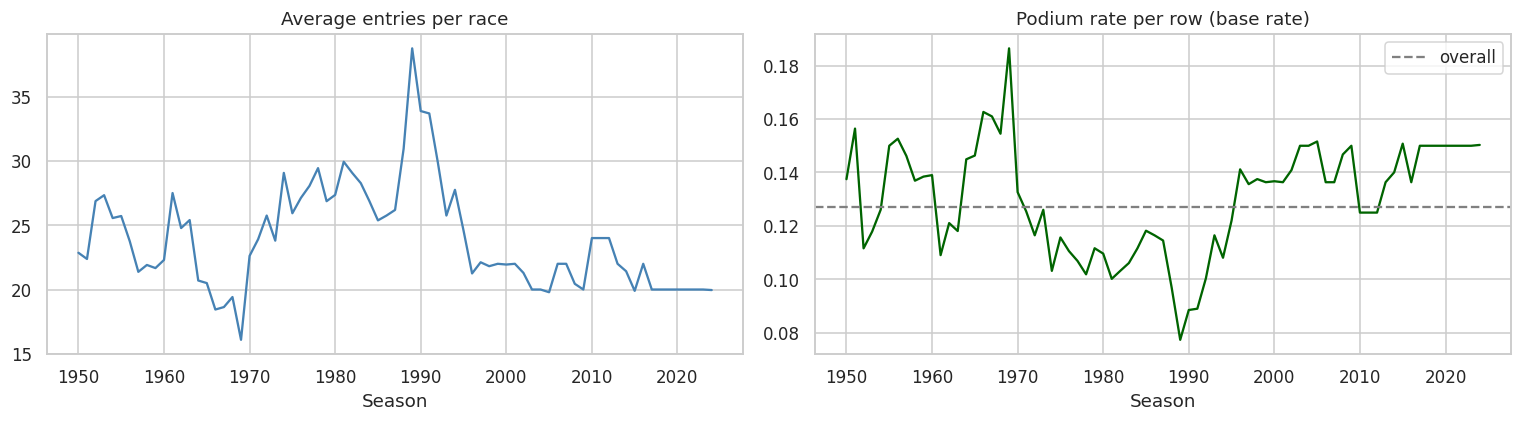

,rows,podium_rate
era,,
1950-57 front-engine,1571,0.1356
1958-65 rear-engine,1768,0.1312
1966-76 3L and wings,3237,0.1288
1977-88 turbo/ground effect,5234,0.1078
1989-94 post-turbo,3035,0.0949
1995-2008 V10/V8,5138,0.1395
2009-13 late V8,2150,0.1312
2014-21 hybrid,3267,0.1469
2022-24 ground effect,1359,0.1501


In [269]:
season = eda.groupby("year").agg(
    entries=("resultId", "count"),
    races=("raceId", "nunique"),
    podium_rate=("podium", "mean"),
)
season["avg_field"] = season.entries / season.races

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(season.index, season.avg_field, color="steelblue")
axes[0].set_title("Average entries per race"); axes[0].set_xlabel("Season")
axes[1].plot(season.index, season.podium_rate, color="darkgreen")
axes[1].axhline(eda.podium.mean(), ls="--", color="gray", label="overall")
axes[1].set_title("Podium rate per row (base rate)"); axes[1].set_xlabel("Season")
axes[1].legend()
plt.tight_layout(); plt.show()

era_stats = eda.groupby("era").agg(rows=("podium", "size"), podium_rate=("podium", "mean"))
era_stats = era_stats.reindex([e[2] for e in ERAS])
display(era_stats)

First season with any qualifying row: 1994
First season with >=90% result coverage: 1995


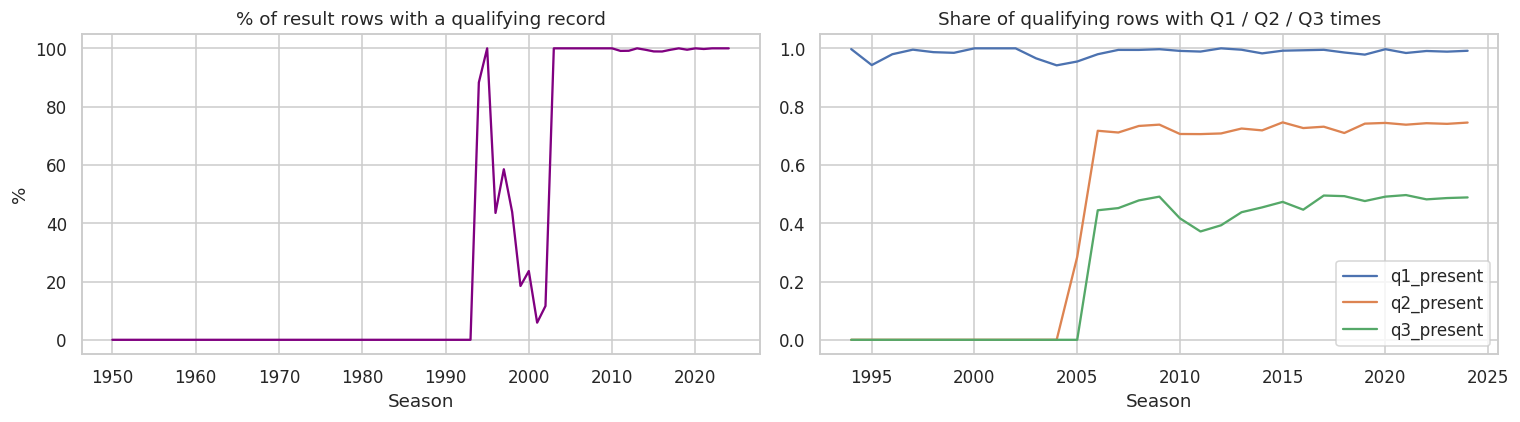

In [270]:
q = T["qualifying"].copy()
for c in ["raceId", "driverId"]:
    q[c] = pd.to_numeric(q[c], errors="coerce")
for c in ["q1", "q2", "q3"]:
    q[f"{c}_present"] = (q[c] != SENTINEL) & (q[c] != "")

qkeys = pd.MultiIndex.from_frame(q[key].drop_duplicates())
eda["has_quali"] = pd.MultiIndex.from_frame(eda[key]).isin(qkeys)

qa = q.merge(races_eda.assign(raceId=pd.to_numeric(races_eda.raceId))[["raceId", "year"]],
             on="raceId", how="left")
qa["year"] = pd.to_numeric(qa["year"])

cov = eda.groupby("year").has_quali.mean()
qpart = qa.groupby("year")[["q1_present", "q2_present", "q3_present"]].mean()

print("First season with any qualifying row:", int(qa.year.min()))
print("First season with >=90% result coverage:", int(cov[cov >= 0.9].index.min()))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(cov.index, cov.values * 100, color="purple")
axes[0].set_title("% of result rows with a qualifying record")
axes[0].set_xlabel("Season"); axes[0].set_ylabel("%")
qpart.plot(ax=axes[1])
axes[1].set_title("Share of qualifying rows with Q1 / Q2 / Q3 times")
axes[1].set_xlabel("Season")
plt.tight_layout(); plt.show()

grid == 0 rows: 1638 (6.1%)
grid missing: 0


,share_grid_0
era,
1950-57 front-engine,0.0223
1958-65 rear-engine,0.1205
1966-76 3L and wings,0.0519
1977-88 turbo/ground effect,0.1085
1989-94 post-turbo,0.1822
1995-2008 V10/V8,0.0029
2009-13 late V8,0.0033
2014-21 hybrid,0.0119
2022-24 ground effect,0.0294


Podium rate when grid==0: 0.0


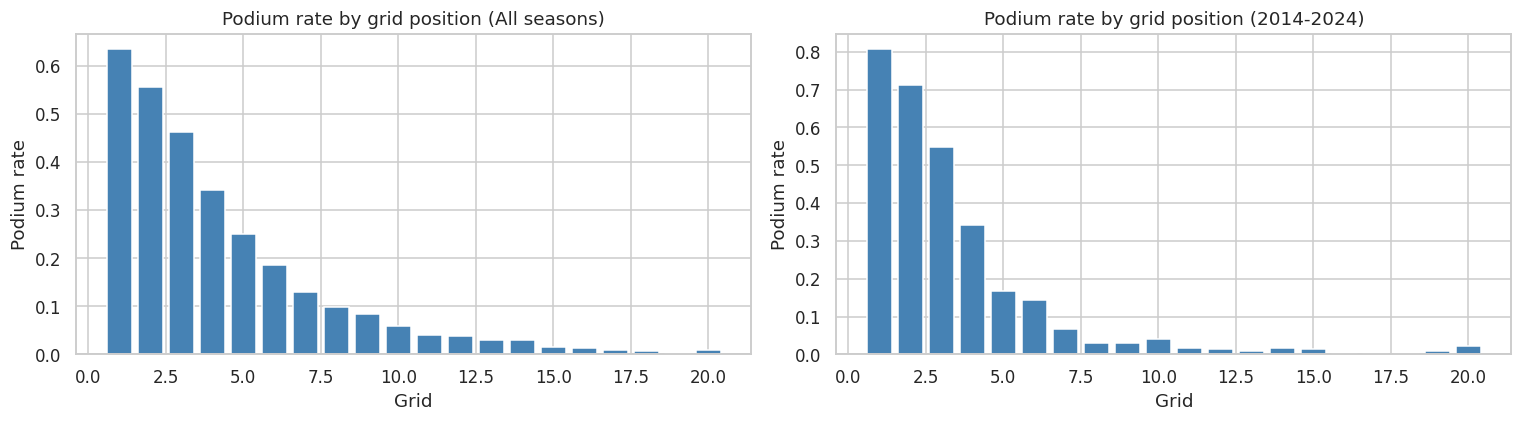

In [271]:
print("grid == 0 rows:", (eda.grid == 0).sum(), f"({(eda.grid == 0).mean():.1%})")
print("grid missing:", eda.grid.isna().sum())

grid0_by_era = eda.assign(g0=(eda.grid == 0)).groupby("era").g0.mean().reindex([e[2] for e in ERAS])
display(grid0_by_era.to_frame("share_grid_0"))
print("Podium rate when grid==0:", round(eda[eda.grid == 0].podium.mean(), 4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (title, sub) in zip(axes, [("All seasons", eda), ("2014-2024", eda[eda.year >= 2014])]):
    g = sub[(sub.grid >= 1) & (sub.grid <= 20)].groupby("grid").podium.mean()
    ax.bar(g.index, g.values, color="steelblue")
    ax.set_title(f"Podium rate by grid position ({title})")
    ax.set_xlabel("Grid"); ax.set_ylabel("Podium rate")
plt.tight_layout(); plt.show()

position is \N: 0.409
positionOrder is \N: 0

positionText codes (non-numeric):


,rows
positionText,
R,8897
F,1368
W,336
N,190
D,151
E,9


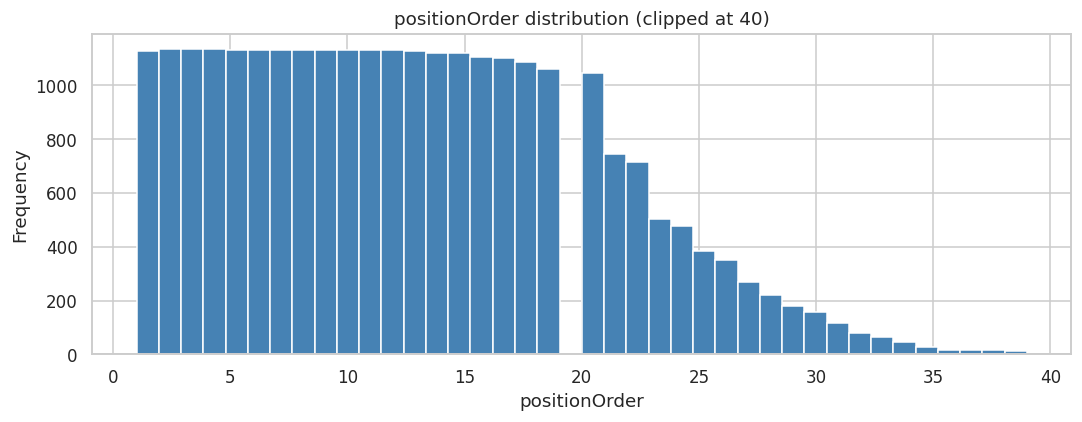

In [272]:
res = T["results"]
print("position is \\N:", (res.position == SENTINEL).mean().round(3))
print("positionOrder is \\N:", (res.positionOrder == SENTINEL).sum())

print("\npositionText codes (non-numeric):")
codes = res.positionText[~res.positionText.str.fullmatch(r"\d+")].value_counts()
display(codes.to_frame("rows"))

fig, ax = plt.subplots(figsize=(10, 4))
eda.positionOrder.clip(upper=40).plot(kind="hist", bins=40, color="steelblue", ax=ax)
ax.set_title("positionOrder distribution (clipped at 40)")
ax.set_xlabel("positionOrder")
plt.tight_layout(); plt.show()

In [273]:
BEFORE = {
    "results_rows": len(eda),
    "dup_extra_rows": int(n_extra),
    "grid_zero_rows": int((eda.grid == 0).sum()),
    "podium_rate": float(eda.podium.mean()),
    "sentinel_cols": len(sent_df),
    "quali_cov_overall": float(eda.has_quali.mean()),
    "pk_problems": sum(1 for d, n in pk_results_before.values() if d or n),
    "fk_problems": sum(1 for v in fk_results_before.values() if v),
}
pd.Series(BEFORE).to_frame("before_cleaning")

,before_cleaning
results_rows,"26,759.0000"
dup_extra_rows,91.0000
grid_zero_rows,"1,638.0000"
podium_rate,0.1269
sentinel_cols,30.0000
quali_cov_overall,0.3922
pk_problems,0.0000
fk_problems,0.0000


## Findings from the pre-cleaning audit
- **Sentinels:** 30 columns across the 14 tables contain the literal `\N`. The largest shares are `constructor_results.status` (99.9%), the sprint, practice and qualifying dates and times in `races` (92-99%, only recorded for recent seasons), `drivers.number` (93%) and `drivers.code` (88%), and the post-race result columns (`results.milliseconds` and `time` 71%, `fastestLap*` 69%, `rank` 68%). In `qualifying`, `q2` is `\N` for 44% of rows and `q3` for 65% (knockout format). `results.position` is `\N` for 40.9% of rows (retired or not classified), while `positionOrder` is never `\N`, which is why it defines the target. The sentinel means "not applicable or not recorded", not missing at random.
- **Duplicate (raceId, driverId):** 85 groups, 176 rows involved, 91 extra rows, across 42 races and 47 drivers, all in seasons 1950-1978 (shared drives and drivers who raced two cars). 22 groups contain a podium row and 2 groups have more than one. The rule in Section 3 therefore keeps the car the driver started, then the best grid, then the lowest `resultId`.
- **Podium base rate:** 12.7% of all result rows. It ranges from 9.5% in 1989-94 (large fields, many non-qualifiers) to 15.0% in 2022-24; the hybrid era is 14.7% and 1995-2008 is 14.0%. The base rate falls as the field grows.
- **Qualifying coverage:** the first season with any qualifying row is 1994 and coverage reaches at least 90% of result rows in 1995. Overall only 39.2% of result rows have a qualifying record, and `q3` exists for only 35% of qualifying rows. The plan is to model only seasons with qualifying data (the start year is chosen by Experiment H in Section 6), use earlier races only to build form history, and impute the remaining gaps with missing-value indicators.
- **grid == 0:** 1,638 rows (6.1%), concentrated in 1989-94 (18.2%), 1958-65 (12.1%) and 1977-88 (10.9%) but only 0.3% in 1995-2013. The podium rate for these rows is 0.0, so before 1995 they are mostly drivers who did not start; in the modern era they are pit-lane starts. Non-starters are removed in Section 3; the 87 remaining grid-0 rows are pit-lane starts and are kept with a flag.
- **Key integrity:** 0 primary-key problems (all 14 tables) and 0 foreign-key orphans (all 22 relations checked) before cleaning. The only grain violation is the duplication above.

# 3. Data Cleaning

All cleaning is applied to copies (`C`); `RAW` is never modified.

Steps:
1. Sentinels (`\N`) and empty strings become real missing values
2. Semantic typing (ints, floats, dates, clock times, lap times in seconds)
3. Key integrity re-check (PK unique and non-null, FK reconcile)
4. Grain fix: exactly one row per `(raceId, driverId)`
5. Scope decisions: seasons after `LAST_SEASON`, Indianapolis 500 (1950-60) and non-starters
6. Validation and before/after comparison

In [274]:
C = fresh_copies()

sent_before = {n: int((df == SENTINEL).sum().sum()) for n, df in C.items()}

for n in C:
    C[n] = C[n].replace({SENTINEL: np.nan, "": np.nan})

remaining = sum(int((C[n].astype(str) == SENTINEL).sum().sum()) for n in C)
print("Sentinels replaced per table:")
display(pd.Series(sent_before, name="sentinels_replaced").to_frame().T)
print("Sentinels remaining after replacement:", remaining)

Sentinels replaced per table:


,circuits,constructors,constructor_results,constructor_standings,drivers,driver_standings,races,results,qualifying,lap_times,pit_stops,sprint_results,seasons,status
sentinels_replaced,0,0,12608,0,1559,0,11349,122887,11600,0,0,73,0,0


Sentinels remaining after replacement: 0


In [275]:
def to_int(s):   return pd.to_numeric(s, errors="coerce").astype("Int64")
def to_float(s): return pd.to_numeric(s, errors="coerce").astype(float)
def to_date(s):  return pd.to_datetime(s, errors="coerce")
def to_clock(s): return pd.to_timedelta(s, errors="coerce")   # time of day as offset from midnight

def to_seconds(s):
    """'1:27.452' -> 87.452 ; '26.898' -> 26.898"""
    m = s.astype("string").str.extract(r"^(?:(\d+):)?(\d+(?:\.\d+)?)$")
    mins = pd.to_numeric(m[0], errors="coerce").fillna(0)
    secs = pd.to_numeric(m[1], errors="coerce")
    return (mins * 60 + secs).astype(float)

INT_COLS = {
    "circuits": ["circuitId"],
    "constructors": ["constructorId"],
    "constructor_results": ["constructorResultsId", "raceId", "constructorId"],
    "constructor_standings": ["constructorStandingsId", "raceId", "constructorId", "position", "wins"],
    "drivers": ["driverId", "number"],
    "driver_standings": ["driverStandingsId", "raceId", "driverId", "position", "wins"],
    "races": ["raceId", "year", "round", "circuitId"],
    "results": ["resultId", "raceId", "driverId", "constructorId", "number", "grid", "position",
                "positionOrder", "laps", "milliseconds", "fastestLap", "rank", "statusId"],
    "qualifying": ["qualifyId", "raceId", "driverId", "constructorId", "number", "position"],
    "lap_times": ["raceId", "driverId", "lap", "position", "milliseconds"],
    "pit_stops": ["raceId", "driverId", "stop", "lap", "milliseconds"],
    "sprint_results": ["resultId", "raceId", "driverId", "constructorId", "number", "grid", "position",
                       "positionOrder", "laps", "milliseconds", "fastestLap", "statusId"],
    "seasons": ["year"],
    "status": ["statusId"],
}
FLOAT_COLS = {
    "circuits": ["lat", "lng", "alt"],
    "constructor_results": ["points"],
    "constructor_standings": ["points"],
    "driver_standings": ["points"],
    "results": ["points", "fastestLapSpeed"],
    "sprint_results": ["points"],
}
DATE_COLS = {
    "drivers": ["dob"],
    "races": ["date", "fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"],
}
CLOCK_COLS = {
    "races": ["time", "fp1_time", "fp2_time", "fp3_time", "quali_time", "sprint_time"],
    "pit_stops": ["time"],
}
LAPTIME_COLS = {
    "qualifying": ["q1", "q2", "q3"],
    "lap_times": ["time"],
    "pit_stops": ["duration"],
    "results": ["fastestLapTime"],
    "sprint_results": ["fastestLapTime"],
}
# Not converted on purpose: results.time / sprint_results.time (winner time or "+gap" strings,
# post-race and never a feature; the numeric `milliseconds` column is used instead).

In [276]:
coerce_log = []

def apply_types(spec, fn, kind):
    for tbl, cols in spec.items():
        for col in cols:
            if col not in C[tbl].columns:
                continue
            before = int(C[tbl][col].notna().sum())
            C[tbl][col] = fn(C[tbl][col])
            after = int(C[tbl][col].notna().sum())
            coerce_log.append({"table": tbl, "column": col, "kind": kind,
                               "non_null_before": before, "non_null_after": after,
                               "lost": before - after})

apply_types(INT_COLS, to_int, "int")
apply_types(FLOAT_COLS, to_float, "float")
apply_types(DATE_COLS, to_date, "date")
apply_types(CLOCK_COLS, to_clock, "clock")
apply_types(LAPTIME_COLS, to_seconds, "seconds")

coerce_df = pd.DataFrame(coerce_log)
lost = coerce_df[coerce_df.lost > 0]
print(f"Columns typed: {len(coerce_df)} | columns that lost values in conversion: {len(lost)}")
display(lost if len(lost) else pd.DataFrame({"result": ["No values lost in type conversion"]}))

dtype_summary = pd.DataFrame({t: C[t].dtypes.astype(str).value_counts() for t in C}).fillna(0).astype(int).T
display(dtype_summary)

Columns typed: 94 | columns that lost values in conversion: 1


,table,column,kind,non_null_before,non_null_after,lost
90,lap_times,time,seconds,589081,589038,43


,Int64,datetime64[ns],float64,object,timedelta64[ns]
circuits,1,0,3,5,0
constructors,1,0,0,4,0
constructor_results,3,0,1,1,0
constructor_standings,5,0,1,1,0
drivers,2,1,0,6,0
driver_standings,5,0,1,1,0
races,4,6,0,2,6
results,13,0,3,2,0
qualifying,6,0,3,0,0
lap_times,5,0,1,0,0


Qualifying seconds:


,count,min,50%,max
q1,"10,338.0000",53.9040,87.1410,"1,002.6400"
q2,"5,847.0000",53.6470,87.1250,132.4700
q3,"3,629.0000",53.3770,87.0390,129.7760


Qualifying times outside [40s, 200s]: 1

Lap times: min 55.404 | median 90.607 | max 3204.155

Date ranges:
races.date: 1950-05-13 -> 2024-12-08
drivers.dob: 1896-12-28 -> 2005-05-08


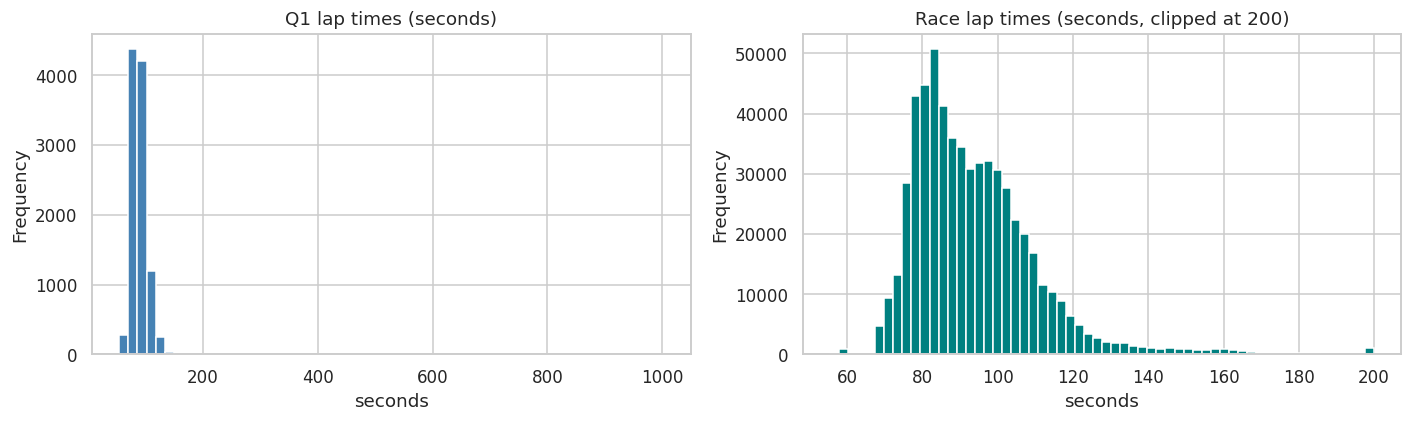

In [277]:
q = C["qualifying"][["q1", "q2", "q3"]]
print("Qualifying seconds:")
display(q.describe().T[["count", "min", "50%", "max"]])
print("Qualifying times outside [40s, 200s]:", int(((q < 40) | (q > 200)).sum().sum()))

lt = C["lap_times"]["time"]
print("\nLap times: min", round(lt.min(), 3), "| median", round(lt.median(), 3), "| max", round(lt.max(), 3))

print("\nDate ranges:")
print("races.date:", C["races"].date.min().date(), "->", C["races"].date.max().date())
print("drivers.dob:", C["drivers"].dob.min().date(), "->", C["drivers"].dob.max().date())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
C["qualifying"]["q1"].dropna().plot(kind="hist", bins=60, ax=axes[0], color="steelblue")
axes[0].set_title("Q1 lap times (seconds)"); axes[0].set_xlabel("seconds")
C["lap_times"]["time"].dropna().clip(upper=200).plot(kind="hist", bins=60, ax=axes[1], color="teal")
axes[1].set_title("Race lap times (seconds, clipped at 200)"); axes[1].set_xlabel("seconds")
plt.tight_layout(); plt.show()

In [278]:
def pk_ok(df, cols):
    cols = [cols] if isinstance(cols, str) else list(cols)
    return int(df.duplicated(subset=cols).sum()), int(df[cols].isna().any(axis=1).sum())

def fk_orphans(child, ccol, parent, pcol):
    c = child[ccol].dropna()
    return int((~c.isin(parent[pcol].dropna())).sum())

pk_after = {n: pk_ok(C[n], c) for n, c in pk_spec.items()}
pk_cmp = pd.DataFrame({
    "dups_before": {n: v[0] for n, v in pk_results_before.items()},
    "nulls_before": {n: v[1] for n, v in pk_results_before.items()},
    "dups_after": {n: v[0] for n, v in pk_after.items()},
    "nulls_after": {n: v[1] for n, v in pk_after.items()},
})
print("PRIMARY KEYS")
display(pk_cmp)

fk_after = {f"{c}.{cc} -> {p}.{pc}": fk_orphans(C[c], cc, C[p], pc) for c, cc, p, pc in fk_spec}
fk_cmp = pd.DataFrame({"orphans_before": fk_results_before, "orphans_after": fk_after})
print("FOREIGN KEYS")
display(fk_cmp)

print("Tables with PK problems:", [n for n, v in pk_after.items() if v != (0, 0)])
print("FKs with orphans:", [k for k, v in fk_after.items() if v > 0])

PRIMARY KEYS


,dups_before,nulls_before,dups_after,nulls_after
circuits,0,0,0,0
constructors,0,0,0,0
drivers,0,0,0,0
races,0,0,0,0
results,0,0,0,0
qualifying,0,0,0,0
status,0,0,0,0
seasons,0,0,0,0
sprint_results,0,0,0,0
constructor_results,0,0,0,0


FOREIGN KEYS


,orphans_before,orphans_after
results.raceId -> races.raceId,0,0
results.driverId -> drivers.driverId,0,0
results.constructorId -> constructors.constructorId,0,0
results.statusId -> status.statusId,0,0
qualifying.raceId -> races.raceId,0,0
qualifying.driverId -> drivers.driverId,0,0
qualifying.constructorId -> constructors.constructorId,0,0
races.circuitId -> circuits.circuitId,0,0
races.year -> seasons.year,0,0
driver_standings.raceId -> races.raceId,0,0


Tables with PK problems: []
FKs with orphans: []


In [279]:
R_full = C["results"].copy()
key = ["raceId", "driverId"]

dups = R_full[R_full.duplicated(key, keep=False)].merge(
    C["races"][["raceId", "year"]], on="raceId", how="left")

grp = dups.groupby(key).agg(
    n_rows=("resultId", "size"),
    n_started=("grid", lambda s: int((s > 0).sum())),
    n_constructors=("constructorId", "nunique"),
    n_podium_rows=("positionOrder", lambda s: int((s <= 3).sum())),
    year=("year", "first"),
)
print("Duplicate groups:", len(grp), "| rows involved:", len(dups),
      "| seasons:", int(grp.year.min()), "-", int(grp.year.max()))
display(grp.value_counts(["n_rows", "n_started", "n_constructors"]).rename("groups").to_frame())
print("Groups where more than one row is a podium row:", int((grp.n_podium_rows > 1).sum()))

cols = ["raceId", "year", "driverId", "constructorId", "grid", "position", "positionOrder", "points"]
display(dups.sort_values(key + ["resultId"])[cols].head(10))

Duplicate groups: 85 | rows involved: 176 | seasons: 1950 - 1978


groups
n_rows n_started n_constructors        
2      2         1                   66
                 2                   10
       0         2                    3
3      3         1                    3
                 2                    2
                 3                    1

Groups where more than one row is a podium row: 2


,raceId,year,driverId,constructorId,grid,position,positionOrder,points
0,540,1978,229,54,0,<NA>,26,0.0000
1,540,1978,229,57,0,<NA>,29,0.0000
2,717,1964,373,172,1,7,7,0.0000
175,717,1964,373,172,1,<NA>,12,0.0000
3,733,1962,465,172,0,<NA>,22,0.0000
4,733,1962,465,97,0,<NA>,25,0.0000
5,742,1961,475,102,20,<NA>,19,0.0000
6,742,1961,475,172,5,<NA>,21,0.0000
7,745,1961,418,172,11,<NA>,17,0.0000
174,745,1961,418,172,15,11,11,0.0000


## Grain rule: one row per (raceId, driverId)

**Rule:** keep the row for the car the driver **started** (`grid > 0`). If several rows qualify, keep the one with the best (lowest) grid, then the lowest `resultId` for determinism.

**Why:**
- The prediction is made at the cutoff, so the row kept should be the one that grid and qualifying information describe: the car the driver actually started.
- The rule uses only pre-race information. Choosing the row with the best `positionOrder` would use the outcome to pick the row, biasing labels toward podium.
- It is deterministic and reproducible.

**Sensitivity check:** the next cell counts how many labels would differ under the alternative rule (best `positionOrder`).

In [280]:
R = R_full.merge(
    C["races"][["raceId", "year", "round", "date", "circuitId", "name"]].rename(columns={"name": "race_name"}),
    on="raceId", how="left", validate="m:1")

R["_started"] = (R["grid"].fillna(0) > 0).astype(int)
R = R.sort_values(key + ["_started", "grid", "resultId"], ascending=[True, True, False, True, True])
kept = R.drop_duplicates(key, keep="first")
dropped = R.drop(kept.index)

print(f"Rows before: {len(R)} | kept: {len(kept)} | dropped: {len(dropped)}")
print("Dropped rows that were podium rows:", int((dropped.positionOrder <= 3).sum()))

alt = R.sort_values(key + ["positionOrder"]).drop_duplicates(key, keep="first")
cmp_ = kept[key + ["positionOrder"]].merge(alt[key + ["positionOrder"]], on=key, suffixes=("_ours", "_alt"))
n_label_diff = int(((cmp_.positionOrder_ours <= 3) != (cmp_.positionOrder_alt <= 3)).sum())
print("Podium labels that would differ under the 'best positionOrder' rule:", n_label_diff)

ledger = [{"step": "typed results (raw rows)", "rows_before": len(R_full), "rows_after": len(R_full)},
          {"step": "dedup (raceId, driverId)", "rows_before": len(R), "rows_after": len(kept)}]

Rows before: 26759 | kept: 26668 | dropped: 91
Dropped rows that were podium rows: 19
Podium labels that would differ under the 'best positionOrder' rule: 17


In [281]:
DROP_AFTER_LAST_SEASON = True
DROP_INDY500 = True
DROP_NON_STARTERS = True      # flip to False to run the "keep DNQ rows" experiment

S = kept.copy()

# Seasons beyond the brief's scope (1950-2024), in case the dataset copy contains newer races
before = len(S)
if DROP_AFTER_LAST_SEASON:
    S = S[S.year.astype(int) <= LAST_SEASON]
ledger.append({"step": f"drop seasons after {LAST_SEASON}", "rows_before": before, "rows_after": len(S)})

# Indianapolis 500 (1950-60): name match, not circuit, because the same speedway hosted the US GP in 2000-07
indy_mask = S.race_name.eq("Indianapolis 500")
print("Indy 500 races:", S[indy_mask].raceId.nunique(), "| rows:", int(indy_mask.sum()),
      "| years:", sorted(S[indy_mask].year.unique())[:3], "...")
before = len(S)
if DROP_INDY500:
    S = S[~indy_mask]
ledger.append({"step": "drop Indianapolis 500", "rows_before": before, "rows_after": len(S)})

# Non-starters: positionText F = failed to qualify, W = withdrew (no race start)
print("\npositionText codes among remaining rows:")
display(S.positionText.where(~S.positionText.str.fullmatch(r"\d+"), "numeric").value_counts().to_frame("rows"))

ns_mask = S.positionText.isin(["F", "W"])
ns_by_era = S.assign(ns=ns_mask, era=S.year.astype(int).map(era_of)).groupby("era").ns.agg(["sum", "mean"])
display(ns_by_era.reindex([e[2] for e in ERAS]).rename(columns={"sum": "non_starters", "mean": "share"}))
print("Podium rows among non-starters (should be 0):", int((S[ns_mask].positionOrder <= 3).sum()))

before = len(S)
if DROP_NON_STARTERS:
    S = S[~ns_mask]
ledger.append({"step": "drop non-starters (F, W)", "rows_before": before, "rows_after": len(S)})

Indy 500 races: 11 | rows: 381 | years: [np.int64(1950), np.int64(1951), np.int64(1952)] ...

positionText codes among remaining rows:


,rows
positionText,
numeric,15544
R,8694
F,1366
W,335
N,190
D,149
E,9


,non_starters,share
era,,
1950-57 front-engine,56,0.0464
1958-65 rear-engine,219,0.1318
1966-76 3L and wings,187,0.0578
1977-88 turbo/ground effect,577,0.1103
1989-94 post-turbo,555,0.1829
1995-2008 V10/V8,64,0.0125
2009-13 late V8,15,0.0070
2014-21 hybrid,21,0.0064
2022-24 ground effect,7,0.0052


Podium rows among non-starters (should be 0): 0


In [282]:
results_clean = (S.drop(columns=["_started"])
                   .sort_values(["year", "round", "raceId", "resultId"])
                   .reset_index(drop=True))
results_clean["podium"] = (results_clean["positionOrder"] <= 3).astype(int)
results_clean["era"] = results_clean["year"].astype(int).map(era_of)

assert not results_clean.duplicated(["raceId", "driverId"]).any(), "grain not unique"
assert results_clean["positionOrder"].notna().all(), "positionOrder has missing values"
assert results_clean["raceId"].isin(C["races"]["raceId"]).all(), "orphan raceId"

print("Final shape:", results_clean.shape)
print("Races:", results_clean.raceId.nunique(), "| drivers:", results_clean.driverId.nunique(),
      "| seasons:", int(results_clean.year.min()), "-", int(results_clean.year.max()))
print("Podium rate:", round(results_clean.podium.mean(), 4))
display(pd.DataFrame(ledger).assign(removed=lambda d: d.rows_before - d.rows_after))

Final shape: (24586, 25)
Races: 1114 | drivers: 683 | seasons: 1950 - 2024
Podium rate: 0.1359


,step,rows_before,rows_after,removed
0,typed results (raw rows),26759,26759,0
1,"dedup (raceId, driverId)",26759,26668,91
2,drop seasons after 2024,26668,26668,0
3,drop Indianapolis 500,26668,26287,381
4,"drop non-starters (F, W)",26287,24586,1701


,before,after
2,0,3
3,1107,1109
4,16,1
5,1,1
7,1,0


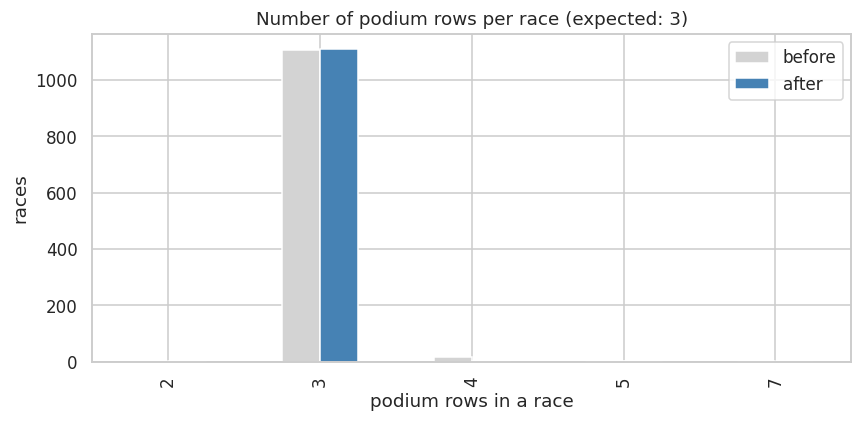

Races without exactly 3 podium rows after cleaning: 5


,year,name,podium_rows
raceId,,,
780,1957,British Grand Prix,2
789,1956,British Grand Prix,2
792,1955,Argentine Grand Prix,5
793,1955,Monaco Grand Prix,4
828,1951,French Grand Prix,2


In [283]:
pods_before = R_full.assign(p=(R_full.positionOrder <= 3)).groupby("raceId").p.sum()
pods_after = results_clean.groupby("raceId").podium.sum()

cmp_p = pd.DataFrame({"before": pods_before.value_counts(), "after": pods_after.value_counts()}).fillna(0).astype(int).sort_index()
display(cmp_p)

cmp_p.plot(kind="bar", figsize=(8, 4), color=["lightgray", "steelblue"])
plt.title("Number of podium rows per race (expected: 3)")
plt.xlabel("podium rows in a race"); plt.ylabel("races")
plt.tight_layout(); plt.show()

odd = pods_after[pods_after != 3]
print("Races without exactly 3 podium rows after cleaning:", len(odd))
display(C["races"].set_index("raceId").loc[odd.index, ["year", "name"]].assign(podium_rows=odd).head(10))

In [284]:
qual = C["qualifying"]
print("Qualifying duplicate (raceId, driverId):", int(qual.duplicated(["raceId", "driverId"]).sum()))
print("Qualifying rows without a matching results row:",
      int((~qual.set_index(["raceId", "driverId"]).index.isin(
          R_full.set_index(["raceId", "driverId"]).index)).sum()))

print("\ngrid < 0:", int((results_clean.grid < 0).sum()), "| grid missing:", int(results_clean.grid.isna().sum()))
print("grid == 0 rows remaining (pit-lane starts etc.):", int((results_clean.grid == 0).sum()))
print("Races per season with fewer than 6 starters:",
      int((results_clean.groupby("raceId").size() < 6).sum()))

Qualifying duplicate (raceId, driverId): 0
Qualifying rows without a matching results row: 0

grid < 0: 0 | grid missing: 0
grid == 0 rows remaining (pit-lane starts etc.): 87
Races per season with fewer than 6 starters: 0


,before,after
results_rows,"26,759.0000","24,586.0000"
dup_extra_rows,91.0000,0.0000
grid_zero_rows,"1,638.0000",87.0000
podium_rate,0.1269,0.1359
sentinel_cols,30.0000,0.0000
quali_cov_overall,0.3922,0.4237
pk_problems,0.0000,0.0000
fk_problems,0.0000,0.0000


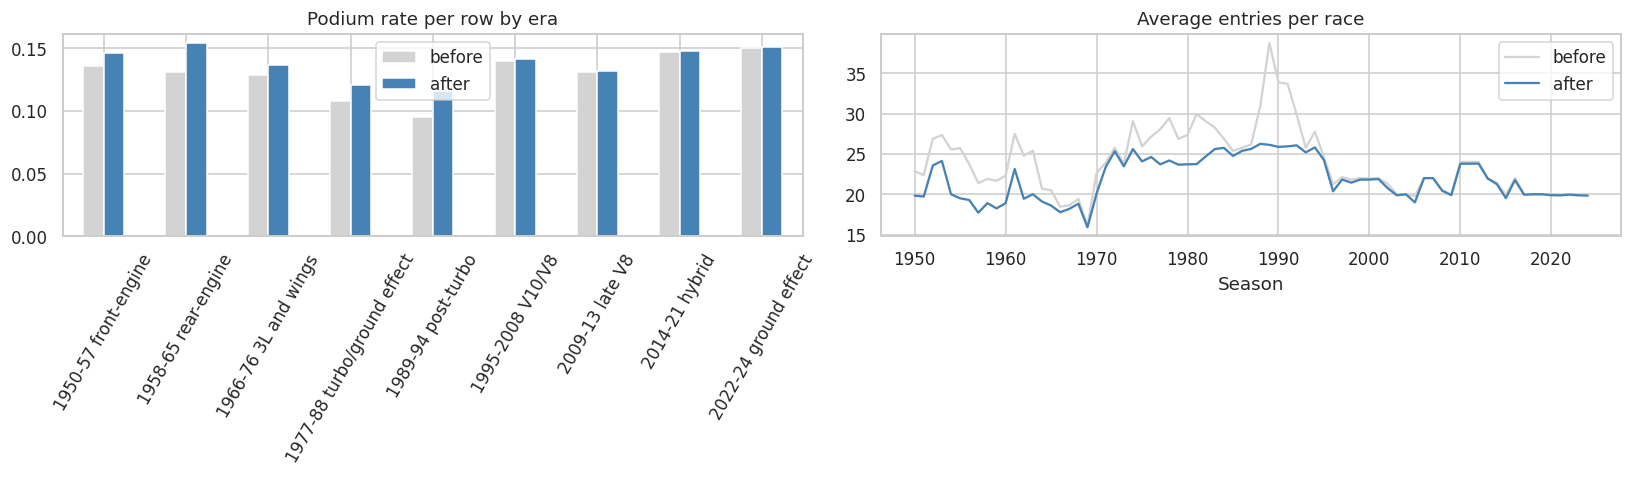

In [285]:
qkeys_c = set(zip(C["qualifying"].raceId, C["qualifying"].driverId))
cov_after = np.mean([(r, d) in qkeys_c for r, d in zip(results_clean.raceId, results_clean.driverId)])

AFTER = {
    "results_rows": len(results_clean),
    "dup_extra_rows": int(results_clean.duplicated(["raceId", "driverId"]).sum()),
    "grid_zero_rows": int((results_clean.grid == 0).sum()),
    "podium_rate": float(results_clean.podium.mean()),
    "sentinel_cols": int(sum((C[t].astype(str) == SENTINEL).any().sum() for t in C)),
    "quali_cov_overall": float(cov_after),
    "pk_problems": sum(1 for v in pk_after.values() if v != (0, 0)),
    "fk_problems": sum(1 for v in fk_after.values() if v > 0),
}
display(pd.DataFrame({"before": BEFORE, "after": AFTER}))

order = [e[2] for e in ERAS]
era_b = eda.groupby("era").podium.mean().reindex(order)
era_a = results_clean.groupby("era").podium.mean().reindex(order)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
pd.DataFrame({"before": era_b, "after": era_a}).plot(kind="bar", ax=axes[0], color=["lightgray", "steelblue"])
axes[0].set_title("Podium rate per row by era"); axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=60)

fs_b = eda.groupby("year").size() / eda.groupby("year").raceId.nunique()
fs_a = results_clean.groupby("year").size() / results_clean.groupby("year").raceId.nunique()
axes[1].plot(fs_b.index, fs_b.values, color="lightgray", label="before")
axes[1].plot(fs_a.index, fs_a.values, color="steelblue", label="after")
axes[1].set_title("Average entries per race"); axes[1].set_xlabel("Season"); axes[1].legend()
plt.tight_layout(); plt.show()

In [286]:
# Typed copy of every results row, kept for Q3 (status analysis) before any scope filtering
results_typed_full = R_full.copy()

# Raw immutability check: sentinels must still be present as strings in RAW, and no column was retyped
assert (RAW["results"] == SENTINEL).any().any(), "RAW appears modified"
assert all(pd.api.types.is_object_dtype(t) or pd.api.types.is_string_dtype(t)
           for df in RAW.values() for t in df.dtypes), "RAW dtypes changed"
print("RAW tables unchanged.")

OUT = Path("/kaggle/working/clean") if Path("/kaggle/working").exists() else Path("./clean")
OUT.mkdir(parents=True, exist_ok=True)
results_clean.to_csv(OUT / "results_clean.csv", index=False)
pd.DataFrame(ledger).to_csv(OUT / "cleaning_ledger.csv", index=False)
print("Saved to", OUT)

RAW tables unchanged.
Saved to /kaggle/working/clean


## Cleaning decisions and evidence
| Issue | Evidence | Decision | Impact |
|---|---|---|---|
| `\N` sentinels | 30 columns affected; 122,887 in `results` alone (mostly post-race fields) | Replaced with NaN in every table, empty strings too | 160,076 values replaced; 0 sentinels remain |
| Semantic typing | Conversion log: 94 columns typed, only 1 lost values | ints, floats, dates, clock times; lap and qualifying times converted to seconds; `results.time` kept as text because it is post-race | 43 of 589,081 lap times (0.007%) could not be parsed (laps over one hour, red-flag restarts) and became NaN; they are never used as features |
| Outliers | Qualifying times range 53.9-1,002.6 s; 1 value outside 40-200 s | Kept in the tables; neutralised later by winsorising (Section 6) | 1 value |
| Duplicate (raceId, driverId) | 85 groups, 91 extra rows, seasons 1950-1978 | Keep the started car (grid > 0), then best grid, then lowest `resultId` | 91 rows removed (26,759 to 26,668); 19 removed rows were podium rows; 17 podium labels would differ under the "best positionOrder" rule; 5 races end without exactly 3 podium rows (1951 French, 1955 Argentine, 1955 Monaco, 1956 and 1957 British), all outside the modeled window |
| Seasons after 2024 | Dataset ends in 2024 | Filter in place (flag) | 0 rows |
| Indianapolis 500 (1950-60) | 11 races, 381 rows | Excluded: almost no regular F1 entrants, distorts home-race analysis | 381 rows |
| Non-starters (positionText F or W) | 1,366 F and 335 W rows; 18.3% of rows in 1989-94; 0 podium rows | Excluded: they never started (flag `DROP_NON_STARTERS`) | 1,701 rows; podium rate moves from 12.7% to 13.6% |
| PK/FK | 14 primary keys and 22 foreign keys checked before and after | All unique, non-null and reconciled | 0 problems |

Final table: 24,586 rows, 1,114 races, 683 drivers, seasons 1950-2024. Grid-0 rows fall from 1,638 to 87 and qualifying coverage of the remaining rows rises from 39.2% to 42.4%.

# 4. Data-Engineering Questions

| Q | Grain | Joins |
|---|---|---|
| Q1 | one driver-race (front-row starters only) | results_clean, qualifying, races, circuits |
| Q2 | one driver-race (grid > 0) | results_clean, drivers, races, circuits, nationality-to-country map |
| Q3 | one car start (driver-race) | results_clean, status, constructors, races |

Each answer gives the result, a plot, and a note on grain, missingness and the pre-race cutoff.

In [287]:
FIG_DIR = Path("/kaggle/working/figures") if Path("/kaggle/working").exists() else Path("./figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

def wilson(k, n, z=1.96):
    """95% Wilson interval for a proportion."""
    k = np.asarray(k, float); n = np.asarray(n, float)
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half

circ = C["circuits"][["circuitId", "name", "country"]].rename(
    columns={"name": "circuit_name", "country": "circuit_country"})
drv = C["drivers"][["driverId", "forename", "surname", "nationality"]].copy()
drv["driver_name"] = drv.forename + " " + drv.surname
qual = (C["qualifying"][["raceId", "driverId", "position"]]
        .rename(columns={"position": "quali_pos"})
        .drop_duplicates(["raceId", "driverId"]))

base = (results_clean
        .merge(circ, on="circuitId", how="left", validate="m:1")
        .merge(drv[["driverId", "driver_name", "nationality"]], on="driverId", how="left", validate="m:1")
        .merge(qual, on=["raceId", "driverId"], how="left", validate="m:1"))
for c in ["year", "grid", "quali_pos", "positionOrder"]:
    base[c] = base[c].astype(float)
base["year"] = base["year"].astype(int)

assert len(base) == len(results_clean), "a join changed the row count"
print("Base table:", base.shape)
print("Rows with qualifying position:", int(base.quali_pos.notna().sum()))

Base table: (24586, 30)
Rows with qualifying position: 10418


## Q1: Front-row start to podium conversion by circuit

**Definitions**
- *Front row by grid:* `grid` in {1, 2}. This is the actual start after penalties. `grid = 0` (pit-lane start) is not a front-row start.
- *Front row by qualifying:* `qualifying.position` in {1, 2}. This is the raw session result before penalties.
- *Conversion rate:* share of front-row starters who finish `positionOrder <= 3`.

**Periods:** before 2014 (starting at the first season with >= 90% qualifying coverage from Section 2) versus 2014-2024. The pre-period starts there so both definitions can be computed on the same rows and early-era reliability does not drive the comparison.

**Cutoff:** grid and qualifying position are both known before the race. The podium flag is the target only.

Seasons 1995-2024: 11807 rows; kept 10029 with a qualifying position (1778 dropped for missing qualifying)


,grid_front_row_starts,grid_conversion,quali_front_row_starts,quali_conversion
period,,,,
1995-2013,500,0.6560,500,0.6500
2014-2024,453,0.7616,454,0.7401


,period,start_group,rows,podium_rate
0,1995-2013,front row in both,491,0.6578
1,1995-2013,"grid front row, quali behind",9,0.5556
2,1995-2013,neither,4936,0.0857
3,1995-2013,"quali front row, grid pushed back",9,0.2222
4,2014-2024,front row in both,426,0.7676
5,2014-2024,"grid front row, quali behind",27,0.6667
6,2014-2024,neither,4103,0.0804
7,2014-2024,"quali front row, grid pushed back",28,0.3214


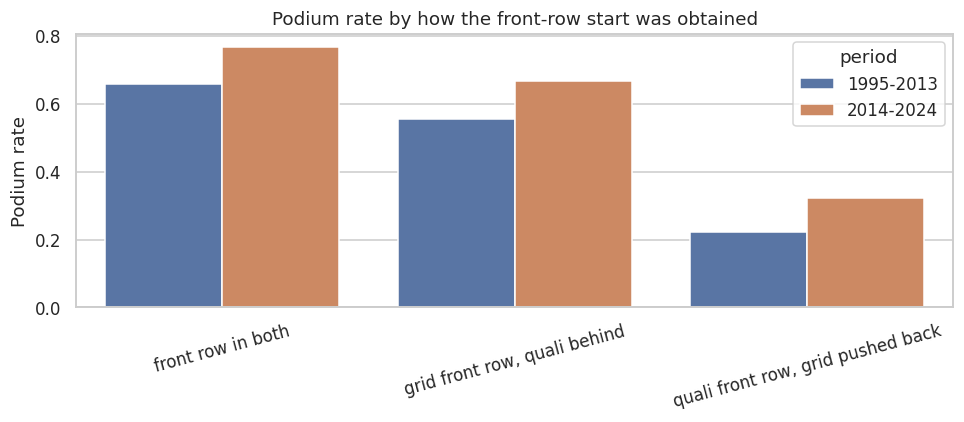

In [288]:
PRE_START = int(cov[cov >= 0.9].index.min()) if (cov >= 0.9).any() else 1996
MIN_FR = 15   # minimum front-row starts per circuit in each period
pre_label = f"{PRE_START}-2013"

q1 = base[base.year >= PRE_START].copy()
n_all = len(q1)
q1 = q1[q1.quali_pos.notna()].copy()    # same rows for both definitions
print(f"Seasons {PRE_START}-2024: {n_all} rows; kept {len(q1)} with a qualifying position "
      f"({n_all - len(q1)} dropped for missing qualifying)")

q1["period"] = np.where(q1.year >= 2014, "2014-2024", pre_label)
q1["fr_grid"] = (q1.grid >= 1) & (q1.grid <= 2)
q1["fr_quali"] = q1.quali_pos <= 2

pooled = pd.DataFrame({
    "grid_front_row_starts": q1[q1.fr_grid].groupby("period").size(),
    "grid_conversion": q1[q1.fr_grid].groupby("period").podium.mean(),
    "quali_front_row_starts": q1[q1.fr_quali].groupby("period").size(),
    "quali_conversion": q1[q1.fr_quali].groupby("period").podium.mean(),
})
display(pooled)

q1["start_group"] = np.select(
    [q1.fr_quali & q1.fr_grid, q1.fr_quali & ~q1.fr_grid, ~q1.fr_quali & q1.fr_grid],
    ["front row in both", "quali front row, grid pushed back", "grid front row, quali behind"],
    default="neither")
grp = (q1.groupby(["period", "start_group"]).podium.agg(rows="size", podium_rate="mean").reset_index())
display(grp)

fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=grp[grp.start_group != "neither"], x="start_group", y="podium_rate", hue="period", ax=ax)
ax.set_title("Podium rate by how the front-row start was obtained")
ax.set_xlabel(""); ax.set_ylabel("Podium rate")
plt.xticks(rotation=15); plt.tight_layout(); save_fig("q1_penalty_groups"); plt.show()

Circuits with >= 15 front-row starts in both periods: 11
Rank correlation between periods (Spearman): 0.25

Top 10 circuits, 2014-2024:


,circuit_name,starts_pre,rate_pre,starts_post,rate_post,rank_pre,rank_post,rank_change
3,Circuit de Monaco,28,0.7143,19,0.8947,2.0000,1.0000,1.0000
10,Suzuka Circuit,24,0.7500,18,0.8889,1.0000,2.0000,-1.0000
2,Circuit de Barcelona-Catalunya,28,0.6429,22,0.8182,6.0000,3.0000,3.0000
7,Circuit de Spa-Francorchamps,22,0.5909,22,0.8182,9.0000,3.0000,6.0000
9,Autódromo José Carlos Pace,32,0.5938,19,0.7895,8.0000,5.0000,3.0000
4,Circuit Gilles Villeneuve,24,0.5417,18,0.7778,10.0000,6.0000,4.0000
5,Silverstone Circuit,30,0.6333,24,0.7500,7.0000,7.0000,0.0000
8,Autodromo Nazionale di Monza,24,0.7083,22,0.7273,3.0000,8.0000,-5.0000
0,Albert Park Grand Prix Circuit,32,0.5312,18,0.7222,11.0000,9.0000,2.0000
1,Bahrain International Circuit,18,0.6667,24,0.6667,4.0000,10.0000,-6.0000


Top 10 circuits, pre-2014:


,circuit_name,starts_pre,rate_pre,starts_post,rate_post,rank_pre,rank_post,rank_change
10,Suzuka Circuit,24,0.7500,18,0.8889,1.0000,2.0000,-1.0000
3,Circuit de Monaco,28,0.7143,19,0.8947,2.0000,1.0000,1.0000
8,Autodromo Nazionale di Monza,24,0.7083,22,0.7273,3.0000,8.0000,-5.0000
1,Bahrain International Circuit,18,0.6667,24,0.6667,4.0000,10.0000,-6.0000
6,Hungaroring,24,0.6667,22,0.5909,4.0000,11.0000,-7.0000
2,Circuit de Barcelona-Catalunya,28,0.6429,22,0.8182,6.0000,3.0000,3.0000
5,Silverstone Circuit,30,0.6333,24,0.7500,7.0000,7.0000,0.0000
9,Autódromo José Carlos Pace,32,0.5938,19,0.7895,8.0000,5.0000,3.0000
7,Circuit de Spa-Francorchamps,22,0.5909,22,0.8182,9.0000,3.0000,6.0000
4,Circuit Gilles Villeneuve,24,0.5417,18,0.7778,10.0000,6.0000,4.0000


Biggest movers:


,circuit_name,starts_pre,rate_pre,starts_post,rate_post,rank_pre,rank_post,rank_change
7,Circuit de Spa-Francorchamps,22,0.5909,22,0.8182,9.0000,3.0000,6.0000
4,Circuit Gilles Villeneuve,24,0.5417,18,0.7778,10.0000,6.0000,4.0000
2,Circuit de Barcelona-Catalunya,28,0.6429,22,0.8182,6.0000,3.0000,3.0000
9,Autódromo José Carlos Pace,32,0.5938,19,0.7895,8.0000,5.0000,3.0000
0,Albert Park Grand Prix Circuit,32,0.5312,18,0.7222,11.0000,9.0000,2.0000
6,Hungaroring,24,0.6667,22,0.5909,4.0000,11.0000,-7.0000
1,Bahrain International Circuit,18,0.6667,24,0.6667,4.0000,10.0000,-6.0000
8,Autodromo Nazionale di Monza,24,0.7083,22,0.7273,3.0000,8.0000,-5.0000
10,Suzuka Circuit,24,0.7500,18,0.8889,1.0000,2.0000,-1.0000
5,Silverstone Circuit,30,0.6333,24,0.7500,7.0000,7.0000,0.0000


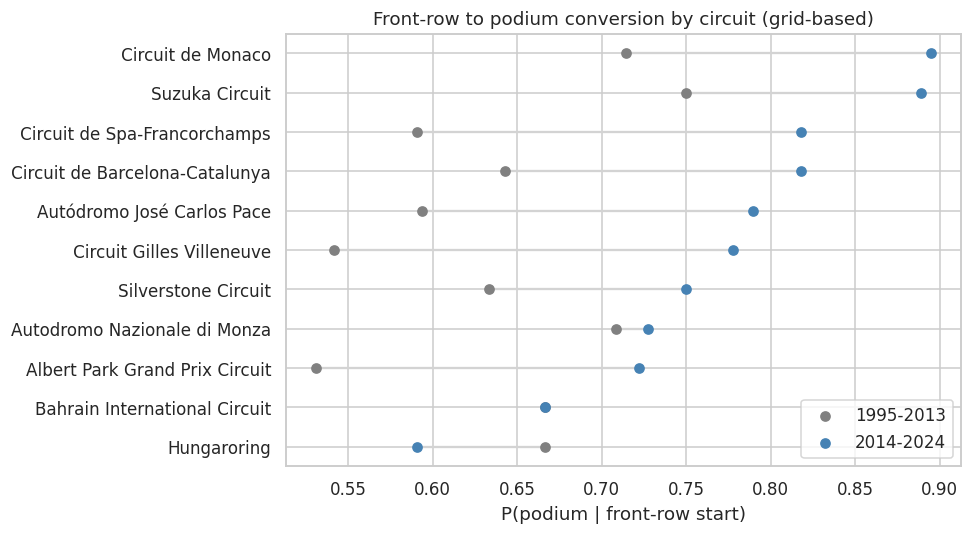

In [289]:
def circuit_conversion(df, flag):
    sub = df[df[flag]]
    g = (sub.groupby(["circuitId", "circuit_name", "period"])
            .agg(starts=("podium", "size"), podiums=("podium", "sum")).reset_index())
    g["rate"] = g.podiums / g.starts
    pre = g[g.period == pre_label].set_index("circuitId")
    post = g[g.period == "2014-2024"].set_index("circuitId")
    w = pre[["circuit_name", "starts", "rate"]].join(
        post[["starts", "rate"]], lsuffix="_pre", rsuffix="_post", how="inner")
    w = w[(w.starts_pre >= MIN_FR) & (w.starts_post >= MIN_FR)].copy()
    w["rank_pre"] = w.rate_pre.rank(ascending=False, method="min")
    w["rank_post"] = w.rate_post.rank(ascending=False, method="min")
    w["rank_change"] = w.rank_pre - w.rank_post      # positive = moved up
    return g, w.reset_index()

def plot_q1(w, label, fname):
    w = w.sort_values("rate_post")
    y = np.arange(len(w))
    fig, ax = plt.subplots(figsize=(9, max(4, 0.32 * len(w) + 1.5)))
    ax.hlines(y, w.rate_pre, w.rate_post, color="lightgray", zorder=1)
    ax.scatter(w.rate_pre, y, color="gray", label=pre_label, zorder=2)
    ax.scatter(w.rate_post, y, color="steelblue", label="2014-2024", zorder=2)
    ax.set_yticks(y); ax.set_yticklabels(w.circuit_name)
    ax.set_xlabel("P(podium | front-row start)")
    ax.set_title(f"Front-row to podium conversion by circuit ({label})")
    ax.legend(loc="lower right")
    plt.tight_layout(); save_fig(fname); plt.show()

g_grid, w_grid = circuit_conversion(q1, "fr_grid")
print(f"Circuits with >= {MIN_FR} front-row starts in both periods: {len(w_grid)}")
rho = w_grid.rate_pre.rank().corr(w_grid.rate_post.rank())
print(f"Rank correlation between periods (Spearman): {rho:.2f}")

cols = ["circuit_name", "starts_pre", "rate_pre", "starts_post", "rate_post", "rank_pre", "rank_post", "rank_change"]
print("\nTop 10 circuits, 2014-2024:")
display(w_grid.sort_values("rate_post", ascending=False).head(10)[cols])
print("Top 10 circuits, pre-2014:")
display(w_grid.sort_values("rate_pre", ascending=False).head(10)[cols])
print("Biggest movers:")
display(pd.concat([w_grid.nlargest(5, "rank_change"), w_grid.nsmallest(5, "rank_change")])[cols])

plot_q1(w_grid, "grid-based", "q1_grid_dumbbell")

Circuits kept: 11 | Spearman between periods (qualifying-based): 0.24
Top 10 circuits 2014-2024, qualifying-based:


,circuit_name,starts_pre,rate_pre,starts_post,rate_post,rank_pre,rank_post,rank_change
3,Circuit de Monaco,28,0.6429,19,0.8947,5.0000,1.0000,4.0000
10,Suzuka Circuit,24,0.7500,18,0.8889,1.0000,2.0000,-1.0000
2,Circuit de Barcelona-Catalunya,28,0.6071,22,0.8182,7.0000,3.0000,4.0000
7,Circuit de Spa-Francorchamps,22,0.5909,22,0.8182,9.0000,3.0000,6.0000
5,Silverstone Circuit,30,0.6667,24,0.7500,2.0000,5.0000,-3.0000
8,Autodromo Nazionale di Monza,24,0.6667,22,0.7273,2.0000,6.0000,-4.0000
0,Albert Park Grand Prix Circuit,32,0.5312,18,0.7222,11.0000,7.0000,4.0000
4,Circuit Gilles Villeneuve,24,0.5417,18,0.7222,10.0000,7.0000,3.0000
9,Autódromo José Carlos Pace,32,0.5938,19,0.6842,8.0000,9.0000,-1.0000
1,Bahrain International Circuit,18,0.6667,24,0.6667,2.0000,10.0000,-8.0000


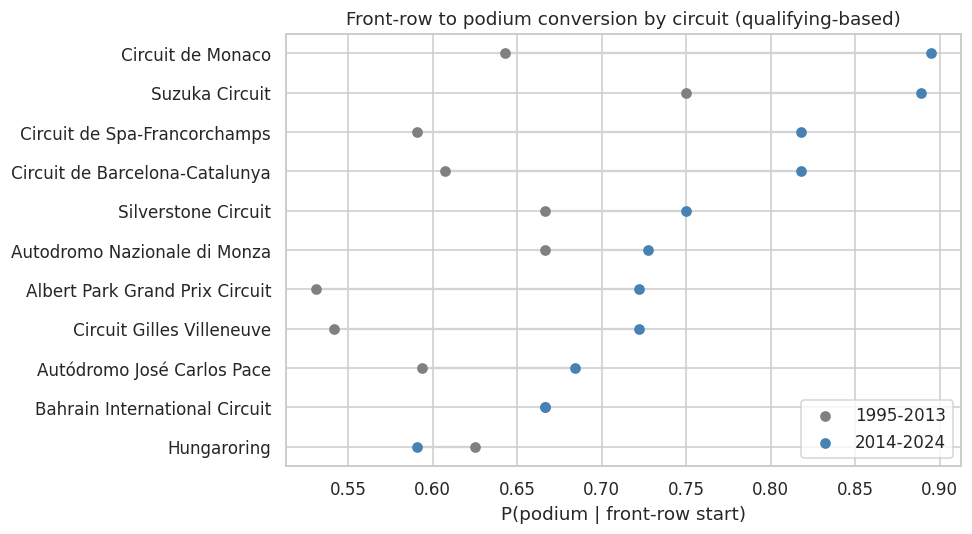

Grid vs qualifying definition, 2014-2024 (largest gaps):


,circuitId,circuit_name,rate_post_grid,rate_post_quali,gap
9,18,Autódromo José Carlos Pace,0.7895,0.6842,0.1053
4,7,Circuit Gilles Villeneuve,0.7778,0.7222,0.0556
0,1,Albert Park Grand Prix Circuit,0.7222,0.7222,0.0000
2,4,Circuit de Barcelona-Catalunya,0.8182,0.8182,0.0000
1,3,Bahrain International Circuit,0.6667,0.6667,0.0000
5,9,Silverstone Circuit,0.7500,0.7500,0.0000
3,6,Circuit de Monaco,0.8947,0.8947,0.0000
6,11,Hungaroring,0.5909,0.5909,0.0000


Rank correlation between the two definitions (2014-2024): 0.87


In [290]:
g_q, w_q = circuit_conversion(q1, "fr_quali")
rho_q = w_q.rate_pre.rank().corr(w_q.rate_post.rank())
print(f"Circuits kept: {len(w_q)} | Spearman between periods (qualifying-based): {rho_q:.2f}")

print("Top 10 circuits 2014-2024, qualifying-based:")
display(w_q.sort_values("rate_post", ascending=False).head(10)[cols])
plot_q1(w_q, "qualifying-based", "q1_quali_dumbbell")

cmp_ = (w_grid[["circuitId", "circuit_name", "rate_post"]]
        .merge(w_q[["circuitId", "rate_post"]], on="circuitId", suffixes=("_grid", "_quali")))
cmp_["gap"] = cmp_.rate_post_grid - cmp_.rate_post_quali
print("Grid vs qualifying definition, 2014-2024 (largest gaps):")
display(cmp_.reindex(cmp_.gap.abs().sort_values(ascending=False).index).head(8))
print("Rank correlation between the two definitions (2014-2024):",
      round(cmp_.rate_post_grid.rank().corr(cmp_.rate_post_quali.rank()), 2))

### Q1 answer
- **Pooled:** front-row starters (by grid) converted 65.6% of 500 starts in 1995-2013 and 76.2% of 453 starts in 2014-2024. By qualifying position the rates are 65.0% and 74.0%.
- **Top circuits (2014-2024, grid-based):** Monaco 89.5% (19 starts), Suzuka 88.9% (18), Barcelona-Catalunya 81.8% (22), Spa-Francorchamps 81.8% (22), Interlagos 78.9% (19). Lowest: Hungaroring 59.1% (22) and the Bahrain circuit 66.7% (24).
- **Did the ranking change?** Yes, a lot: the Spearman rank correlation between the two periods is 0.25 over 11 circuits. Biggest movers up: Spa (9th to 3rd, 59% to 82%), Gilles Villeneuve (+4 places), Barcelona and Interlagos (+3 each). Down: Hungaroring (4th to 11th, 66.7% to 59.1%), Bahrain (4th to 10th) and Monza (3rd to 8th). Monaco and Suzuka stay at the top.
- **Grid vs qualifying:** drivers on the qualifying front row but pushed back by penalties converted 22.2% (9 rows) in 1995-2013 and 32.1% (28 rows) in 2014-2024, against 65.8% (491) and 76.8% (426) for those who kept the front row. Drivers on the grid front row but behind in qualifying converted 55.6% (9) and 66.7% (27). The two definitions give almost the same circuit ranking (Spearman 0.87 in 2014-2024); the largest differences are Interlagos (78.9% by grid vs 68.4% by qualifying) and Gilles Villeneuve (77.8% vs 72.2%).
- **Grain:** one row per driver-race, front-row starters only. **Missingness:** 1,778 of 11,807 rows from 1995-2024 (15%) had no qualifying position and were dropped, so both definitions use the same rows; only 11 circuits had at least 15 front-row starts in both periods. **Cutoff:** grid and qualifying position are known before the race; the podium flag is the target.
- **Caveat:** each circuit has only 18-32 front-row starts per period, so one podium is worth 3-5 points and a Spearman correlation over 11 circuits is very uncertain. The penalty groups have only 9-28 rows.

## Q2: Home-country advantage, controlling for grid position

**Home race:** the driver's nationality maps to the circuit's country (map below, documented). Nationality is the driver's passport, not residence.

**Control:** grid position, by (a) stratifying on grid bins and pooling with a Mantel-Haenszel odds ratio, and (b) logistic regression with grid bins and era as covariates, clustered by driver.

**Sample:** `grid >= 1` only (pit-lane starts have no meaningful grid slot) and drivers whose nationality has at least one host country in the data, so home and away are compared within a comparable pool. The Indy 500 was already excluded in Section 3.

In [291]:
NAT_TO_COUNTRY = {
    "American": ["USA", "United States"], "American-Italian": ["USA", "United States", "Italy"],    "Argentine": ["Argentina"], "Argentinian": ["Argentina"], "Argentine-Italian": ["Argentina", "Italy"],
    "Australian": ["Australia"], "Austrian": ["Austria"], "Belgian": ["Belgium"],
    "Brazilian": ["Brazil"], "British": ["UK"], "Canadian": ["Canada"], "Chinese": ["China"],
    "Dutch": ["Netherlands"], "French": ["France"], "Corsican": ["France"],
    "German": ["Germany"], "East German": ["Germany"], "Hungarian": ["Hungary"],
    "Indian": ["India"], "Italian": ["Italy"], "Japanese": ["Japan"], "Malaysian": ["Malaysia"],
    "Mexican": ["Mexico"], "Monegasque": ["Monaco"], "Portuguese": ["Portugal"],
    "Russian": ["Russia"], "South African": ["South Africa"], "Spanish": ["Spain"],
    "Swedish": ["Sweden"], "Swiss": ["Switzerland"], "Turkish": ["Turkey"],
}

circuit_countries = set(base.circuit_country.dropna())
mapped_countries = set().union(*NAT_TO_COUNTRY.values())
print("Host countries in the data with NO nationality mapped (check for typos):",
      sorted(circuit_countries - mapped_countries))
print("Mapped countries that never hosted a race:", sorted(mapped_countries - circuit_countries))

unmapped = (base[~base.nationality.isin(NAT_TO_COUNTRY)]
            .groupby("nationality").driverId.nunique().sort_values(ascending=False))
print("\nNationalities with no home circuit (treated as never racing at home):")
display(unmapped.to_frame("drivers").T)
print("Check this list: any nationality that should map to a host country is a mistake in the dictionary.")

Host countries in the data with NO nationality mapped (check for typos): ['Azerbaijan', 'Bahrain', 'Korea', 'Morocco', 'Qatar', 'Saudi Arabia', 'Singapore', 'UAE']
Mapped countries that never hosted a race: []

Nationalities with no home circuit (treated as never racing at home):


nationality,New Zealander,Finnish,Danish,Irish,Uruguayan,Venezuelan,Colombian,Thai,Rhodesian,Argentinian,Chilean,Indonesian,Czech,Polish,Liechtensteiner
drivers,10,8,4,4,3,3,2,2,2,1,1,1,1,1,1


Check this list: any nationality that should map to a host country is a mistake in the dictionary.


In [292]:
base["home"] = [cc in NAT_TO_COUNTRY.get(nat, []) for cc, nat in zip(base.circuit_country, base.nationality)]
hosted = set(base.circuit_country.dropna())
elig_nat = {n for n, cs in NAT_TO_COUNTRY.items() if set(cs) & hosted}
base["eligible"] = base.nationality.isin(elig_nat)

n0 = len(base)
q2 = base[(base.grid >= 1) & base.eligible].copy()
print(f"Rows: {n0} -> {len(q2)} after grid >= 1 and eligible nationality")
print(f"Pit-lane/no-grid rows excluded: {int((base.grid == 0).sum())}")
print(f"Home rows: {int(q2.home.sum())} | drivers with a home race: {q2[q2.home].driverId.nunique()}")

q2["grid_bin"] = pd.cut(q2.grid, bins=[0, 1, 2, 4, 6, 10, 15, 100],
                        labels=["1", "2", "3-4", "5-6", "7-10", "11-15", "16+"])
q2["home_i"] = q2.home.astype(int)

raw = q2.groupby("home").agg(rows=("podium", "size"), podium_rate=("podium", "mean"),
                             mean_grid=("grid", "mean"), median_grid=("grid", "median"))
display(raw)
print("Home drivers start higher up the grid, so the raw gap overstates the effect:",
      raw.loc[True, "mean_grid"] < raw.loc[False, "mean_grid"])

Rows: 24586 -> 22167 after grid >= 1 and eligible nationality
Pit-lane/no-grid rows excluded: 87
Home rows: 1928 | drivers with a home race: 501


,rows,podium_rate,mean_grid,median_grid
home,,,,
False,20239,0.1361,11.7740,12.0000
True,1928,0.1162,12.6535,13.0000


Home drivers start higher up the grid, so the raw gap overstates the effect: False


In [293]:
rows = []
for gb, g in q2.groupby("grid_bin", observed=True):
    h, a_ = g[g.home], g[~g.home]
    rows.append({"grid_bin": gb, "home_n": len(h), "home_podiums": int(h.podium.sum()),
                 "away_n": len(a_), "away_podiums": int(a_.podium.sum())})
st = pd.DataFrame(rows)
st["home_rate"] = st.home_podiums / st.home_n
st["away_rate"] = st.away_podiums / st.away_n
display(st)

s = st[(st.home_n > 0) & (st.away_n > 0)].copy()
a = s.home_podiums; b = s.home_n - s.home_podiums
c = s.away_podiums; d = s.away_n - s.away_podiums
n = s.home_n + s.away_n

or_mh = (a * d / n).sum() / (b * c / n).sum()
w_rd = s.home_n * s.away_n / n
rd_mh = (((s.home_rate - s.away_rate) * w_rd).sum()) / w_rd.sum()
print(f"Mantel-Haenszel odds ratio (home vs away, grid-matched): {or_mh:.2f}")
print(f"Weighted podium-rate difference: {rd_mh * 100:+.1f} percentage points")

,grid_bin,home_n,home_podiums,away_n,away_podiums,home_rate,away_rate
0,1,83,49,945,615,0.5904,0.6508
1,2,77,42,916,524,0.5455,0.5721
2,3-4,144,64,1811,717,0.4444,0.3959
3,5-6,152,33,1794,394,0.2171,0.2196
4,7-10,335,24,3660,327,0.0716,0.0893
5,11-15,414,10,4615,131,0.0242,0.0284
6,16+,723,2,6498,47,0.0028,0.0072


Mantel-Haenszel odds ratio (home vs away, grid-matched): 0.92
Weighted podium-rate difference: -0.6 percentage points


In [294]:
import statsmodels.formula.api as smf

def fit_home(df, label):
    groups = np.asarray(df["driverId"], dtype=int)
    m = smf.logit("podium ~ home_i + grid_bin + era", data=df).fit(        disp=0, cov_type="cluster", cov_kwds={"groups": groups})
    lo, hi = m.conf_int().loc["home_i"]
    return {"spec": label, "rows": len(df), "home_rows": int(df.home_i.sum()),
            "odds_ratio": np.exp(m.params["home_i"]), "ci_low": np.exp(lo), "ci_high": np.exp(hi),
            "p_value": m.pvalues["home_i"]}

specs = [fit_home(q2, "all seasons"),
         fit_home(q2[q2.year >= PRE_START], f"{PRE_START}-2024")]
res_q2 = pd.DataFrame(specs)
display(res_q2)

,spec,rows,home_rows,odds_ratio,ci_low,ci_high,p_value
0,all seasons,22167,1928,0.9294,0.7587,1.1384,0.4792
1,1995-2024,10146,556,0.7086,0.4555,1.1023,0.1265


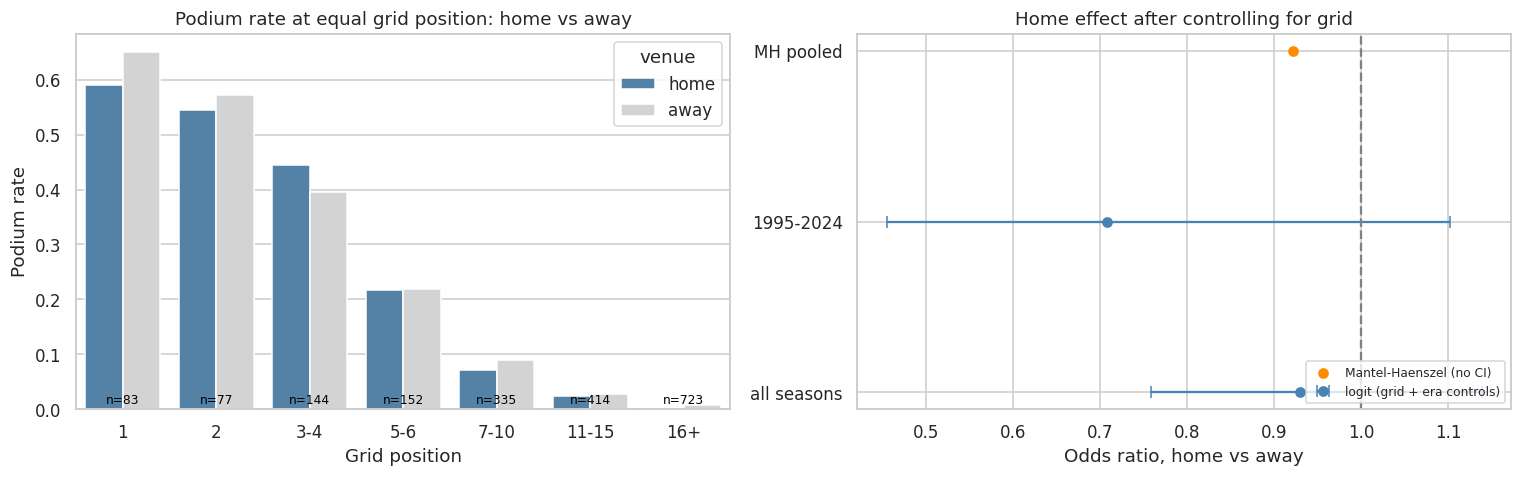

In [295]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

plot_df = st.melt(id_vars="grid_bin", value_vars=["home_rate", "away_rate"],
                  var_name="venue", value_name="rate")
plot_df["venue"] = plot_df["venue"].map({"home_rate": "home", "away_rate": "away"})
sns.barplot(data=plot_df, x="grid_bin", y="rate", hue="venue", ax=axes[0],
            palette={"home": "steelblue", "away": "lightgray"})
for i, r in st.iterrows():
    axes[0].text(i, 0.01, f"n={int(r.home_n)}", ha="center", fontsize=8, color="black")
axes[0].set_title("Podium rate at equal grid position: home vs away")
axes[0].set_xlabel("Grid position"); axes[0].set_ylabel("Podium rate")

r = res_q2
y = np.arange(len(r))
axes[1].errorbar(r.odds_ratio, y, xerr=[r.odds_ratio - r.ci_low, r.ci_high - r.odds_ratio],
                 fmt="o", color="steelblue", capsize=4, label="logit (grid + era controls)")
axes[1].scatter([or_mh], [len(r)], color="darkorange", zorder=3, label="Mantel-Haenszel (no CI)")
axes[1].axvline(1, color="gray", ls="--")
axes[1].set_yticks(list(y) + [len(r)]); axes[1].set_yticklabels(list(r.spec) + ["MH pooled"])
axes[1].set_xlabel("Odds ratio, home vs away"); axes[1].set_title("Home effect after controlling for grid")
axes[1].legend(loc="lower right", fontsize=8)
plt.tight_layout(); save_fig("q2_home_effect"); plt.show()

### Q2 answer
- **Raw:** home drivers finished on the podium in 11.6% of 1,928 starts against 13.6% of 20,239 away starts. Home drivers actually started slightly *lower* on the grid (mean 12.7 vs 11.8, median 13 vs 12), so the raw gap does not come from home drivers qualifying better.
- **Controlled:** at equal grid position the Mantel-Haenszel odds ratio is 0.92 (about -0.6 percentage points). The logistic regression with grid bins and era controls, clustered by driver, gives an odds ratio of 0.93 (95% CI 0.76 to 1.14, p = 0.48). Restricting to 1995-2024 gives 0.71 (0.46 to 1.10, p = 0.13, 556 home rows). Within grid bins the home rate is higher only at grid 3-4 (44.4% vs 39.6%) and lower or equal elsewhere.
- **Conclusion:** no home advantage is detectable after controlling for starting position; the estimates point slightly below 1 but their intervals include 1 in every specification.
- **Grain and missingness:** one driver-race row; 24,586 rows reduce to 22,167 after keeping grid >= 1 (87 pit-lane starts excluded) and nationalities with at least one host circuit (for example New Zealander, Finnish, Danish and Irish drivers never have a home race, so they are excluded); 1,928 home rows from 501 drivers. The Indy 500 was removed in Section 3. **Cutoff:** grid, nationality and circuit country are all pre-race.
- **Caveats:** (1) this is an association, not a causal effect; (2) car quality is not controlled (for example Italian drivers at Ferrari), so a constructor-strength control would be the next step; (3) home races per driver are few, so the top grid bins are small (77-83 home rows); (4) nationality is not residence; (5) circuits in Azerbaijan, Bahrain, Korea, Morocco, Qatar, Saudi Arabia, Singapore and the UAE have no matching driver nationality, so they only count as away races.

## Q3: Mechanical retirement rate by constructor, 2014-2021 vs 2022-2024

**Unit:** one car start (a driver-race row, excluding statuses that mean the car never started).
**Rate:** mechanical retirements / starts, per constructor and window, with a Wilson 95% interval.

**Status grouping (documented rule)**
- `mechanical`: failure of a car component (engine, gearbox, hydraulics, power unit, brakes, electrical, ...).
- `ambiguous` (tyre, puncture, wheel, damage, debris, wing, floor, vibrations, ...): the cause is often contact or debris, so they are **excluded** from the main rate and included in a sensitivity analysis.
- Everything else that is not "Finished" or "+N Laps" (accident, collision, spun off, disqualified, illness, out of fuel, generic "Retired", ...) is **not mechanical**.
- Statuses not listed below default to not mechanical, and the next cells print them for review.

**Teams that renamed** (for example Force India, Racing Point, Aston Martin) are merged into one lineage. This choice is flagged and documented.

**Cutoff:** status is post-race, so it is used for this analysis only and never as a feature.

In [296]:
MECH_CORE = {
    "engine", "gearbox", "transmission", "clutch", "hydraulics", "electrical", "electronics",
    "radiator", "suspension", "brakes", "brake", "differential", "overheating", "mechanical",
    "driveshaft", "fuel pressure", "fuel pump", "fuel leak", "fuel system", "water pressure",
    "water leak", "water pump", "oil leak", "oil pressure", "oil line", "throttle", "steering",
    "technical", "exhaust", "spark plugs", "engine fire", "engine misfire", "power unit", "power loss", "ers",
    "turbo", "cooling system", "battery", "ignition", "pneumatics", "drivetrain",
    "heat shield fire", "wheel rim", "track rod",
}
MECH_AMBIG = {
    "tyre", "puncture", "wheel", "wheel nut", "damage", "debris", "front wing", "rear wing",
    "broken wing", "undertray", "brake duct", "vibrations", "driver seat", "seat",
}
NOT_STARTED = {"did not qualify", "did not prequalify", "withdrew"}

def classify(s):
    k = str(s).strip().lower()
    if re.fullmatch(r"finished|\+\d+ laps?", k):
        return "finished"
    if k in MECH_CORE:
        return "mechanical"
    if k in MECH_AMBIG:
        return "ambiguous"
    if k in NOT_STARTED:
        return "not_started"
    return "other_dnf"

q3 = (base[base.year >= 2014]
      .merge(C["status"][["statusId", "status"]], on="statusId", how="left", validate="m:1")
      .merge(C["constructors"][["constructorId", "name"]].rename(columns={"name": "constructor_name"}),
             on="constructorId", how="left", validate="m:1"))
q3["status_class"] = q3.status.map(classify)

review = (q3.groupby(["status_class", "status"]).size().rename("rows").reset_index()
            .sort_values(["status_class", "rows"], ascending=[True, False]))
print("Statuses that default to NOT mechanical. Review this list; move any component failure into MECH_CORE:")
display(review[review.status_class == "other_dnf"])
print("Class totals:")
display(q3.status_class.value_counts().to_frame("rows"))

Statuses that default to NOT mechanical. Review this list; move any component failure into MECH_CORE:


,status_class,status,rows
57,other_dnf,Collision,150
56,other_dnf,Accident,85
58,other_dnf,Collision damage,59
63,other_dnf,Retired,49
59,other_dnf,Disqualified,11
64,other_dnf,Spun off,11
61,other_dnf,Illness,2
60,other_dnf,Excluded,1
62,other_dnf,Out of fuel,1


Class totals:


,rows
status_class,
finished,3825
other_dnf,369
mechanical,359
ambiguous,42
not_started,3


In [297]:
LINEAGE = {
    "Force India": "Aston Martin (ex-Force India)", "Racing Point": "Aston Martin (ex-Force India)",
    "Aston Martin": "Aston Martin (ex-Force India)",
    "Toro Rosso": "RB (ex-Toro Rosso)", "AlphaTauri": "RB (ex-Toro Rosso)",
    "RB F1 Team": "RB (ex-Toro Rosso)", "RB": "RB (ex-Toro Rosso)",
    "Sauber": "Sauber (incl. Alfa Romeo)", "Alfa Romeo": "Sauber (incl. Alfa Romeo)",
    "Lotus F1": "Alpine (ex-Lotus/Renault)", "Renault": "Alpine (ex-Lotus/Renault)",
    "Alpine F1 Team": "Alpine (ex-Lotus/Renault)",
    "Marussia": "Marussia/Manor", "Manor Marussia": "Marussia/Manor",
}
USE_LINEAGE = True
q3["team"] = q3.constructor_name.map(LINEAGE).fillna(q3.constructor_name) if USE_LINEAGE else q3.constructor_name

n0 = len(q3)
q3 = q3[(q3.status_class != "not_started") & (q3.year <= LAST_SEASON)].copy()
print(f"Rows 2014+: {n0} -> {len(q3)} after removing non-starts and seasons after {LAST_SEASON}")

q3["window"] = np.where(q3.year <= 2021, "2014-2021", "2022-2024")
q3["mech_strict"] = q3.status_class == "mechanical"
q3["mech_broad"] = q3.status_class.isin(["mechanical", "ambiguous"])

print("\nLineage mapping applied:")
display(q3[q3.constructor_name != q3.team].groupby(["constructor_name", "team"]).size().rename("starts").to_frame())

overall = q3.groupby("window").agg(starts=("podium", "size"), mech_strict=("mech_strict", "sum"),
                                   mech_broad=("mech_broad", "sum"))
overall["rate_strict"] = overall.mech_strict / overall.starts
overall["rate_broad"] = overall.mech_broad / overall.starts
display(overall)

Rows 2014+: 4598 -> 4595 after removing non-starts and seasons after 2024

Lineage mapping applied:


,,starts
constructor_name,team,
Alfa Romeo,Sauber (incl. Alfa Romeo),208
AlphaTauri,RB (ex-Toro Rosso),165
Alpine F1 Team,Alpine (ex-Lotus/Renault),179
Aston Martin,Aston Martin (ex-Force India),177
Force India,Aston Martin (ex-Force India),198
Lotus F1,Alpine (ex-Lotus/Renault),75
Manor Marussia,Marussia/Manor,77
Marussia,Marussia/Manor,31
RB F1 Team,RB (ex-Toro Rosso),48


,starts,mech_strict,mech_broad,rate_strict,rate_broad
window,,,,,
2014-2021,3244,286,321,0.0882,0.0990
2022-2024,1351,73,80,0.0540,0.0592



Top 5 mechanical-retirement rates, 2014-2021 (>= 30 starts):


,team,starts,mech,rate,lo,hi
4,Caterham,33,7,0.2121,0.1068,0.3775
14,RB (ex-Toro Rosso),319,46,0.1442,0.1099,0.1870
0,Alpine (ex-Lotus/Renault),318,42,0.1321,0.0992,0.1737
10,McLaren,315,40,0.1270,0.0947,0.1683
16,Red Bull,318,34,0.1069,0.0775,0.1457



Top 5 mechanical-retirement rates, 2022-2024 (>= 30 starts):


,team,starts,mech,rate,lo,hi
1,Alpine (ex-Lotus/Renault),135,14,0.1037,0.0628,0.1666
19,Sauber (incl. Alfa Romeo),136,12,0.0882,0.0512,0.1479
15,RB (ex-Toro Rosso),136,8,0.0588,0.0301,0.1118
21,Williams,134,7,0.0522,0.0255,0.1039
6,Ferrari,134,6,0.0448,0.0207,0.0942


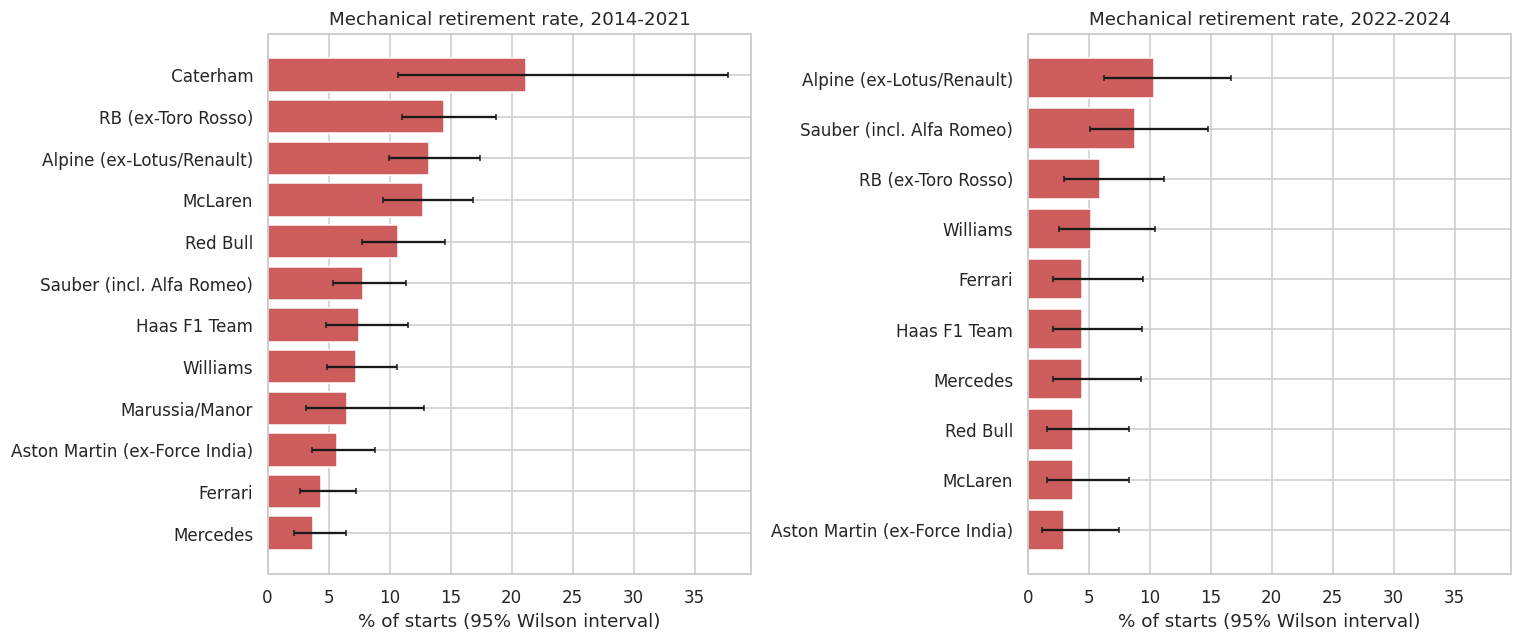

In [298]:
MIN_STARTS = 30

def constructor_rates(df, flag):
    d = df.assign(flag=df[flag].astype(int))
    g = d.groupby(["team", "window"]).agg(starts=("flag", "size"), mech=("flag", "sum")).reset_index()
    g["rate"] = g.mech / g.starts
    g["lo"], g["hi"] = wilson(g.mech.values, g.starts.values)
    return g

res_s = constructor_rates(q3, "mech_strict")
res_b = constructor_rates(q3, "mech_broad")

for wdw in ["2014-2021", "2022-2024"]:
    d = res_s[(res_s.window == wdw) & (res_s.starts >= MIN_STARTS)].sort_values("rate", ascending=False)
    print(f"\nTop 5 mechanical-retirement rates, {wdw} (>= {MIN_STARTS} starts):")
    display(d.head(5)[["team", "starts", "mech", "rate", "lo", "hi"]])

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True)
for ax, wdw in zip(axes, ["2014-2021", "2022-2024"]):
    d = res_s[(res_s.window == wdw) & (res_s.starts >= MIN_STARTS)].sort_values("rate")
    ax.barh(d.team, d.rate * 100, xerr=[(d.rate - d.lo) * 100, (d.hi - d.rate) * 100],
            color="indianred", capsize=2)
    ax.set_title(f"Mechanical retirement rate, {wdw}")
    ax.set_xlabel("% of starts (95% Wilson interval)")
plt.tight_layout(); save_fig("q3_rates_by_window"); plt.show()

,starts_pre,mech_pre,rate_pre,starts_post,mech_post,rate_post,change_pp,p_fisher
team,,,,,,,,
McLaren,315,40,0.1270,136,5,0.0368,-9.0219,0.0031
RB (ex-Toro Rosso),319,46,0.1442,136,8,0.0588,-8.5377,0.0107
Red Bull,318,34,0.1069,136,5,0.0368,-7.0154,0.0164
Haas F1 Team,240,18,0.0750,135,6,0.0444,-3.0556,0.2798
Alpine (ex-Lotus/Renault),318,42,0.1321,135,14,0.1037,-2.8372,0.4393
Aston Martin (ex-Force India),317,18,0.0568,133,4,0.0301,-2.6707,0.3377
Williams,319,23,0.0721,134,7,0.0522,-1.9862,0.5374
Ferrari,318,14,0.0440,134,6,0.0448,0.0751,1.0000
Mercedes,320,12,0.0375,136,6,0.0441,0.6618,0.7938


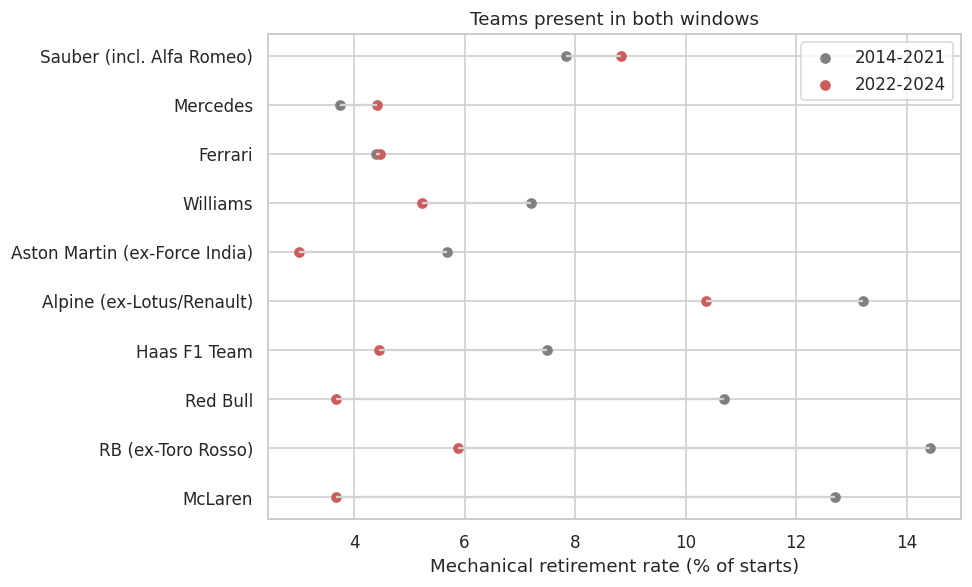

2014-2021: rank correlation strict vs broad = 0.97
2022-2024: rank correlation strict vs broad = 0.82


In [299]:
from scipy.stats import fisher_exact

pre = res_s[res_s.window == "2014-2021"].set_index("team")
post = res_s[res_s.window == "2022-2024"].set_index("team")
m = pre[["starts", "mech", "rate"]].join(post[["starts", "mech", "rate"]],
                                         lsuffix="_pre", rsuffix="_post", how="inner")
m = m[(m.starts_pre >= MIN_STARTS) & (m.starts_post >= MIN_STARTS)].copy()
m["change_pp"] = (m.rate_post - m.rate_pre) * 100
m["p_fisher"] = [fisher_exact([[r.mech_pre, r.starts_pre - r.mech_pre],
                               [r.mech_post, r.starts_post - r.mech_post]])[1] for r in m.itertuples()]
m = m.sort_values("change_pp")
display(m.round(4))

fig, ax = plt.subplots(figsize=(9, max(4, 0.4 * len(m) + 1.5)))
y = np.arange(len(m))
ax.hlines(y, m.rate_pre * 100, m.rate_post * 100, color="lightgray")
ax.scatter(m.rate_pre * 100, y, color="gray", label="2014-2021")
ax.scatter(m.rate_post * 100, y, color="indianred", label="2022-2024")
ax.set_yticks(y); ax.set_yticklabels(m.index)
ax.set_xlabel("Mechanical retirement rate (% of starts)")
ax.set_title("Teams present in both windows"); ax.legend()
plt.tight_layout(); save_fig("q3_matched_teams"); plt.show()

# Sensitivity: strict vs broad definition
for wdw in ["2014-2021", "2022-2024"]:
    s_ = res_s[(res_s.window == wdw) & (res_s.starts >= MIN_STARTS)].set_index("team").rate
    b_ = res_b[(res_b.window == wdw) & (res_b.starts >= MIN_STARTS)].set_index("team").rate
    j = pd.concat([s_, b_], axis=1, keys=["strict", "broad"]).dropna()
    print(f"{wdw}: rank correlation strict vs broad = {j.strict.rank().corr(j.broad.rank()):.2f}")

### Q3 answer
- **League-wide:** the mechanical retirement rate fell from 8.8% (286 of 3,244 starts) in 2014-2021 to 5.4% (73 of 1,351) in 2022-2024. With the broad definition (tyres, damage and similar included) it fell from 9.9% to 5.9%.
- **Highest in 2014-2021 (at least 30 starts):** Caterham 21.2% (7 of 33, wide interval 10.7-37.8%), the RB / Toro Rosso lineage 14.4% (46 of 319), Alpine / Lotus / Renault 13.2%, McLaren 12.7%, Red Bull 10.7%. **Highest in 2022-2024:** Alpine 10.4% (14 of 135), Sauber / Alfa Romeo 8.8% (12 of 136), RB 5.9%, Williams 5.2%, Ferrari 4.5%.
- **Biggest changes among teams present in both windows:** McLaren improved by 9.0 points (12.7% to 3.7%, Fisher p = 0.003), RB by 8.5 points (14.4% to 5.9%, p = 0.011) and Red Bull by 7.0 points (10.7% to 3.7%, p = 0.016). Haas (-3.1), Alpine (-2.8), Aston Martin (-2.7) and Williams (-2.0) also improved but not significantly (p 0.28-0.54); Ferrari (+0.1), Mercedes (+0.7) and Sauber (+1.0) are essentially unchanged (all p > 0.7). Alpine is among the highest in both windows.
- **Robustness:** the team ranking under the strict and the broad definition correlates 0.97 in 2014-2021 and 0.82 in 2022-2024.
- **Grain:** one car start per driver-race, 4,595 starts after removing 3 rows that never started. **Missingness:** teams with fewer than 30 starts per window are excluded. **Cutoff:** status is post-race and is used for this question only, never as a feature.
- **Caveats:** the status-to-mechanical mapping is manual; the review list of statuses treated as not mechanical was Collision (150), Accident (85), Collision damage (59), Retired (49), Disqualified (11), Spun off (11), Illness (2), Excluded (1) and Out of fuel (1); renamed teams are merged into lineages (flag `USE_LINEAGE`); 2022-2024 has only three seasons, so rates are noisy; engine-supplier failures count against the team using the engine.

In [300]:
TABLES_OUT = OUT / "answers"
TABLES_OUT.mkdir(parents=True, exist_ok=True)
w_grid.to_csv(TABLES_OUT / "q1_grid_circuit_conversion.csv", index=False)
w_q.to_csv(TABLES_OUT / "q1_quali_circuit_conversion.csv", index=False)
st.to_csv(TABLES_OUT / "q2_stratified.csv", index=False)
res_q2.to_csv(TABLES_OUT / "q2_logit.csv", index=False)
res_s.to_csv(TABLES_OUT / "q3_rates_strict.csv", index=False)
m.to_csv(TABLES_OUT / "q3_matched_teams.csv")
print("Saved tables to", TABLES_OUT, "| figures in", FIG_DIR)

Saved tables to /kaggle/working/clean/answers | figures in /kaggle/working/figures


# 5. Feature Selection and Engineering

**Rule:** a feature is allowed only if it is known after qualifying and before lights out. Anything from the current race (result, points, status, laps, pit stops, post-race standings) is forbidden.

| Group | Candidate features | Why it should matter |
|---|---|---|
| grid | grid, effective grid, pit-lane start, field size, grid vs teammate, team's best grid | start position is the strongest podium predictor |
| qualifying | quali position, gap to pole (%), grid minus quali, penalised flag | raw pace, plus penalty information the grid hides |
| driver form | podium rate and finishing percentile (last 5 races), DNF rate, career podium rate, experience | driver skill and recent momentum |
| constructor form | podium rate, finishing percentile and DNF rate (last 5 races), season-to-date podium rate | car performance dominates in most eras |
| standings | driver and constructor standing and points share **before** this race | cumulative strength |
| context | home race, circuit overtaking history, round | circuit and calendar effects |

**Evidence policy:** all selection evidence (univariate AUC, correlations, plots) uses the **training window only**, so validation and test never influence which features are kept.

**Not used, with reasons (shown below):** `year`/era (test seasons lie outside the training range), sprint results (none in the training window).

In [301]:
from sklearn.metrics import roc_auc_score, average_precision_score

def ints(df, cols):
    df = df.copy()
    for c in cols:
        df[c] = df[c].astype(int)
    return df

# Race order and "previous race of the SAME season"
ro = ints(C["races"][["raceId", "year", "round"]], ["raceId", "year", "round"])
ro = ro.sort_values(["year", "round"]).reset_index(drop=True)
ro["race_idx"] = np.arange(len(ro))
ro["prev_raceId"] = ro.groupby("year").raceId.shift(1).astype(float)   # NaN in round 1

# Status -> finished flag (reuses classify() from Section 4). Used only on PAST races.
fin_map = (C["status"].set_index("statusId")["status"].map(classify).eq("finished")).astype(float).to_dict()

KEEP = ["raceId", "driverId", "constructorId", "circuitId", "year", "round", "grid", "quali_pos",
        "positionOrder", "points", "statusId", "podium", "home"]
sk = ints(base[KEEP], ["raceId", "driverId", "constructorId", "circuitId", "year", "round", "statusId"])
for c in ["grid", "quali_pos", "positionOrder", "points"]:
    sk[c] = sk[c].astype(float)
sk["home_race"] = sk.pop("home").astype(int)
sk["finished"] = sk.statusId.map(fin_map)
sk = sk.merge(ro[["raceId", "race_idx", "prev_raceId"]], on="raceId", how="left", validate="m:1")
assert sk.finished.notna().all() and sk.race_idx.notna().all()

def prep_stand(df, idcol):
    out = df[["raceId", idcol, "points", "position"]].copy()
    out["raceId"] = out["raceId"].astype(float)
    out[idcol] = out[idcol].astype(int)
    out["points"] = out["points"].astype(float)
    out["position"] = out["position"].astype(float)
    return out

dstand = prep_stand(C["driver_standings"], "driverId")
cstand = prep_stand(C["constructor_standings"], "constructorId")

qt = C["qualifying"][["raceId", "driverId", "q1", "q2", "q3"]].copy()
qt["q_best"] = qt[["q1", "q2", "q3"]].min(axis=1)           # best lap across Q1-Q3, seconds
qt = (ints(qt.dropna(subset=["q_best"]), ["raceId", "driverId"])
        .drop_duplicates(["raceId", "driverId"])[["raceId", "driverId", "q_best"]])

print("Skeleton:", sk.shape, "| standings rows:", len(dstand), len(cstand), "| quali times:", len(qt))

Skeleton: (24586, 16) | standings rows: 34863 13391 | quali times: 10338


In [302]:
def lag_roll(s, n):
    return s.shift(1).rolling(n, min_periods=1).mean()     # shift(1): current race excluded

def lag_exp(s):
    return s.shift(1).expanding(min_periods=1).mean()

def build_features(res, dstand, cstand, qt):
    df = res.copy()
    df["dnf"] = 1.0 - df["finished"]

    # ---- grid features (fixed once the grid is set)
    g_race = df.groupby("race_idx")
    df["field_size"] = g_race["driverId"].transform("size")
    df["pos_pct"] = df["positionOrder"] / df["field_size"]          # used only after lagging
    df["pit_lane_start"] = (df["grid"] == 0).astype(int)
    max_grid = g_race["grid"].transform("max")
    df["grid_eff"] = np.where(df["grid"] > 0, df["grid"], max_grid + 1)   # pit-lane = behind the grid
    df.loc[max_grid == 0, "grid_eff"] = np.nan                            # grid not recorded that race
    gt = df.groupby(["race_idx", "constructorId"])["grid_eff"]
    n_car = gt.transform("size")
    other_mean = (gt.transform("sum") - df["grid_eff"]) / (n_car - 1).where(n_car > 1)
    df["grid_vs_teammate"] = df["grid_eff"] - other_mean
    df["team_best_grid"] = gt.transform("min")

    # ---- qualifying features
    df = df.merge(qt, on=["raceId", "driverId"], how="left", validate="m:1")
    pole = df.groupby("raceId")["q_best"].transform("min")
    df["qgap_pct"] = (df["q_best"] / pole - 1) * 100
    df["has_quali"] = df["quali_pos"].notna().astype(int)
    df["grid_minus_quali"] = df["grid_eff"] - df["quali_pos"]
    df["penalised"] = np.where(df["quali_pos"].notna(), (df["grid_minus_quali"] > 0).astype(float), np.nan)

    # ---- driver form (previous races only)
    df = df.sort_values(["driverId", "race_idx"]).reset_index(drop=True)
    gd = df.groupby("driverId", sort=False)
    df["drv_starts"] = gd.cumcount()
    df["drv_pod5"] = gd["podium"].transform(lambda s: lag_roll(s, 5))
    df["drv_pos5"] = gd["pos_pct"].transform(lambda s: lag_roll(s, 5))
    df["drv_dnf5"] = gd["dnf"].transform(lambda s: lag_roll(s, 5))
    df["drv_pod_career"] = gd["podium"].transform(lag_exp)

    # ---- constructor form: aggregate per race FIRST, then lag per constructor
    crr = (df.groupby(["race_idx", "constructorId", "year"], as_index=False)
             .agg(c_pod=("podium", "mean"), c_pos=("pos_pct", "mean"), c_dnf=("dnf", "mean")))
    crr = crr.sort_values(["constructorId", "race_idx"]).reset_index(drop=True)
    gc = crr.groupby("constructorId", sort=False)
    crr["con_pod5"] = gc["c_pod"].transform(lambda s: lag_roll(s, 5))
    crr["con_pos5"] = gc["c_pos"].transform(lambda s: lag_roll(s, 5))
    crr["con_dnf5"] = gc["c_dnf"].transform(lambda s: lag_roll(s, 5))
    crr["con_pod_season"] = crr.groupby(["constructorId", "year"], sort=False)["c_pod"].transform(lag_exp)
    df = df.merge(crr[["race_idx", "constructorId", "con_pod5", "con_pos5", "con_dnf5", "con_pod_season"]],
                  on=["race_idx", "constructorId"], how="left", validate="m:1")

    # ---- standings BEFORE this race = standings after the previous race of the same season
    ds = (dstand.rename(columns={"raceId": "prev_raceId", "points": "d_pts_bef", "position": "d_pos_bef"})
                .drop_duplicates(["prev_raceId", "driverId"]))
    lead_d = (dstand.groupby("raceId")["points"].max().rename("d_lead")
                    .rename_axis("prev_raceId").reset_index())
    df = (df.merge(ds, on=["prev_raceId", "driverId"], how="left", validate="m:1")
            .merge(lead_d, on="prev_raceId", how="left", validate="m:1"))
    df["d_pts_bef"] = df["d_pts_bef"].fillna(0.0)                    # round 1 / not yet listed = 0 points
    df["d_pts_share_bef"] = np.where(df["d_lead"] > 0, df["d_pts_bef"] / df["d_lead"], 0.0)

    cs = (cstand.rename(columns={"raceId": "prev_raceId", "points": "c_pts_bef", "position": "c_pos_bef"})
                .drop_duplicates(["prev_raceId", "constructorId"]))
    lead_c = (cstand.groupby("raceId")["points"].max().rename("c_lead")
                    .rename_axis("prev_raceId").reset_index())
    df = (df.merge(cs, on=["prev_raceId", "constructorId"], how="left", validate="m:1")
            .merge(lead_c, on="prev_raceId", how="left", validate="m:1"))
    has_cs = df["year"] >= 1958                                      # constructors' championship starts 1958
    df.loc[has_cs, "c_pts_bef"] = df.loc[has_cs, "c_pts_bef"].fillna(0.0)
    df["c_pts_share_bef"] = np.where(df["c_lead"] > 0, df["c_pts_bef"] / df["c_lead"],
                                     np.where(has_cs, 0.0, np.nan))

    # ---- circuit overtaking history: past editions only
    fin = df[df["finished"] == 1].copy()
    fin["move"] = (fin["grid_eff"] - fin["positionOrder"]).abs()
    rl = (fin.groupby(["race_idx", "circuitId"], as_index=False)["move"].mean()
             .sort_values(["circuitId", "race_idx"]).reset_index(drop=True))
    rl["circ_move_hist"] = rl.groupby("circuitId", sort=False)["move"].transform(lambda s: lag_roll(s, 5))
    df = df.merge(rl[["race_idx", "circuitId", "circ_move_hist"]],
                  on=["race_idx", "circuitId"], how="left", validate="m:1")

    return df.sort_values(["race_idx", "driverId"]).reset_index(drop=True)

In [303]:
FEATURE_GROUPS_ALL = {
    "grid": ["grid", "grid_eff", "pit_lane_start", "field_size", "grid_vs_teammate", "team_best_grid"],
    "qualifying": ["quali_pos", "qgap_pct", "grid_minus_quali", "penalised", "has_quali"],
    "driver_form": ["drv_pod5", "drv_pos5", "drv_dnf5", "drv_pod_career", "drv_starts"],
    "constructor_form": ["con_pod5", "con_pos5", "con_dnf5", "con_pod_season"],
    "standings": ["d_pos_bef", "d_pts_share_bef", "c_pos_bef", "c_pts_share_bef"],
    "context": ["home_race", "circ_move_hist", "round"],
}
CAND = [f for fs in FEATURE_GROUPS_ALL.values() for f in fs]
F2G = {f: g for g, fs in FEATURE_GROUPS_ALL.items() for f in fs}
KEYS = ["raceId", "driverId", "constructorId", "circuitId", "year", "round", "race_idx"]

mt = build_features(sk, dstand, cstand, qt)
mt["era"] = mt["year"].map(era_of)

assert len(mt) == len(sk), "row count changed"
assert not mt.duplicated(["raceId", "driverId"]).any(), "grain broken"
print("Modeling table:", mt.shape, "| candidate features:", len(CAND))

miss = mt[CAND].isna().mean().sort_values(ascending=False)
display(miss[miss > 0].to_frame("share_missing").T)

Modeling table: (24586, 47) | candidate features: 27


,qgap_pct,quali_pos,grid_minus_quali,penalised,c_pos_bef,d_pos_bef,con_pod_season,grid_vs_teammate,circ_move_hist,c_pts_share_bef,drv_pod5,drv_pod_career,drv_pos5,drv_dnf5,con_dnf5,con_pos5,con_pod5
share_missing,0.5824,0.5763,0.5763,0.5763,0.1177,0.1176,0.0761,0.0691,0.0662,0.0468,0.0278,0.0278,0.0278,0.0278,0.0106,0.0106,0.0106


,rows,races,first,last,podium_rate
split,,,,,
train,9680,454,1995,2019,0.1407
val,775,39,2020,2021,0.1510
test,1352,68,2022,2024,0.1509
unused,12779,553,1950,1994,0.1298


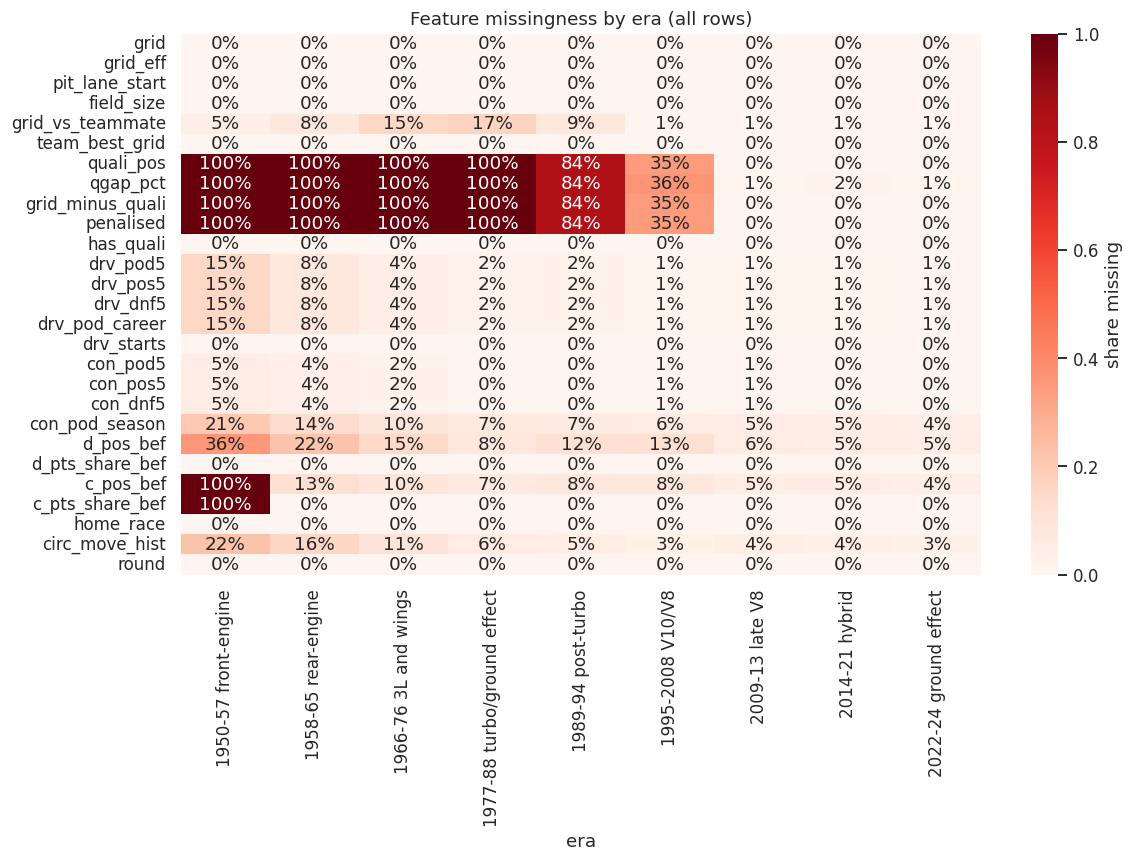

In [304]:
# Provisional training start = first season with >= 90% qualifying coverage (Section 2).
# History features still use ALL earlier seasons; this only decides which rows are modeled.
# This choice is tested as an experiment in Section 6.
MODEL_START = int(PRE_START)

mt["split"] = np.select(
    [(mt.year >= MODEL_START) & (mt.year <= TRAIN_END),
     mt.year.between(VAL_YEARS[0], VAL_YEARS[1]),
     mt.year >= TEST_START],
    ["train", "val", "test"], default="unused")

split_tbl = (mt.groupby("split").agg(rows=("podium", "size"), races=("raceId", "nunique"),
                                     first=("year", "min"), last=("year", "max"),
                                     podium_rate=("podium", "mean")).reindex(["train", "val", "test", "unused"]))
display(split_tbl)

tr = mt[mt.split == "train"].copy()          # ALL selection evidence below uses this frame only

order = [e[2] for e in ERAS]
miss_era = (mt.groupby("era")[CAND].apply(lambda d: d.isna().mean()).T.reindex(columns=order))
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(miss_era, annot=True, fmt=".0%", cmap="Reds", cbar_kws={"label": "share missing"}, ax=ax)
ax.set_title("Feature missingness by era (all rows)")
plt.tight_layout(); save_fig("s5_missing_by_era"); plt.show()

Training window 1995-2019: base podium rate = 0.141


,feature,group,coverage,auc_adj,direction,pr_auc,pr_lift
0,quali_pos,qualifying,0.8160,0.9060,lower -> podium,0.5990,4.2450
1,grid_eff,grid,1.0000,0.9060,lower -> podium,0.5940,4.2220
2,grid,grid,1.0000,0.9030,lower -> podium,0.5800,4.1190
3,team_best_grid,grid,1.0000,0.9020,lower -> podium,0.5330,3.7880
4,qgap_pct,qualifying,0.8030,0.8890,lower -> podium,0.5840,4.0980
5,d_pos_bef,standings,0.9070,0.8880,lower -> podium,0.5270,3.6570
6,con_pod_season,constructor_form,0.9440,0.8770,higher -> podium,0.5360,3.8090
7,con_pod5,constructor_form,0.9950,0.8730,higher -> podium,0.5070,3.5940
8,c_pos_bef,standings,0.9330,0.8710,lower -> podium,0.4780,3.3700
9,con_pos5,constructor_form,0.9950,0.8690,lower -> podium,0.5030,3.5610


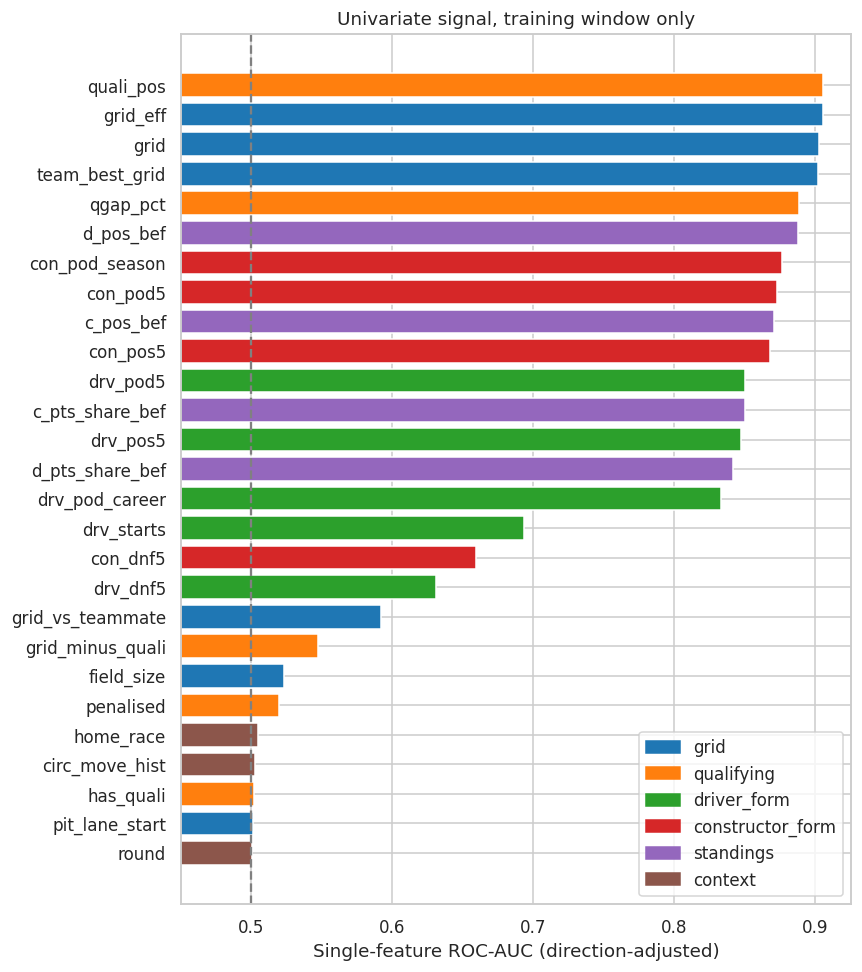

In [305]:
def uni_signal(d, feats, y="podium"):
    rows = []
    for f in feats:
        s = d[[f, y]].dropna()
        if s[f].nunique() < 2 or s[y].nunique() < 2:
            rows.append({"feature": f, "group": F2G[f], "coverage": len(s) / len(d)}); continue
        auc = roc_auc_score(s[y], s[f])
        x = s[f] if auc >= 0.5 else -s[f]
        rows.append({"feature": f, "group": F2G[f], "coverage": len(s) / len(d),
                     "auc_adj": max(auc, 1 - auc),
                     "direction": "higher -> podium" if auc >= 0.5 else "lower -> podium",
                     "pr_auc": average_precision_score(s[y], x),
                     "pr_lift": average_precision_score(s[y], x) / s[y].mean()})
    return pd.DataFrame(rows).sort_values("auc_adj", ascending=False).reset_index(drop=True)

uni = uni_signal(tr, CAND)
print(f"Training window {MODEL_START}-{TRAIN_END}: base podium rate = {tr.podium.mean():.3f}")
display(uni.round(3))

pal = dict(zip(FEATURE_GROUPS_ALL, sns.color_palette("tab10", len(FEATURE_GROUPS_ALL))))
u = uni.dropna(subset=["auc_adj"]).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(u.feature, u.auc_adj, color=[pal[g] for g in u.group])
ax.axvline(0.5, color="gray", ls="--")
ax.set_xlim(0.45, max(0.9, u.auc_adj.max() + 0.02))
ax.set_xlabel("Single-feature ROC-AUC (direction-adjusted)")
ax.set_title("Univariate signal, training window only")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in pal.values()], labels=list(pal), loc="lower right")
plt.tight_layout(); save_fig("s5_univariate_auc"); plt.show()

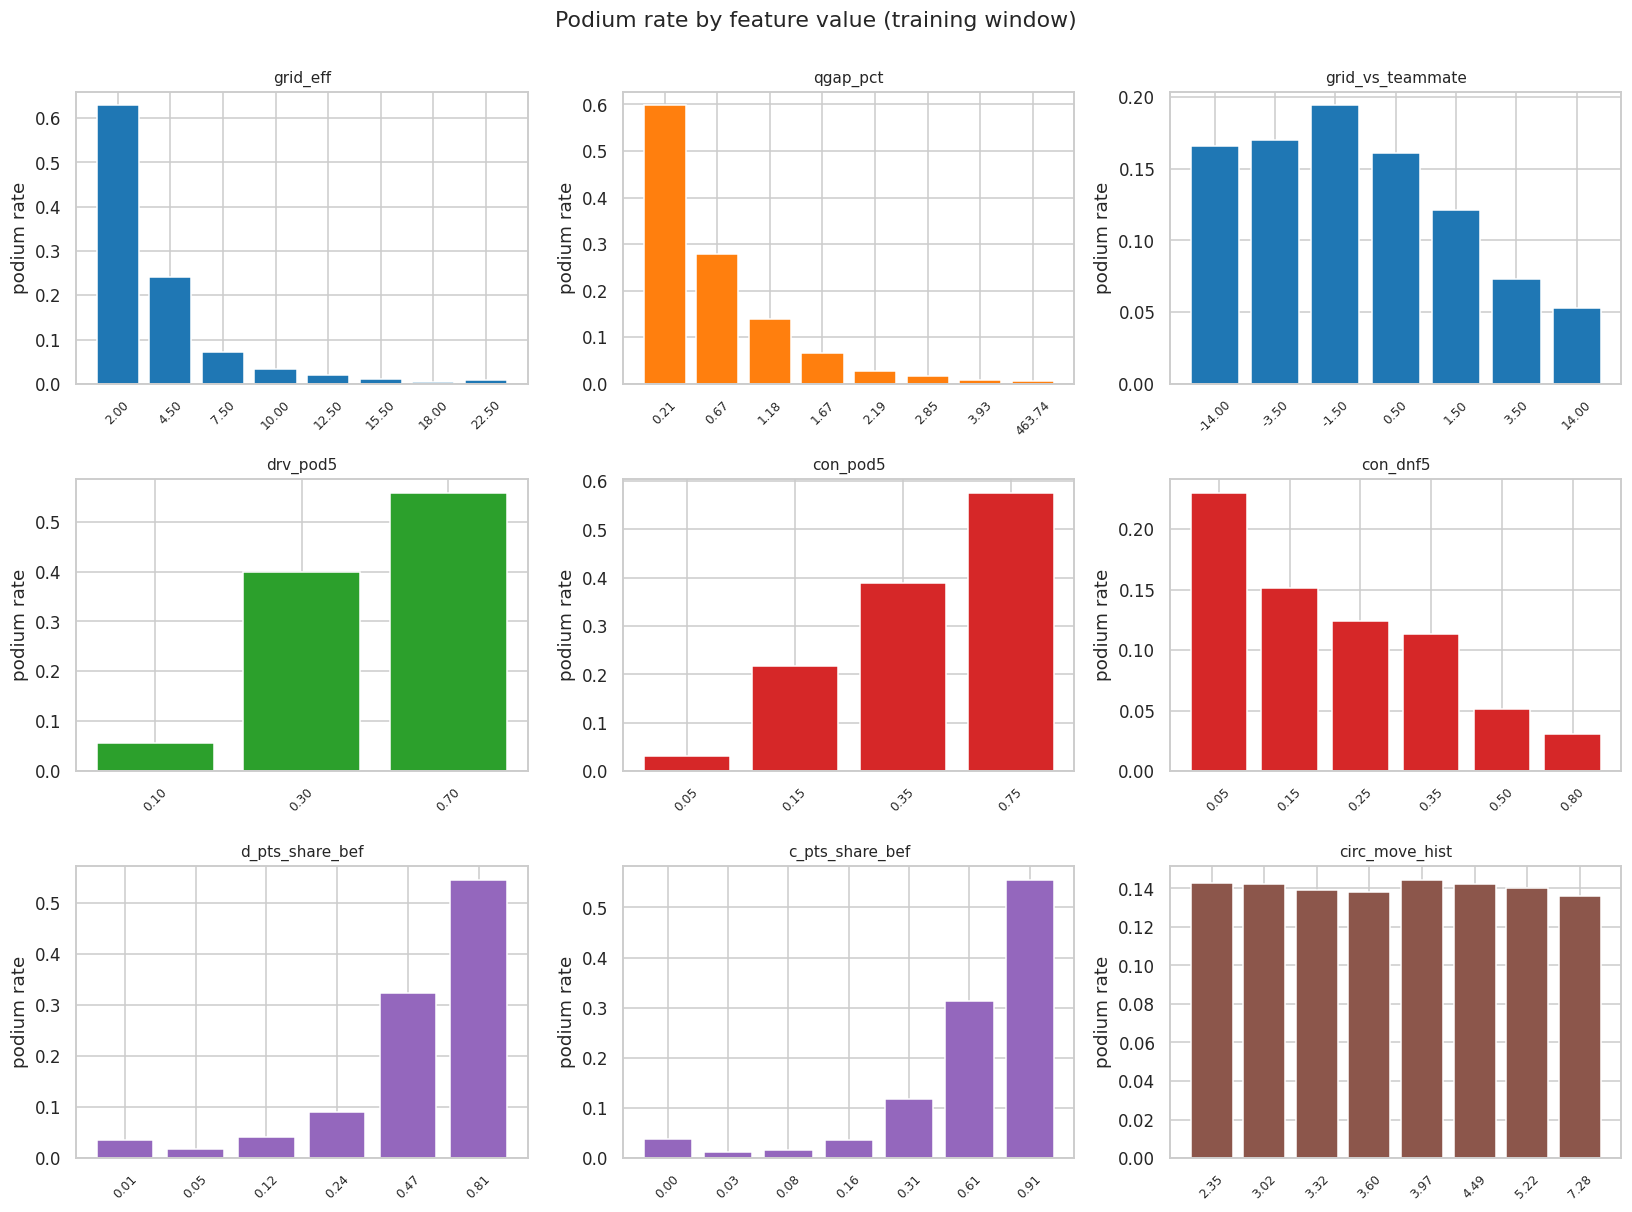

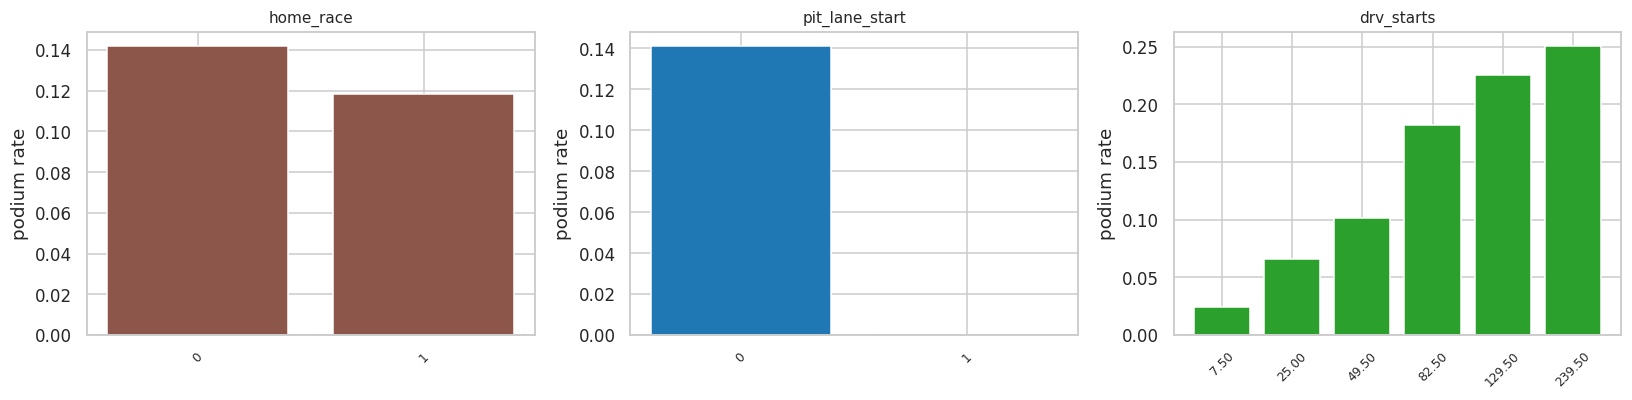

In [306]:
def rate_by_bin(ax, d, feat, q=8):
    s = d[[feat, "podium"]].dropna()
    if s[feat].nunique() <= 3:
        g = s.groupby(feat).podium.agg(["mean", "size"]); labels = [str(i) for i in g.index]
    else:
        b = pd.qcut(s[feat], q, duplicates="drop")
        g = s.groupby(b, observed=True).podium.agg(["mean", "size"])
        labels = [f"{iv.mid:.2f}" for iv in g.index]
    ax.bar(range(len(g)), g["mean"], color=pal[F2G[feat]])
    ax.set_xticks(range(len(g))); ax.set_xticklabels(labels, rotation=45, fontsize=8)
    ax.set_title(feat, fontsize=10); ax.set_ylabel("podium rate")

plot_feats = ["grid_eff", "qgap_pct", "grid_vs_teammate", "drv_pod5", "con_pod5",
              "con_dnf5", "d_pts_share_bef", "c_pts_share_bef", "circ_move_hist"]
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, f in zip(axes.ravel(), plot_feats):
    rate_by_bin(ax, tr, f)
fig.suptitle("Podium rate by feature value (training window)", y=1.0)
plt.tight_layout(); save_fig("s5_rate_by_feature"); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, f in zip(axes, ["home_race", "pit_lane_start", "drv_starts"]):
    rate_by_bin(ax, tr, f, q=6)
plt.tight_layout(); plt.show()

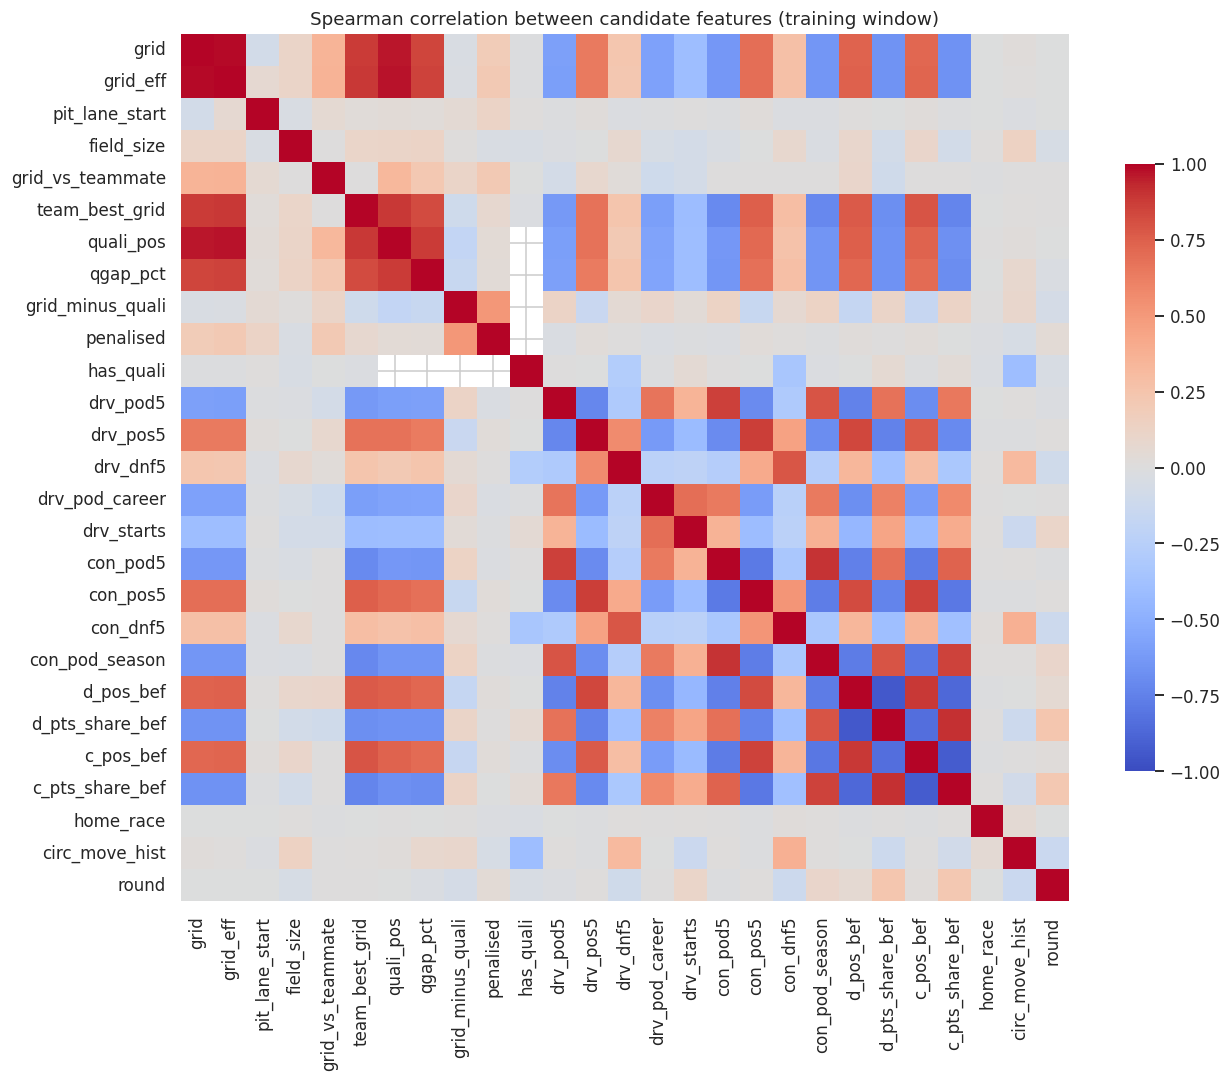

Highly correlated pairs (>= 0.98): 1


,reason
grid,|rho| = 0.99 with grid_eff (lower univariate AUC)



Selected 26 of 27 features
Weak univariate signal (kept for now, the ablation in Section 9 will judge them): ['field_size', 'penalised', 'home_race', 'circ_move_hist', 'has_quali', 'pit_lane_start', 'round']


In [308]:
CORR_THRESH = 0.98

const = [f for f in CAND if tr[f].nunique(dropna=True) <= 1]
dropped = {f: "constant in the training window" for f in const}
active = [f for f in CAND if f not in const]

corr = tr[active].corr(method="spearman")
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws={"shrink": 0.7})
ax.set_title("Spearman correlation between candidate features (training window)")
plt.tight_layout(); save_fig("s5_corr_heatmap"); plt.show()

auc_adj = uni.set_index("feature")["auc_adj"]
pairs = sorted([(a, b, abs(corr.loc[a, b]))
                for i, a in enumerate(corr.columns) for b in corr.columns[i + 1:]
                if abs(corr.loc[a, b]) >= CORR_THRESH], key=lambda t: -t[2])

kept = set(active)
for a, b, r in pairs:
    if a in kept and b in kept:
        loser, winner = (a, b) if auc_adj[a] < auc_adj[b] else (b, a)
        kept.discard(loser)
        dropped[loser] = f"|rho| = {r:.2f} with {winner} (lower univariate AUC)"

FEATURES = [f for f in CAND if f in kept]
print(f"Highly correlated pairs (>= {CORR_THRESH}): {len(pairs)}")
display(pd.Series(dropped, name="reason").to_frame() if dropped else pd.DataFrame({"result": ["nothing dropped"]}))
print(f"\nSelected {len(FEATURES)} of {len(CAND)} features")

weak = uni[(uni.feature.isin(FEATURES)) & (uni.auc_adj < 0.53)].feature.tolist()
print("Weak univariate signal (kept for now, the ablation in Section 9 will judge them):", weak)

Rows with qualifying in the training window: 7903 | share penalised (grid worse than quali): 0.051


penalised,not_penalised,penalised
quali_pos,,
1.0000,0.7730,0.0000
2.0000,0.6190,0.2140
3.0000,0.5210,0.2940
4.0000,0.3380,0.2500
5.0000,0.2480,0.0770
6.0000,0.1690,0.0710
7.0000,0.0980,0.0000
8.0000,0.0590,0.0670
9.0000,0.0450,0.0000


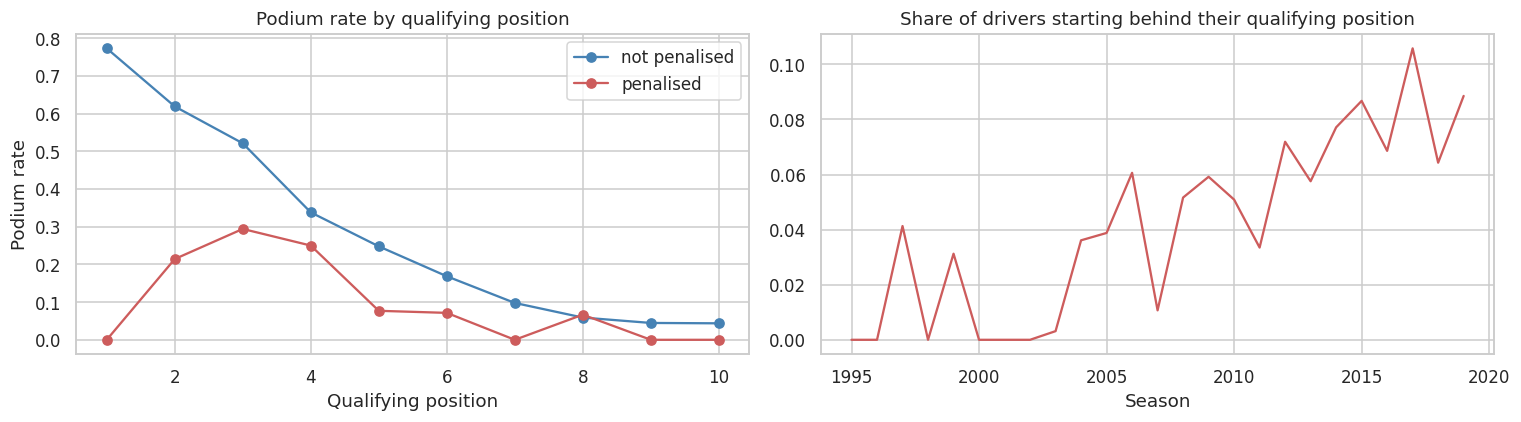

In [307]:
qq = tr[tr.penalised.notna()].copy()
print("Rows with qualifying in the training window:", len(qq),
      "| share penalised (grid worse than quali):", round(qq.penalised.mean(), 3))

top = qq[qq.quali_pos <= 10]
g = top.groupby(["quali_pos", "penalised"]).podium.agg(["mean", "size"]).reset_index()
display(g.pivot(index="quali_pos", columns="penalised", values="mean").round(3)
          .rename(columns={0.0: "not_penalised", 1.0: "penalised"}))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for pen, lab, col in [(0.0, "not penalised", "steelblue"), (1.0, "penalised", "indianred")]:
    d = g[g.penalised == pen]
    axes[0].plot(d.quali_pos, d["mean"], marker="o", label=lab, color=col)
axes[0].set_title("Podium rate by qualifying position")
axes[0].set_xlabel("Qualifying position"); axes[0].set_ylabel("Podium rate"); axes[0].legend()

pen_year = qq.groupby("year").penalised.mean()
axes[1].plot(pen_year.index, pen_year.values, color="indianred")
axes[1].set_title("Share of drivers starting behind their qualifying position")
axes[1].set_xlabel("Season")
plt.tight_layout(); save_fig("s5_penalty_evidence"); plt.show()

,feature,auc,coverage
0,points scored in THIS race (leaky),0.9590,1.0000
1,championship position AFTER this race (leaky),0.9320,0.9690
2,championship position BEFORE this race (used),0.8880,0.9070


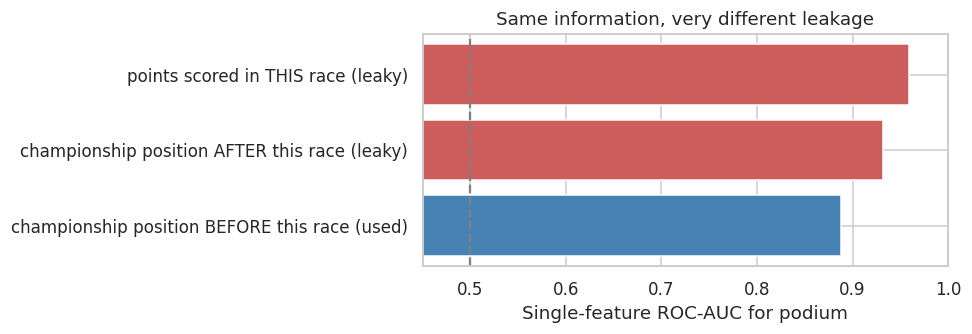

In [309]:
d_after = dstand.rename(columns={"position": "d_pos_after"})[["raceId", "driverId", "d_pos_after"]].copy()
d_after["raceId"] = d_after["raceId"].astype(int)
x = (tr[["raceId", "driverId", "podium", "points", "d_pos_bef"]]
       .merge(d_after, on=["raceId", "driverId"], how="left"))

demo = []
for label, col, sign in [("points scored in THIS race (leaky)", "points", 1),
                         ("championship position AFTER this race (leaky)", "d_pos_after", -1),
                         ("championship position BEFORE this race (used)", "d_pos_bef", -1)]:
    s = x[[col, "podium"]].dropna()
    demo.append({"feature": label, "auc": roc_auc_score(s.podium, sign * s[col]), "coverage": len(s) / len(x)})
demo = pd.DataFrame(demo)
display(demo.round(3))

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(demo.feature[::-1], demo.auc[::-1], color=["steelblue", "indianred", "indianred"])
ax.axvline(0.5, color="gray", ls="--"); ax.set_xlim(0.45, 1.0)
ax.set_xlabel("Single-feature ROC-AUC for podium"); ax.set_title("Same information, very different leakage")
plt.tight_layout(); save_fig("s5_leakage_demo"); plt.show()

In [310]:
def leakage_check(race_id, feats):
    rng = np.random.default_rng(SEED)
    r2 = sk.copy(); m = r2.raceId == race_id
    for c in ["positionOrder", "points", "finished"]:           # scramble this race's outcome
        r2.loc[m, c] = rng.permutation(r2.loc[m, c].values)
    r2.loc[m, "podium"] = (r2.loc[m, "positionOrder"] <= 3).astype(int)

    d2 = dstand.copy(); mm = d2.raceId == float(race_id)        # corrupt post-race standings of this race
    d2.loc[mm, "points"] = d2.loc[mm, "points"] * 3 + 17; d2.loc[mm, "position"] = 99
    c2 = cstand.copy(); mc = c2.raceId == float(race_id)
    c2.loc[mc, "points"] = c2.loc[mc, "points"] * 3 + 17; c2.loc[mc, "position"] = 99

    f2 = build_features(r2, d2, c2, qt)
    cols = [c for c in feats]
    a = mt[mt.raceId == race_id].set_index("driverId")[cols].sort_index().astype(float)
    b = f2[f2.raceId == race_id].set_index("driverId")[cols].sort_index().astype(float)
    same = np.allclose(a.values, b.values, equal_nan=True)

    nxt = int(mt.loc[mt.raceId == race_id, "race_idx"].iloc[0]) + 1
    a2 = mt[mt.race_idx == nxt].set_index("driverId")[cols].sort_index().astype(float)
    b2 = f2[f2.race_idx == nxt].set_index("driverId")[cols].sort_index().astype(float)
    later_changed = not np.allclose(a2.values, b2.values, equal_nan=True)
    return same, later_changed

rng = np.random.default_rng(SEED)
test_races = rng.choice(tr.raceId.unique(), size=3, replace=False)
rows = []
for rid in test_races:
    same, later = leakage_check(int(rid), CAND)
    yr = int(mt.loc[mt.raceId == rid, "year"].iloc[0])
    rows.append({"raceId": int(rid), "year": yr,
                 "features_of_perturbed_race_unchanged": same,
                 "next_race_features_changed (test is sensitive)": later})
leak_res = pd.DataFrame(rows)
display(leak_res)
assert leak_res.iloc[:, 2].all(), "LEAKAGE: a feature depends on the race it predicts"
print("Leakage test passed: no candidate feature uses current-race outcomes or standings.")

,raceId,year,features_of_perturbed_race_unchanged,next_race_features_changed (test is sensitive)
0,863,2012,True,True
1,214,1997,True,True
2,917,2014,True,True


Leakage test passed: no candidate feature uses current-race outcomes or standings.


In [311]:
sp = ints(C["sprint_results"], ["raceId"]).merge(ro[["raceId", "year"]], on="raceId", how="left")
sp_by_year = sp.groupby("year").raceId.nunique()
print("Sprint races per season:", sp_by_year.to_dict())

in_train = int(sp_by_year.reindex(range(MODEL_START, TRAIN_END + 1)).fillna(0).sum())
print("Sprint races inside the training window:", in_train)
for name, sub in mt.groupby("split"):
    n_sp = sub.raceId.isin(sp.raceId).mean()
    print(f"  {name}: {n_sp:.1%} of rows belong to a sprint weekend")
USE_SPRINT = False

Sprint races per season: {2021: 3, 2022: 3, 2023: 6, 2024: 6}
Sprint races inside the training window: 0
  test: 21.9% of rows belong to a sprint weekend
  train: 0.0% of rows belong to a sprint weekend
  unused: 0.0% of rows belong to a sprint weekend
  val: 7.6% of rows belong to a sprint weekend


In [312]:
VALID = {
 "grid": ("results.grid", "Actual start slot after penalties; fixed before lights out"),
 "grid_eff": ("results.grid", "grid, with pit-lane starts (0) placed behind the last grid slot"),
 "pit_lane_start": ("results.grid", "grid == 0 flag, known when the grid is published"),
 "field_size": ("results (rows per race)", "number of starters, known from the entry list and grid"),
 "grid_vs_teammate": ("results.grid", "own grid minus teammate's grid, both set before the race"),
 "team_best_grid": ("results.grid", "best grid slot of the team's cars"),
 "quali_pos": ("qualifying.position", "result of the qualifying session"),
 "qgap_pct": ("qualifying.q1-q3", "best qualifying lap vs pole lap, session finished before the race"),
 "grid_minus_quali": ("results.grid, qualifying", "penalty shift, both known pre-race"),
 "penalised": ("results.grid, qualifying", "grid worse than qualifying position"),
 "has_quali": ("qualifying", "qualifying record present (coverage drift indicator)"),
 "drv_pod5": ("results, PAST races", "podium rate over previous 5 races (shift(1))"),
 "drv_pos5": ("results, PAST races", "mean finishing percentile over previous 5 races"),
 "drv_dnf5": ("results+status, PAST races", "retirement rate over previous 5 races"),
 "drv_pod_career": ("results, PAST races", "expanding podium rate before this race"),
 "drv_starts": ("results, PAST races", "number of earlier starts"),
 "con_pod5": ("results, PAST races", "constructor podium share, race-level then lagged"),
 "con_pos5": ("results, PAST races", "constructor mean finishing percentile, lagged"),
 "con_dnf5": ("results+status, PAST races", "constructor retirement rate, lagged"),
 "con_pod_season": ("results, PAST races", "season-to-date constructor podium share, lagged"),
 "d_pos_bef": ("driver_standings, PREVIOUS race", "driver championship position after the previous round"),
 "d_pts_share_bef": ("driver_standings, PREVIOUS race", "points / leader's points after previous round"),
 "c_pos_bef": ("constructor_standings, PREVIOUS race", "constructor position after previous round (1958+)"),
 "c_pts_share_bef": ("constructor_standings, PREVIOUS race", "points / leader's points after previous round (1958+)"),
 "home_race": ("drivers.nationality, circuits.country", "static facts known before the weekend"),
 "circ_move_hist": ("results, PAST editions", "mean |grid - finish| at the circuit over previous 5 editions"),
 "round": ("races.round", "calendar position, published in advance"),
}
validity = (pd.DataFrame([{"feature": f, "group": F2G[f], "source": VALID[f][0], "why_valid_pre_race": VALID[f][1],
                           "selected": f in FEATURES, "dropped_reason": dropped.get(f, "")} for f in CAND]))
display(validity)

FEATURE_GROUPS = {g: [f for f in fs if f in FEATURES] for g, fs in FEATURE_GROUPS_ALL.items()}
LEAKY = {"position", "positionText", "positionOrder", "points", "laps", "milliseconds", "fastestLap",
         "fastestLapTime", "fastestLapSpeed", "rank", "statusId", "finished", "dnf", "time", "podium", "pos_pct"}
assert not (set(FEATURES) & LEAKY), "a leaky column slipped into FEATURES"

# dict.fromkeys removes duplicates (for example "round" is both a key column and a feature)
OUT_COLS = list(dict.fromkeys(KEYS + ["split"] + FEATURES + [TARGET]))
mt_final = mt[OUT_COLS].copy()
assert not mt_final.columns.duplicated().any(), "duplicate column names in the modeling table"
print({g: len(fs) for g, fs in FEATURE_GROUPS.items()}, "| rows:", len(mt_final))

mt_final.to_csv(OUT / "modeling_table.csv", index=False)
validity.to_csv(OUT / "feature_validity.csv", index=False)
uni.to_csv(OUT / "univariate_signal.csv", index=False)

,feature,group,source,why_valid_pre_race,selected,dropped_reason
0,grid,grid,results.grid,Actual start slot after penalties; fixed befor...,False,|rho| = 0.99 with grid_eff (lower univariate AUC)
1,grid_eff,grid,results.grid,"grid, with pit-lane starts (0) placed behind t...",True,
2,pit_lane_start,grid,results.grid,"grid == 0 flag, known when the grid is published",True,
3,field_size,grid,results (rows per race),"number of starters, known from the entry list ...",True,
4,grid_vs_teammate,grid,results.grid,"own grid minus teammate's grid, both set befor...",True,
5,team_best_grid,grid,results.grid,best grid slot of the team's cars,True,
6,quali_pos,qualifying,qualifying.position,result of the qualifying session,True,
7,qgap_pct,qualifying,qualifying.q1-q3,"best qualifying lap vs pole lap, session finis...",True,
8,grid_minus_quali,qualifying,"results.grid, qualifying","penalty shift, both known pre-race",True,
9,penalised,qualifying,"results.grid, qualifying",grid worse than qualifying position,True,


{'grid': 5, 'qualifying': 5, 'driver_form': 5, 'constructor_form': 4, 'standings': 4, 'context': 3} | rows: 24586


## Feature selection findings
- **Strongest signals (training window 1995-2019, base rate 14.1%):** `quali_pos` (single-feature AUC 0.906, PR-AUC lift 4.2x), `grid_eff` (0.906), `grid` (0.903), `team_best_grid` (0.902), `qgap_pct` (0.889), `d_pos_bef` (0.888), then constructor form (`con_pod_season` 0.877, `con_pod5` 0.873, `con_pos5` 0.869) and `c_pos_bef` (0.871). Driver form is a little weaker (0.83-0.85). The weakest are `field_size` (0.523), `penalised` (0.520), `home_race` (0.505), `circ_move_hist`, `has_quali`, `pit_lane_start` and `round` (about 0.50).
- **Grid vs qualifying:** only 5.1% of drivers with a qualifying record start behind their qualifying position, but those who do podium much less often from the same slot: from P2 21.4% vs 61.9%, from P3 29.4% vs 52.1%, from P4 25.0% vs 33.8%. So `grid_minus_quali` and `penalised` add information about penalties that the qualifying position alone does not have.
- **Form features:** constructor form carries more signal than driver form (AUC 0.87-0.88 vs 0.83-0.85), consistent with car performance dominating. The retirement-rate features are weak (0.63-0.66). Podium rate rises monotonically with `con_pod5` and `drv_pod5` (rate-by-value plots).
- **Standings:** shifted to "before this race". As single features, points scored in the race give AUC 0.959 and championship position after the race 0.932 (both leaky), against 0.888 for the position before the race that we use.
- **Redundancy pruning:** with |rho| >= 0.98 only one pair is pruned: `grid` (0.99 with `grid_eff`, which has the higher AUC). 26 of 27 candidates are selected and none was constant. A trial at 0.90 is documented in the next cell.
- **Excluded by design:** `year` / era (the test seasons lie outside the training range, so the model would extrapolate) and sprint results (sprint races exist only from 2021: 3, 3, 6 and 6 in 2021-2024; none in the training window, 7.6% of validation rows and 21.9% of test rows belong to sprint weekends, so there is nothing to learn from). `circuitId` and `constructorId` are not used because unseen teams and circuits appear in later seasons.
- **Leakage test:** scrambling the outcome and corrupting the post-race standings of three random races (1997, 2012, 2014) left every candidate feature of those races unchanged, while the next race's features did change, so the test is sensitive.
- **Limitations:** constructor renames reset team history; qualifying features are missing for 58% of all rows (97% before 1995 and 18% inside the 1995-2019 window); `circ_move_hist` is approximate because circuit layouts change; `grid_eff` and `quali_pos` correlate 0.97, which makes their individual effects hard to separate in the linear model (see Sections 9-11).

# 6. Preprocessing and Experiments

**Goal:** turn the feature table into model-ready matrices, justify each step, and show how the order of steps changes results.

**Model used for all experiments:** logistic regression (the baseline). It is sensitive to scale and missing values, so preprocessing differences show up clearly. Trees are checked in experiment G.

**Metric:** validation PR-AUC (podiums are rare, so it is more informative than ROC-AUC). ROC-AUC is reported alongside. Differences are given with a 95% **race-level paired bootstrap** interval, so noise is not mistaken for improvement.

**Rules:** statistics (medians, quantiles, means, stds) are learned on the training window only; validation and test are transformed with those stored statistics.

**Encoding:** all selected features are numeric or binary, so no one-hot encoding is needed. `circuitId` and `constructorId` are deliberately not encoded: they are high-cardinality IDs, and teams or circuits that appear in the test seasons may be unseen in training. Their information enters through form features instead.

| Exp | Question |
|---|---|
| A | impute then scale, or scale then impute? |
| B | missing-value indicators before or after imputation? |
| C | winsorise before or after scaling? |
| D | fit preprocessing on train only, or on train + validation (leakage)? |
| E | which scaler? |
| F | which imputation value? |
| G | do trees need imputation at all? |
| H | which training start year? |

Train: 9680 rows (1995-2019) | Validation: 775 rows (2020-2021)
Podium rate: train 0.141 | validation 0.151 (a random ranker scores PR-AUC = 0.151)


,before_training_window,train,val
% missing,,,
grid_vs_teammate,12.7000,0.7000,0.6000
quali_pos,97.0000,18.4000,0.1000
qgap_pct,97.0000,19.7000,1.2000
grid_minus_quali,97.0000,18.4000,0.1000
penalised,97.0000,18.4000,0.1000
drv_pod5,4.4000,1.1000,0.8000
drv_pos5,4.4000,1.1000,0.8000
drv_dnf5,4.4000,1.1000,0.8000
drv_pod_career,4.4000,1.1000,0.8000


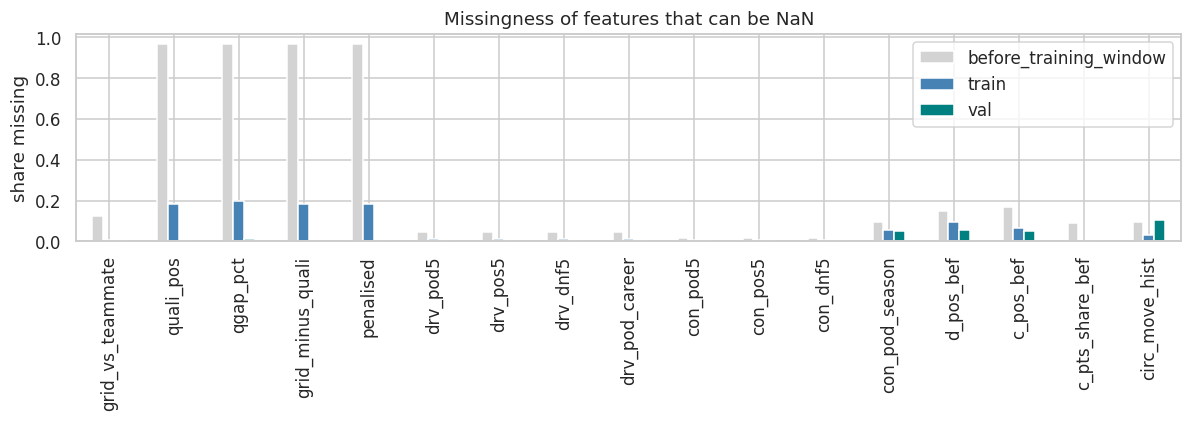

In [313]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
import copy
import joblib

D = mt_final.copy()
D["year"] = D["year"].astype(int)
TRAIN_DF = D[D.split == "train"].copy()
VAL_DF = D[D.split == "val"].copy()
VAL_Y = VAL_DF[TARGET].values

print(f"Train: {len(TRAIN_DF)} rows ({TRAIN_DF.year.min()}-{TRAIN_DF.year.max()}) | "
      f"Validation: {len(VAL_DF)} rows ({VAL_DF.year.min()}-{VAL_DF.year.max()})")
print(f"Podium rate: train {TRAIN_DF[TARGET].mean():.3f} | validation {VAL_Y.mean():.3f} "
      f"(a random ranker scores PR-AUC = {VAL_Y.mean():.3f})")

# Features that can be missing in any row up to the end of validation (no test rows consulted)
pool = D[D.year <= VAL_DF.year.max()]
MISS_COLS = [f for f in FEATURES if pool[f].isna().any()]
BIN_COLS = [f for f in FEATURES if TRAIN_DF[f].nunique(dropna=True) <= 2]

prof = pd.DataFrame({
    "before_training_window": D[D.split == "unused"][FEATURES].isna().mean(),
    "train": TRAIN_DF[FEATURES].isna().mean(),
    "val": VAL_DF[FEATURES].isna().mean(),
}).loc[MISS_COLS]
display((prof * 100).round(1).rename_axis("% missing"))

prof.plot(kind="bar", figsize=(11, 4), color=["lightgray", "steelblue", "teal"])
plt.ylabel("share missing"); plt.title("Missingness of features that can be NaN")
plt.tight_layout(); save_fig("s6_missing_profile"); plt.show()

,count,mean,std,min,50%,max,skew,binary
grid_eff,"9,680.0000",11.2680,6.2790,1.0000,11.0000,26.0000,0.0570,False
pit_lane_start,"9,680.0000",0.0020,0.0470,0.0000,0.0000,1.0000,21.4030,True
field_size,"9,680.0000",21.4580,1.6020,6.0000,22.0000,26.0000,-0.3050,False
grid_vs_teammate,"9,614.0000",0.0000,4.9100,-23.0000,0.0000,23.0000,0.0000,False
team_best_grid,"9,680.0000",9.4590,5.9940,1.0000,9.0000,25.0000,0.3120,False
quali_pos,"7,903.0000",11.2400,6.2790,1.0000,11.0000,26.0000,0.0660,False
qgap_pct,"7,773.0000",2.5960,10.7580,0.0000,1.9130,922.8620,80.6190,False
grid_minus_quali,"7,903.0000",-0.0010,1.4480,-9.0000,0.0000,23.0000,5.1390,False
penalised,"7,903.0000",0.0510,0.2200,0.0000,0.0000,1.0000,4.0890,True
has_quali,"9,680.0000",0.8160,0.3870,0.0000,1.0000,1.0000,-1.6350,True


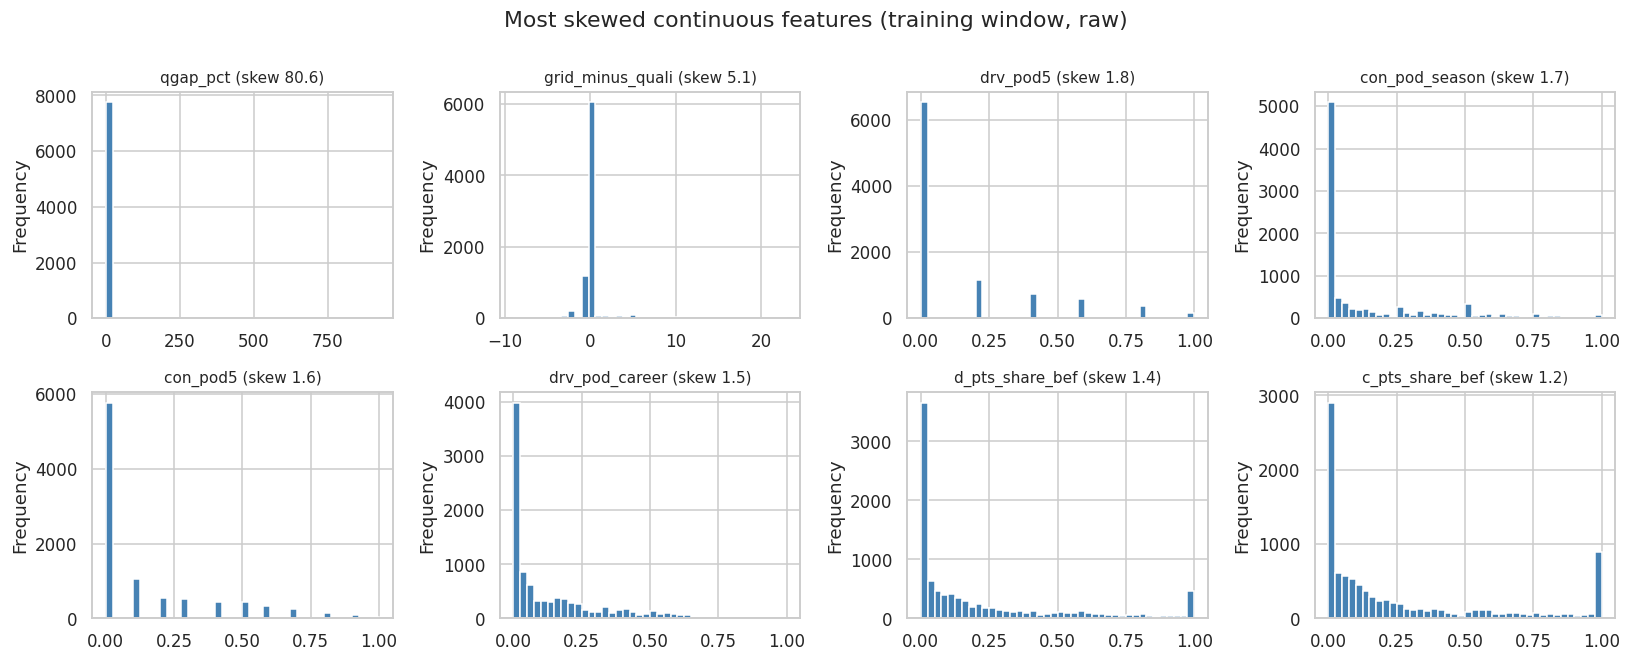

In [314]:
desc = TRAIN_DF[FEATURES].describe().T[["count", "mean", "std", "min", "50%", "max"]]
desc["skew"] = TRAIN_DF[FEATURES].skew()
desc["binary"] = desc.index.isin(BIN_COLS)
display(desc.round(3))

skewed = desc.loc[~desc["binary"], "skew"].abs().sort_values(ascending=False).head(8).index.tolist()
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, f in zip(axes.ravel(), skewed):
    TRAIN_DF[f].dropna().plot(kind="hist", bins=40, ax=ax, color="steelblue")
    ax.set_title(f"{f} (skew {desc.loc[f, 'skew']:.1f})", fontsize=10)
plt.suptitle("Most skewed continuous features (training window, raw)", y=1.0)
plt.tight_layout(); save_fig("s6_raw_skew"); plt.show()

In [315]:
class PodiumPrep:
    """Order-configurable preprocessing. Statistics are learned in fit() only."""

    def __init__(self, features, miss_cols, order=("indicator", "impute", "winsor", "scale"),
                 impute="median", scaler="standard", clip=(0.01, 0.99), allow_nan=False):
        self.features, self.miss_cols = list(features), list(miss_cols)
        self.order, self.impute, self.scaler = tuple(order), impute, scaler
        self.clip, self.allow_nan = clip, allow_nan

    def _run(self, X, fit):
        X = X[self.features].astype(float).copy()
        if fit:
            self.cont_ = [c for c in self.features if X[c].nunique(dropna=True) > 2]   # binary flags untouched
            self.state_, self.ind_keep_ = {}, []
        for step in self.order:
            if step == "indicator":
                for c in self.miss_cols:
                    X[c + "__na"] = X[c].isna().astype(float)
                if fit:      # drop indicators that are constant in the fitting data
                    self.ind_keep_ = [c + "__na" for c in self.miss_cols if X[c + "__na"].std() > 0]
            elif step == "impute":
                if fit:
                    s = X[self.features]
                    self.state_["fill"] = (s.median() if self.impute == "median" else
                                           s.mean() if self.impute == "mean" else
                                           pd.Series(0.0, index=self.features))
                X[self.features] = X[self.features].fillna(self.state_["fill"])
            elif step == "winsor":
                if fit:
                    self.state_["clip"] = (X[self.cont_].quantile(self.clip[0]),
                                           X[self.cont_].quantile(self.clip[1]))
                lo, hi = self.state_["clip"]
                X[self.cont_] = X[self.cont_].clip(lower=lo, upper=hi, axis=1)
            elif step == "scale" and self.scaler != "none":
                if fit:
                    s = X[self.cont_]
                    if self.scaler == "standard":
                        c, k = s.mean(), s.std(ddof=0)
                    else:   # robust: median and inter-quartile range
                        c, k = s.median(), s.quantile(0.75) - s.quantile(0.25)
                    self.state_["scale"] = (c, k.replace(0, 1.0).fillna(1.0))
                c, k = self.state_["scale"]
                X[self.cont_] = (X[self.cont_] - c) / k
        out = X[self.features + self.ind_keep_]
        if not self.allow_nan and out.isna().any().any():
            raise ValueError("NaN left after preprocessing: the order must include 'impute'")
        return out

    def fit(self, X):
        self._run(X, fit=True)
        return self

    def transform(self, X):
        return self._run(X, fit=False)

In [316]:
p = PodiumPrep(FEATURES, MISS_COLS).fit(TRAIN_DF[FEATURES])
Xt, Xv = p.transform(TRAIN_DF[FEATURES]), p.transform(VAL_DF[FEATURES])

assert list(Xt.columns) == list(Xv.columns), "train and validation columns differ"
assert not Xt.isna().any().any() and not Xv.isna().any().any(), "NaN left"

snap = copy.deepcopy(p.state_)
_ = p.transform(VAL_DF[FEATURES])
flat = lambda s: np.concatenate([np.asarray(x, float).ravel() for v in s.values()
                                 for x in (v if isinstance(v, tuple) else (v,))])
assert np.allclose(flat(snap), flat(p.state_)), "transform() changed the fitted statistics"

# Partially-missing and fully-missing single records must work (needed by the inference function)
row = VAL_DF[FEATURES].iloc[[0]].copy()
drop = [c for c in ["qgap_pct", "quali_pos", "grid_minus_quali", "drv_pod5"] if c in FEATURES]
row[drop] = np.nan
out_row = p.transform(row)
empty_row = p.transform(pd.DataFrame([{}], columns=FEATURES))
assert not out_row.isna().any().any() and not empty_row.isna().any().any()

print("Output columns:", Xt.shape[1], "| indicators kept:", p.ind_keep_)
print("Indicator flags for the partially-missing record:",
      out_row[[c for c in p.ind_keep_]].iloc[0].to_dict())
print("All tests passed.")

Output columns: 42 | indicators kept: ['grid_vs_teammate__na', 'quali_pos__na', 'qgap_pct__na', 'grid_minus_quali__na', 'penalised__na', 'drv_pod5__na', 'drv_pos5__na', 'drv_dnf5__na', 'drv_pod_career__na', 'con_pod5__na', 'con_pos5__na', 'con_dnf5__na', 'con_pod_season__na', 'd_pos_bef__na', 'c_pos_bef__na', 'circ_move_hist__na']
Indicator flags for the partially-missing record: {'grid_vs_teammate__na': 0.0, 'quali_pos__na': 1.0, 'qgap_pct__na': 1.0, 'grid_minus_quali__na': 1.0, 'penalised__na': 0.0, 'drv_pod5__na': 1.0, 'drv_pos5__na': 0.0, 'drv_dnf5__na': 0.0, 'drv_pod_career__na': 0.0, 'con_pod5__na': 0.0, 'con_pos5__na': 0.0, 'con_dnf5__na': 0.0, 'con_pod_season__na': 1.0, 'd_pos_bef__na': 1.0, 'c_pos_bef__na': 1.0, 'circ_move_hist__na': 0.0}
All tests passed.


In [317]:
RESULTS, PRED, SUM = {}, {}, {}

# Race-level bootstrap indices, fixed once so every comparison is paired
_rng = np.random.default_rng(SEED)
_by_race = [np.where(VAL_DF.raceId.values == r)[0] for r in VAL_DF.raceId.unique()]
BOOT = [np.concatenate([_by_race[i] for i in _rng.integers(0, len(_by_race), len(_by_race))])
        for _ in range(400)]

def pr_boot_val(p):
    return np.array([average_precision_score(VAL_Y[ix], p[ix]) for ix in BOOT])

def run(exp, name, order=("indicator", "impute", "winsor", "scale"), impute="median", scaler="standard",
        clip=(0.01, 0.99), fit_on="train", tr=None, model="lr", raw=False):
    tr = TRAIN_DF if tr is None else tr
    if raw:
        Xtr, Xva = tr[FEATURES], VAL_DF[FEATURES]
    else:
        prep = PodiumPrep(FEATURES, MISS_COLS, order, impute, scaler, clip)
        prep.fit(tr[FEATURES] if fit_on == "train" else pd.concat([tr[FEATURES], VAL_DF[FEATURES]]))
        Xtr, Xva = prep.transform(tr[FEATURES]), prep.transform(VAL_DF[FEATURES])
    m = (LogisticRegression(max_iter=3000) if model == "lr" else
         HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=300, random_state=SEED))
    m.fit(Xtr, tr[TARGET])
    p_val = m.predict_proba(Xva)[:, 1]
    RESULTS[(exp, name)] = {"exp": exp, "variant": name, "train_rows": len(tr), "n_inputs": Xtr.shape[1],
                            "val_roc_auc": roc_auc_score(VAL_Y, p_val),
                            "val_pr_auc": average_precision_score(VAL_Y, p_val)}
    PRED[(exp, name)] = p_val

def summarise(exp, ref):
    ref_b = pr_boot_val(PRED[(exp, ref)])
    rows = []
    for k in [k for k in RESULTS if k[0] == exp]:
        r, d = RESULTS[k], pr_boot_val(PRED[k]) - ref_b
        rows.append({**r, "d_pr_auc": r["val_pr_auc"] - RESULTS[(exp, ref)]["val_pr_auc"],
                     "ci_low": np.percentile(d, 2.5), "ci_high": np.percentile(d, 97.5)})
    out = pd.DataFrame(rows).drop(columns="exp")
    out["reference"] = out.variant == ref
    out["verdict"] = np.where(out.reference, "reference",
                              np.where((out.ci_low <= 0) & (out.ci_high >= 0), "within noise",
                                       np.where(out.d_pr_auc > 0, "better", "worse")))
    SUM[exp] = out
    return out.round(4)

## Experiment A: impute then scale, or scale then impute?
Both pipelines use median imputation and standardisation. Scaling after imputation includes the filled values in the mean and standard deviation, which shrinks the variance of features with many gaps. Scaling before imputation ignores the gaps.

In [318]:
run("A", "impute → scale", order=("indicator", "impute", "scale"))
run("A", "scale → impute", order=("indicator", "scale", "impute"))
summarise("A", "impute → scale")

,variant,train_rows,n_inputs,val_roc_auc,val_pr_auc,d_pr_auc,ci_low,ci_high,reference,verdict
0,impute → scale,9680,42,0.9315,0.7285,0.0000,0.0000,0.0000,True,reference
1,scale → impute,9680,42,0.9315,0.7299,0.0014,-0.0010,0.0049,False,within noise


## Experiment B: missing-value indicators before or after imputation?
An indicator must be created **before** imputation, otherwise it is all zeros and the information that qualifying data was missing is lost. This is a true ordering effect, not a matter of taste.

In [319]:
run("B", "indicator → impute → scale", order=("indicator", "impute", "scale"))
run("B", "impute → indicator → scale", order=("impute", "indicator", "scale"))
run("B", "no indicators", order=("impute", "scale"))
res = summarise("B", "indicator → impute → scale")
display(res)
for name in ["indicator → impute → scale", "impute → indicator → scale"]:
    kept_ind = PodiumPrep(FEATURES, MISS_COLS, order=tuple(name.split(" → "))).fit(TRAIN_DF[FEATURES]).ind_keep_
    print(f"{name}: {len(kept_ind)} indicator columns survive")

,variant,train_rows,n_inputs,val_roc_auc,val_pr_auc,d_pr_auc,ci_low,ci_high,reference,verdict
0,indicator → impute → scale,9680,42,0.9315,0.7285,0.0000,0.0000,0.0000,True,reference
1,impute → indicator → scale,9680,26,0.9296,0.7262,-0.0023,-0.0101,0.0056,False,within noise
2,no indicators,9680,26,0.9296,0.7262,-0.0023,-0.0101,0.0056,False,within noise


indicator → impute → scale: 16 indicator columns survive
impute → indicator → scale: 0 indicator columns survive


## Experiment C: winsorise before or after scaling?
Winsorising clips extreme values at the 1st and 99th training percentiles (for example the large `qgap_pct` of slow cars). Done before scaling, the clipped values also change the mean and standard deviation. Done after scaling, the clip happens on the scaled axis.

In [320]:
run("C", "winsor → scale", order=("indicator", "impute", "winsor", "scale"))
run("C", "scale → winsor", order=("indicator", "impute", "scale", "winsor"))
run("C", "no winsorising", order=("indicator", "impute", "scale"))
summarise("C", "winsor → scale")

,variant,train_rows,n_inputs,val_roc_auc,val_pr_auc,d_pr_auc,ci_low,ci_high,reference,verdict
0,winsor → scale,9680,42,0.9304,0.7237,0.0000,0.0000,0.0000,True,reference
1,scale → winsor,9680,42,0.9304,0.7247,0.0010,-0.0011,0.0033,False,within noise
2,no winsorising,9680,42,0.9315,0.7285,0.0048,-0.0030,0.0118,False,within noise


## Experiment D: fit preprocessing on train only, or on train + validation?
Fitting medians and scalers on data that includes the evaluation rows leaks information from the evaluation set into the pipeline. The effect is usually small, but it is a methodological error, so it is measured here (on validation, to keep the test set untouched).

In [321]:
run("D", "fit on train only", fit_on="train")
run("D", "fit on train + validation (leaky)", fit_on="train+val")
summarise("D", "fit on train only")

,variant,train_rows,n_inputs,val_roc_auc,val_pr_auc,d_pr_auc,ci_low,ci_high,reference,verdict
0,fit on train only,9680,42,0.9304,0.7237,0.0000,0.0000,0.0000,True,reference
1,fit on train + validation (leaky),9680,42,0.9305,0.7233,-0.0004,-0.0017,0.0008,False,within noise


In [322]:
run("E", "standard scaler", scaler="standard")
run("E", "robust scaler", scaler="robust")
run("E", "no scaling", scaler="none")
summarise("E", "standard scaler")

,variant,train_rows,n_inputs,val_roc_auc,val_pr_auc,d_pr_auc,ci_low,ci_high,reference,verdict
0,standard scaler,9680,42,0.9304,0.7237,0.0000,0.0000,0.0000,True,reference
1,robust scaler,9680,42,0.9305,0.7232,-0.0005,-0.0020,0.0007,False,within noise
2,no scaling,9680,42,0.9305,0.7238,0.0001,-0.0032,0.0035,False,within noise


In [323]:
run("F", "median", impute="median")
run("F", "mean", impute="mean")
run("F", "constant 0", impute="zero")
summarise("F", "median")

,variant,train_rows,n_inputs,val_roc_auc,val_pr_auc,d_pr_auc,ci_low,ci_high,reference,verdict
0,median,9680,42,0.9304,0.7237,0.0000,0.0000,0.0000,True,reference
1,mean,9680,42,0.9299,0.7216,-0.0021,-0.0051,-0.0001,False,worse
2,constant 0,9680,42,0.9308,0.7238,0.0001,-0.0020,0.0021,False,within noise


In [324]:
run("G", "HGB, raw (native NaN)", model="hgb", raw=True)
run("G", "HGB, preprocessed", model="hgb")
run("G", "LR, preprocessed", model="lr")
summarise("G", "HGB, raw (native NaN)")

,variant,train_rows,n_inputs,val_roc_auc,val_pr_auc,d_pr_auc,ci_low,ci_high,reference,verdict
0,"HGB, raw (native NaN)",9680,26,0.9314,0.6994,0.0000,0.0000,0.0000,True,reference
1,"HGB, preprocessed",9680,42,0.9300,0.6928,-0.0066,-0.0174,0.0083,False,within noise
2,"LR, preprocessed",9680,42,0.9304,0.7237,0.0243,-0.0310,0.0656,False,within noise


Trees are invariant to scaling and handle `NaN` natively, so experiment G shows which preprocessing steps matter only for the linear model and the neural network.

## Experiment H: training start year
The training window must be chosen. Early seasons add rows but have no qualifying features (see the coverage plot in Section 2) and a very different reliability and field structure. All windows end at 2019; the validation seasons are fixed, so scores are comparable. The 2020-21 validation set is used for this choice and the test set is not consulted.

In [325]:
starts = sorted({1950, 1980, int(MODEL_START), 2003, 2010})
for s in starts:
    tr_h = D[(D.year >= s) & (D.year <= TRAIN_END)]
    run("H", f"start {s}", tr=tr_h)
h = summarise("H", f"start {int(MODEL_START)}")
display(h)

,variant,train_rows,n_inputs,val_roc_auc,val_pr_auc,d_pr_auc,ci_low,ci_high,reference,verdict
0,start 1950,22459,43,0.9304,0.7278,0.0041,-0.0101,0.0238,False,within noise
1,start 1980,15671,42,0.9310,0.7275,0.0038,-0.0075,0.0186,False,within noise
2,start 1995,9680,42,0.9304,0.7237,0.0000,0.0000,0.0000,True,reference
3,start 2003,6783,42,0.9316,0.7327,0.0090,-0.0038,0.0186,False,within noise
4,start 2010,4268,42,0.9296,0.7238,0.0001,-0.0188,0.0172,False,within noise


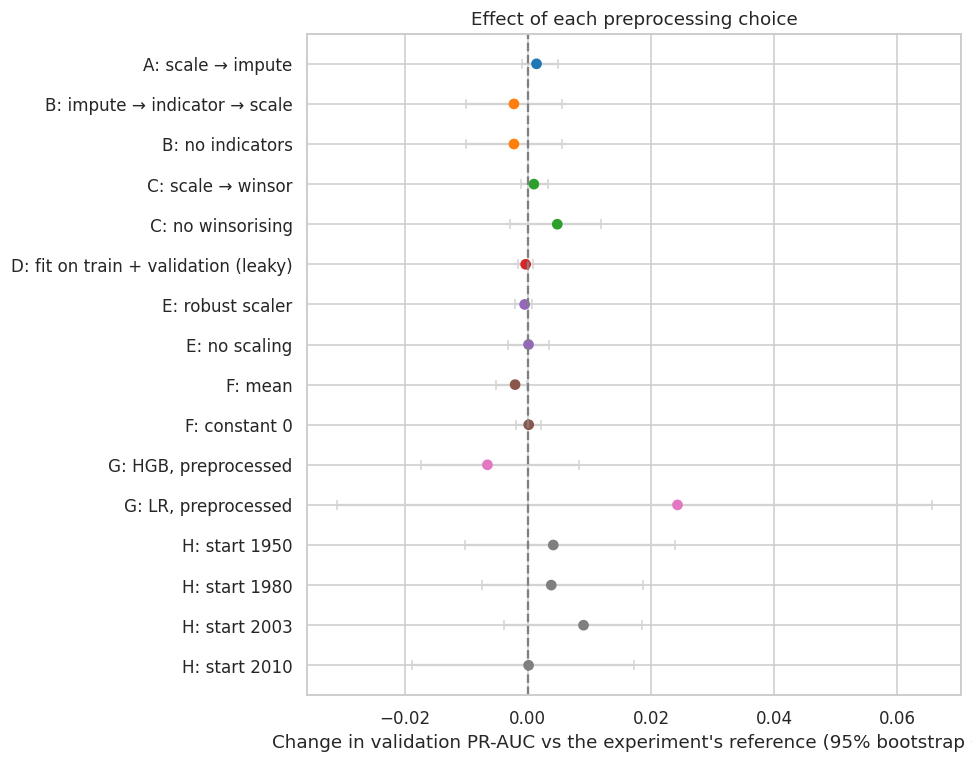

In [326]:
allr = pd.concat([s.assign(exp=e) for e, s in SUM.items()], ignore_index=True)
allr = allr[~allr.reference].copy()
allr["label"] = allr.exp + ": " + allr.variant
allr = allr.iloc[::-1]

colors = dict(zip(sorted(allr.exp.unique()), sns.color_palette("tab10", allr.exp.nunique())))
fig, ax = plt.subplots(figsize=(9, max(4, 0.35 * len(allr) + 1.5)))
y = np.arange(len(allr))
ax.errorbar(allr.d_pr_auc, y, xerr=[allr.d_pr_auc - allr.ci_low, allr.ci_high - allr.d_pr_auc],
            fmt="none", ecolor="lightgray", capsize=3, zorder=1)
ax.scatter(allr.d_pr_auc, y, c=[colors[e] for e in allr.exp], zorder=2)
ax.axvline(0, color="gray", ls="--")
ax.set_yticks(y); ax.set_yticklabels(allr.label)
ax.set_xlabel("Change in validation PR-AUC vs the experiment's reference (95% bootstrap CI)")
ax.set_title("Effect of each preprocessing choice")
plt.tight_layout(); save_fig("s6_experiments_forest"); plt.show()

exp_table = pd.concat(SUM.values(), keys=SUM.keys(), names=["exp"]).reset_index(level=0)
exp_table[["exp", "variant", "train_rows", "n_inputs", "val_roc_auc", "val_pr_auc",
           "d_pr_auc", "ci_low", "ci_high", "verdict"]].to_csv(OUT / "preprocessing_experiments.csv", index=False)

In [327]:
# Defaults follow the reasoning above. After reading tables A-H, change PREP_CFG if the evidence says so.
PREP_CFG = dict(order=("indicator", "impute", "winsor", "scale"), impute="median", scaler="standard", clip=(0.01, 0.99))

OVERRIDE_START = None        # set an int to override the automatic choice below
h = SUM["H"]
MODEL_START_FINAL = int(OVERRIDE_START or h.sort_values("val_pr_auc", ascending=False).iloc[0].variant.split()[1])
print("Training start chosen from experiment H:", MODEL_START_FINAL)

D["split"] = np.select(
    [(D.year >= MODEL_START_FINAL) & (D.year <= TRAIN_END),
     D.year.between(VAL_YEARS[0], VAL_YEARS[1]),
     D.year >= TEST_START],
    ["train", "val", "test"], default="unused")
mt_final = D.copy()                  # later sections use this table

split_tbl = (D.groupby("split").agg(rows=(TARGET, "size"), races=("raceId", "nunique"),
                                    first=("year", "min"), last=("year", "max"),
                                    podium_rate=(TARGET, "mean")).reindex(["train", "val", "test", "unused"]))
display(split_tbl)

tr_df, va_df, te_df = (D[D.split == s].copy() for s in ["train", "val", "test"])
prep_final = PodiumPrep(FEATURES, MISS_COLS, **PREP_CFG).fit(tr_df[FEATURES])      # statistics from train only
X_train, X_val = prep_final.transform(tr_df[FEATURES]), prep_final.transform(va_df[FEATURES])
X_test = prep_final.transform(te_df[FEATURES])      # transformed only; NOT evaluated in this section
y_train, y_val, y_test = tr_df[TARGET].values, va_df[TARGET].values, te_df[TARGET].values

for name, X in [("train", X_train), ("val", X_val), ("test", X_test)]:
    assert not X.isna().any().any() and list(X.columns) == list(X_train.columns)
    print(f"{name}: {X.shape}")
joblib.dump({"prep": prep_final, "features": FEATURES, "cfg": PREP_CFG}, OUT / "preprocessor.joblib")

Training start chosen from experiment H: 2003


,rows,races,first,last,podium_rate
split,,,,,
train,6783,321,2003,2019,0.1420
val,775,39,2020,2021,0.1510
test,1352,68,2022,2024,0.1509
unused,15676,686,1950,2002,0.1313


train: (6783, 42)
val: (775, 42)
test: (1352, 42)


['/kaggle/working/clean/preprocessor.joblib']

,stage,feature,missing,mean,std,min,max,skew
0,raw,qgap_pct,122,2.3740,2.6030,0.0000,37.7970,4.6690
1,raw,grid_vs_teammate,31,0.0000,5.0920,-23.0000,23.0000,0.0000
2,raw,drv_pod5,75,0.1430,0.2540,0.0000,1.0000,1.7940
3,raw,circ_move_hist,235,3.5490,0.7850,1.8240,6.5450,0.9080
4,raw,field_size,0,21.2840,1.6670,6.0000,24.0000,-0.3720
5,raw,d_pts_share_bef,0,0.2370,0.3000,0.0000,1.0000,1.2830
6,+ indicator,qgap_pct,122,2.3740,2.6030,0.0000,37.7970,4.6690
7,+ indicator,grid_vs_teammate,31,0.0000,5.0920,-23.0000,23.0000,0.0000
8,+ indicator,drv_pod5,75,0.1430,0.2540,0.0000,1.0000,1.7940
9,+ indicator,circ_move_hist,235,3.5490,0.7850,1.8240,6.5450,0.9080


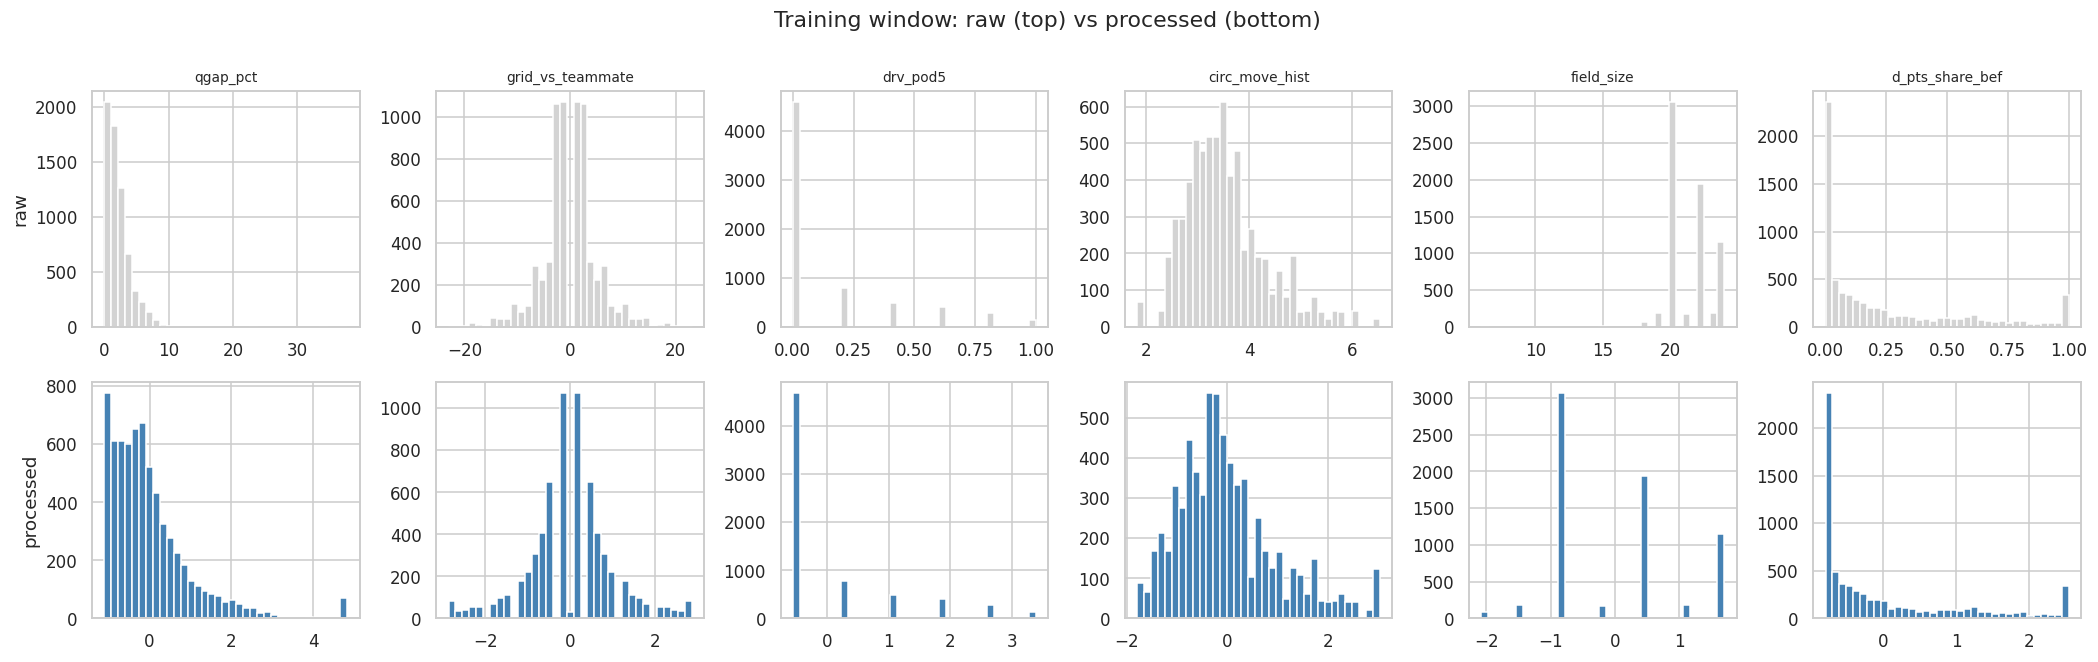

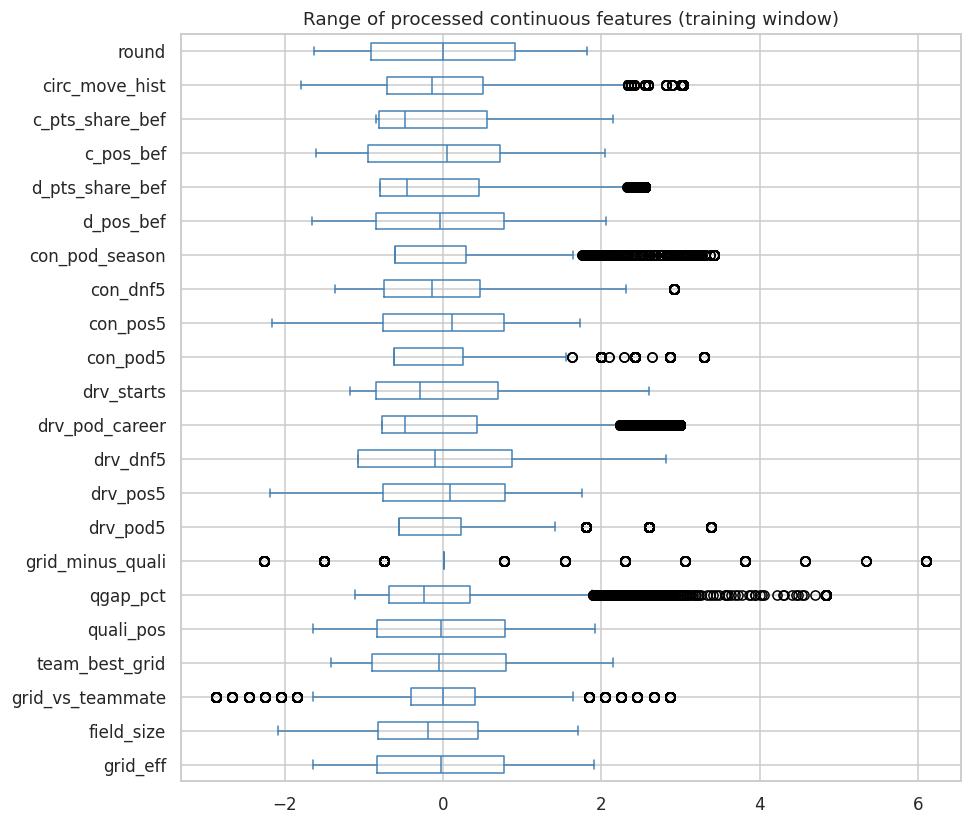

Missing cells before: 2080 | after: 0


In [328]:
SHOW = [f for f in ["qgap_pct", "grid_vs_teammate", "drv_pod5", "circ_move_hist", "field_size", "d_pts_share_bef"]
        if f in FEATURES]

def stats(s, stage, f):
    return {"stage": stage, "feature": f, "missing": int(s.isna().sum()), "mean": s.mean(), "std": s.std(),
            "min": s.min(), "max": s.max(), "skew": s.skew()}

rows = [stats(tr_df[f], "raw", f) for f in SHOW]
for k, step in enumerate(PREP_CFG["order"], start=1):
    pk = PodiumPrep(FEATURES, MISS_COLS, order=PREP_CFG["order"][:k], impute=PREP_CFG["impute"],
                    scaler=PREP_CFG["scaler"], clip=PREP_CFG["clip"], allow_nan=True).fit(tr_df[FEATURES])
    Xk = pk.transform(tr_df[FEATURES])
    rows += [stats(Xk[f], f"+ {step}", f) for f in SHOW]
stage_tbl = pd.DataFrame(rows)
display(stage_tbl.round(3))
stage_tbl.to_csv(OUT / "preprocessing_stage_stats.csv", index=False)

fig, axes = plt.subplots(2, len(SHOW), figsize=(3.2 * len(SHOW), 6))
for j, f in enumerate(SHOW):
    tr_df[f].dropna().plot(kind="hist", bins=35, ax=axes[0, j], color="lightgray")
    axes[0, j].set_title(f, fontsize=9)
    X_train[f].plot(kind="hist", bins=35, ax=axes[1, j], color="steelblue")
    axes[0, j].set_ylabel("raw" if j == 0 else ""); axes[1, j].set_ylabel("processed" if j == 0 else "")
plt.suptitle("Training window: raw (top) vs processed (bottom)", y=1.0)
plt.tight_layout(); save_fig("s6_before_after_hist"); plt.show()

cont = [c for c in X_train.columns if c in prep_final.cont_]
fig, ax = plt.subplots(figsize=(9, 0.28 * len(cont) + 1.5))
X_train[cont].plot(kind="box", vert=False, ax=ax, color="steelblue")
ax.set_title("Range of processed continuous features (training window)")
plt.tight_layout(); save_fig("s6_processed_ranges"); plt.show()

print("Missing cells before:", int(tr_df[FEATURES].isna().sum().sum()), "| after:", int(X_train.isna().sum().sum()))

## Preprocessing findings
- **Pipeline (fit on train only):** missing-value indicators, median imputation, winsorise at the 1st and 99th percentiles, standardise the continuous features. Binary flags are untouched. No categorical encoding is needed; IDs are excluded on purpose. On the final training window the model sees 42 inputs: 26 features plus 16 missing-value indicators.
- **A (impute vs scale order):** scale-then-impute changes validation PR-AUC by +0.0014 (95% CI -0.0010 to 0.0049), within noise.
- **B (indicator order):** creating the indicators after imputation leaves 0 indicator columns (26 inputs instead of 42) and changes PR-AUC by -0.0023 (CI -0.0101 to 0.0056), within noise. Order matters structurally: after imputation the "missing" information no longer exists. The order is kept because it preserves that information.
- **C (winsorising):** no winsorising is +0.0048 (CI -0.0030 to 0.0118) and scaling before winsorising is +0.0010 (-0.0011 to 0.0033); both within noise. Winsorising is kept for robustness: `qgap_pct` has a raw maximum of 37.8 in the final training window (922.9 in 1995-2019, caused by a 1,002.6 s qualifying time) that becomes 12.3, and its skew falls from 4.67 to 1.97.
- **D (fit scope):** fitting on train + validation changes PR-AUC by -0.0004 (CI -0.0017 to 0.0008). The effect is negligible, but it uses evaluation data, so the pipeline is fit on train only.
- **E / F (scaler and fill value):** robust scaler -0.0005 and no scaling +0.0001 are within noise. Mean fill is -0.0021 (CI -0.0051 to -0.0001), the only "worse" verdict, so median fill is kept; zero fill is +0.0001.
- **G (trees):** gradient boosting on raw NaN scores 0.699 and on preprocessed data 0.693 (-0.0066, within noise), so trees do not need the preprocessing; logistic regression on preprocessed data scores 0.724 (+0.0243, CI -0.0310 to 0.0656, within noise).
- **H (training start):** a 2003 start has the best validation PR-AUC (0.733 vs 0.724 for 1995; +0.0090, CI -0.0038 to 0.0186), but every start year (1950: 0.728, 1980: 0.728, 2010: 0.724) is within noise. 2003 is chosen as the best point estimate and because qualifying coverage is complete from 2003 (Section 2). The training window is 2003-2019 (6,783 rows, 321 races); the 15,676 earlier rows only feed history features.
- **Distribution effect:** missing cells in the training window fall from 2,080 to 0; standardised features have mean 0 and standard deviation 1; for example `field_size` is clipped to 18-24.
- **Caveat:** differences between preprocessing variants are far smaller than the bootstrap interval, so the pipeline is justified mainly on methodological grounds (no leakage, no lost information, robustness to outliers).

# 7. Train / Validation / Test Split

**Split (by season, whole races kept together):**
| Split | Seasons | Role |
|---|---|---|
| train | `MODEL_START_FINAL` to 2019 | fit models |
| validation | 2020-2021 | choose hyperparameters, thresholds, model family |
| test | 2022-2024 | unseen; scored once at the end |

**Why a time-based split, not a random one**
- The task is forecasting future races. A random split lets the model train on races from the same season and car generation as the rows it is tested on, which is not possible in deployment and inflates scores.
- Form and standings features were built from past races only (leakage test in Section 5), so validation and test rows legitimately use history from earlier splits.
- 2022 is a regulation reset (ground-effect cars), so the test set is a real out-of-time, out-of-era check. Validation (2020-2021) is the last stretch of the hybrid era and is the closest proxy for it.
- Whole races never straddle two splits, so no race contributes both training and evaluation rows.

**Known weaknesses:** validation is only two seasons (2020 was COVID-shortened), and test has three seasons, so metric differences need uncertainty estimates (race-level bootstrap below).

In [329]:
sp = split_tbl.loc[["train", "val", "test"]].copy()
sp["podiums"] = (sp.rows * sp.podium_rate).round().astype(int)
sp["share_of_rows"] = sp.rows / sp.rows.sum()
sp["share_of_races"] = sp.races / sp.races.sum()
display(sp.round(3))

checks = {}
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    checks[f"races shared by {a} and {b}"] = len(
        set(mt_final.loc[mt_final.split == a, "raceId"]) & set(mt_final.loc[mt_final.split == b, "raceId"]))
for nm, d in [("train", tr_df), ("val", va_df), ("test", te_df)]:
    checks[f"duplicate (raceId, driverId) in {nm}"] = int(d.duplicated(["raceId", "driverId"]).sum())
display(pd.Series(checks, name="count").to_frame())

assert all(v == 0 for v in checks.values()), "split integrity violated"
assert tr_df.year.max() < va_df.year.min() and va_df.year.max() < te_df.year.min(), "splits overlap in time"
print(f"Train {tr_df.year.min()}-{tr_df.year.max()} | Val {va_df.year.min()}-{va_df.year.max()} | "
      f"Test {te_df.year.min()}-{te_df.year.max()}")

,rows,races,first,last,podium_rate,podiums,share_of_rows,share_of_races
split,,,,,,,,
train,6783,321,2003,2019,0.1420,963,0.7610,0.7500
val,775,39,2020,2021,0.1510,117,0.0870,0.0910
test,1352,68,2022,2024,0.1510,204,0.1520,0.1590


,count
races shared by train and val,0
races shared by train and test,0
races shared by val and test,0
"duplicate (raceId, driverId) in train",0
"duplicate (raceId, driverId) in val",0
"duplicate (raceId, driverId) in test",0


Train 2003-2019 | Val 2020-2021 | Test 2022-2024


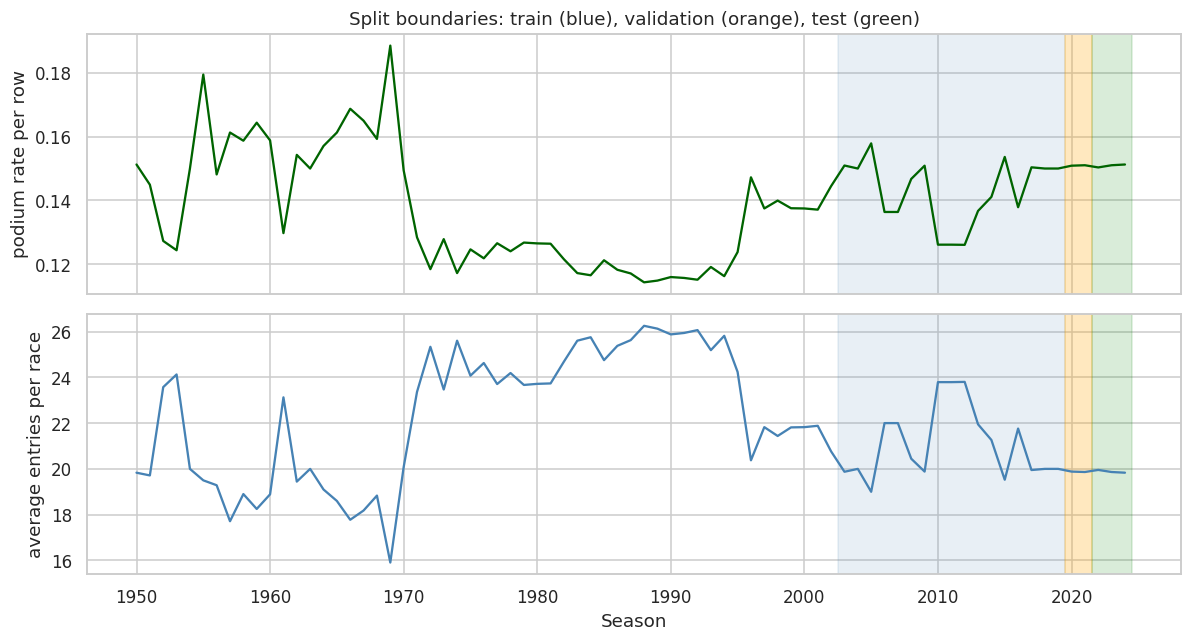

In [330]:
season = D.groupby("year").agg(rows=(TARGET, "size"), races=("raceId", "nunique"), pod=(TARGET, "mean"))
season["field"] = season.rows / season.races

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(season.index, season.pod, color="darkgreen"); axes[0].set_ylabel("podium rate per row")
axes[1].plot(season.index, season.field, color="steelblue"); axes[1].set_ylabel("average entries per race")
for ax in axes:
    ax.axvspan(MODEL_START_FINAL - 0.5, TRAIN_END + 0.5, color="steelblue", alpha=0.12)
    ax.axvspan(VAL_YEARS[0] - 0.5, VAL_YEARS[1] + 0.5, color="orange", alpha=0.25)
    ax.axvspan(TEST_START - 0.5, D.year.max() + 0.5, color="green", alpha=0.15)
axes[1].set_xlabel("Season")
axes[0].set_title("Split boundaries: train (blue), validation (orange), test (green)")
plt.tight_layout(); save_fig("s7_split_timeline"); plt.show()

,podium_rate,avg_field
train,0.1420,21.1310
val,0.1510,19.8720
test,0.1510,19.8820


,ks_val,std_shift_val,ks_test,std_shift_test
feature,,,,
field_size,0.5070,-0.8430,0.5070,-0.8360
circ_move_hist,0.3720,-0.5420,0.2990,-0.5630
drv_starts,0.1240,0.3530,0.2670,0.6670
con_dnf5,0.2080,-0.4820,0.2130,-0.5070
drv_dnf5,0.1660,-0.3880,0.1600,-0.4030
qgap_pct,0.0870,-0.1290,0.1590,-0.1840
round,0.0520,0.0730,0.1460,0.3310
drv_pod_career,0.1050,0.0840,0.1320,0.0380
d_pts_share_bef,0.0790,0.0110,0.1170,0.0050


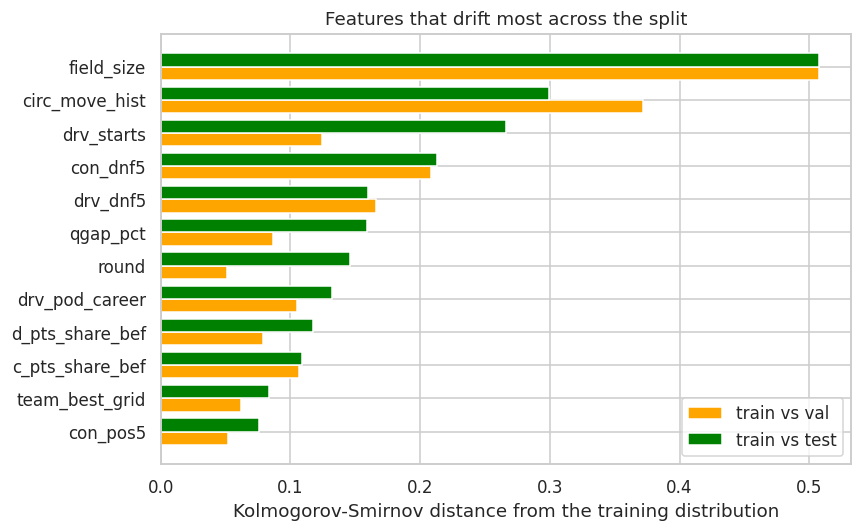

In [331]:
from scipy.stats import ks_2samp

lab = pd.DataFrame({
    "podium_rate": [d[TARGET].mean() for d in (tr_df, va_df, te_df)],
    "avg_field": [d.groupby("raceId").size().mean() for d in (tr_df, va_df, te_df)],
}, index=["train", "val", "test"])
display(lab.round(3))

drift = []
for f in FEATURES:
    a = tr_df[f].dropna(); row = {"feature": f}
    for nm, d in [("val", va_df), ("test", te_df)]:
        b = d[f].dropna()
        row[f"ks_{nm}"] = ks_2samp(a, b).statistic if len(a) > 5 and len(b) > 5 else np.nan
        row[f"std_shift_{nm}"] = (b.mean() - a.mean()) / (a.std() if a.std() > 0 else 1.0) if len(b) else np.nan
    drift.append(row)
drift = pd.DataFrame(drift).set_index("feature").sort_values("ks_test", ascending=False)
display(drift.head(12).round(3))

top = drift.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
y = np.arange(len(top))
ax.barh(y - 0.2, top.ks_val, 0.4, label="train vs val", color="orange")
ax.barh(y + 0.2, top.ks_test, 0.4, label="train vs test", color="green")
ax.set_yticks(y); ax.set_yticklabels(top.index)
ax.set_xlabel("Kolmogorov-Smirnov distance from the training distribution")
ax.set_title("Features that drift most across the split"); ax.legend()
plt.tight_layout(); save_fig("s7_feature_drift"); plt.show()

,roc_auc,pr_auc,pr_lift
time-based (train<=2019 -> val),0.9320,0.7330,4.8530
"random race split, mean of 20",0.9340,0.7120,4.9670
"random race split, std",0.0100,0.0450,0.3140


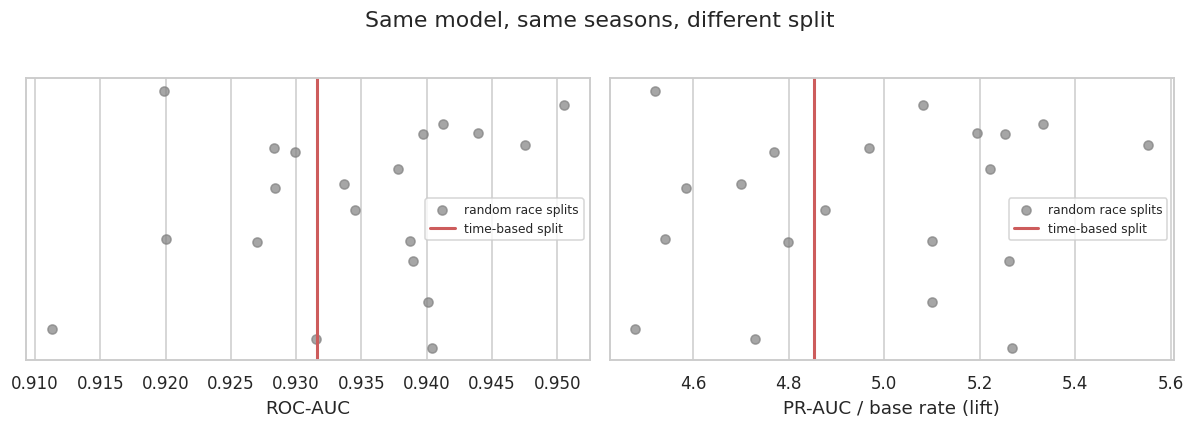

In [332]:
from sklearn.model_selection import GroupShuffleSplit

pool = pd.concat([tr_df, va_df]).reset_index(drop=True)      # test seasons stay untouched

def fit_eval(trn, tst):
    pr = PodiumPrep(FEATURES, MISS_COLS, **PREP_CFG).fit(trn[FEATURES])
    m = LogisticRegression(max_iter=3000).fit(pr.transform(trn[FEATURES]), trn[TARGET])
    p = m.predict_proba(pr.transform(tst[FEATURES]))[:, 1]
    ap = average_precision_score(tst[TARGET], p)
    return {"roc_auc": roc_auc_score(tst[TARGET], p), "pr_auc": ap, "pr_lift": ap / tst[TARGET].mean()}

temporal = fit_eval(tr_df, va_df)
frac = va_df.raceId.nunique() / pool.raceId.nunique()
rand = []
for s in range(20):
    i_tr, i_te = next(GroupShuffleSplit(n_splits=1, test_size=frac, random_state=s).split(pool, groups=pool.raceId))
    rand.append(fit_eval(pool.iloc[i_tr], pool.iloc[i_te]))
rand = pd.DataFrame(rand)

cmp_split = pd.DataFrame({"time-based (train<=2019 -> val)": temporal,
                          "random race split, mean of 20": rand.mean(),
                          "random race split, std": rand.std()}).T
display(cmp_split.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col, lab_ in zip(axes, ["roc_auc", "pr_lift"], ["ROC-AUC", "PR-AUC / base rate (lift)"]):
    ax.scatter(rand[col], np.random.default_rng(SEED).uniform(-0.15, 0.15, len(rand)), alpha=0.7,
               color="gray", label="random race splits")
    ax.axvline(temporal[col], color="indianred", lw=2, label="time-based split")
    ax.set_yticks([]); ax.set_xlabel(lab_); ax.legend(fontsize=8)
plt.suptitle("Same model, same seasons, different split", y=1.02)
plt.tight_layout(); save_fig("s7_random_vs_time"); plt.show()

## Split findings
- **Sizes:** train 6,783 rows / 321 races (2003-2019; 76% of rows, 75% of races, 963 podiums), validation 775 / 39 (2020-2021; 9% / 9%, 117 podiums), test 1,352 / 68 (2022-2024; 15% / 16%, 204 podiums). Podium rate: 14.2% / 15.1% / 15.1%.
- **Integrity:** no race appears in more than one split, there are no duplicate (raceId, driverId) rows in any split, and the splits are strictly ordered in time.
- **Drift:** the largest train-to-test shifts are in `field_size` (KS distance 0.51; the average field shrank from 21.1 to 19.9 entries), `circ_move_hist` (0.30), `drv_starts` (0.27), `con_dnf5` (0.21), `drv_dnf5` (0.16) and `qgap_pct` (0.16). The key pace feature `team_best_grid` barely moves (0.08), consistent with the 2022 regulation change affecting reliability and field structure more than grid-to-podium conversion.
- **Random vs time split:** on the same 2003-2021 seasons the time-based split gives ROC-AUC 0.932 and PR-AUC 0.733 (lift 4.85); 20 random race splits give ROC-AUC 0.934 +/- 0.010 and PR-AUC 0.712 +/- 0.045 (lift 4.97 +/- 0.31). The numbers are about the same, so a random split would not be clearly optimistic here, but it answers a question we are not asking (interpolating inside seasons), so the time split is kept.
- **Limitation:** validation is only two seasons (775 rows, 117 podiums), so model selection has high variance; differences are judged with race-level bootstrap intervals.

# 8. Predictive Modeling

**Task:** binary classification, podium vs not. All models use the **same rows and the same preprocessed feature matrices** (`X_train`, `X_val`, `X_test` from Section 6).

**Protocol:** fit on train; hyperparameters, model family and decision threshold are chosen on **validation only**; the test set is scored **once**, after everything is frozen.

**Metrics:** ROC-AUC, PR-AUC and F1 for every model on train, validation and test. Extra diagnostics: precision, recall, and top-3 precision (of the three drivers ranked highest in each race, the share who podium).
- **Primary metric: PR-AUC.** Podiums are about 15% of rows or fewer, so PR-AUC focuses on ranking the rare positives and is more informative than ROC-AUC when the positive class is rare. It is threshold-free, so model comparison is not confounded by threshold choice.
- **Secondary: ROC-AUC** (overall separation, easier to compare with other work).
- **F1** needs a threshold, which is chosen on validation by maximising F1. Validation F1 is therefore optimistic by construction; the test F1 is the honest figure.

**Attempts (each in its own section, with a before/after against the baseline)**
| # | Model | How it works | Main limitation |
|---|---|---|---|
| 1 | Logistic regression (baseline) | weighted sum of features passed through a sigmoid; linear in the log-odds | cannot learn interactions (for example grid x constructor strength) unless engineered |
| 2 | Logistic regression, tuned | same, with L2 strength and class weighting tuned | still linear |
| 3 | Random forest | many decorrelated decision trees on bootstrap samples, probabilities averaged | probabilities are poorly calibrated; no extrapolation beyond the training range |
| 4 | Gradient boosting (HistGradientBoosting) | shallow trees added sequentially, each correcting the previous ones' errors | sensitive to hyperparameters; can overfit small validation sets |
| 5 | Neural network, 1 hidden layer | ReLU hidden layer with dropout and weight decay, trained with Adam | needs scaled inputs, seed-sensitive, hard to interpret |
| 6 | Neural network, 2 hidden layers | same with two hidden layers | same, plus more parameters for ~10^4 rows |

**Reference rows (not counted as models):** the rule "podium if grid <= 3" and logistic regression on grid alone, to show how much the full feature set adds.

In [333]:
import time
import torch
import torch.nn as nn
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import (f1_score, precision_score, recall_score, roc_curve,
                             precision_recall_curve, ConfusionMatrixDisplay)

torch.manual_seed(SEED); np.random.seed(SEED)
torch.set_num_threads(max(1, (os.cpu_count() or 2) // 2))

rid_tr, rid_va, rid_te = tr_df.raceId.values, va_df.raceId.values, te_df.raceId.values

def best_threshold(y, p):
    pr, rc, th = precision_recall_curve(y, p)
    f1 = 2 * pr[:-1] * rc[:-1] / np.clip(pr[:-1] + rc[:-1], 1e-12, None)
    i = int(np.nanargmax(f1))
    return float(th[i]), float(f1[i])

def top3_prec(rids, y, p):
    d = pd.DataFrame({"r": rids, "y": y, "p": p})
    d["rk"] = d.groupby("r")["p"].rank(method="first", ascending=False)
    return float(d.loc[d.rk <= 3, "y"].mean())

def metric_row(y, p, thr, rids):
    yhat = p >= thr
    return {"roc_auc": roc_auc_score(y, p), "pr_auc": average_precision_score(y, p),
            "f1": f1_score(y, yhat), "precision": precision_score(y, yhat, zero_division=0),
            "recall": recall_score(y, yhat), "top3_prec": top3_prec(rids, y, p)}

def make_boot(rids, n=400, seed=SEED):
    rng = np.random.default_rng(seed)
    groups = [np.where(rids == r)[0] for r in pd.unique(rids)]
    return [np.concatenate([groups[i] for i in rng.integers(0, len(groups), len(groups))]) for _ in range(n)]

BOOT_VAL, BOOT_TEST = make_boot(rid_va), make_boot(rid_te, seed=SEED + 1)

def pr_boot(y, p, boot):
    return np.array([average_precision_score(y[ix], p[ix]) for ix in boot])

# Registries
MAKERS, BEST_PARAMS, FITTED, TRAIN_P, VAL_P, TEST_P, THR, FAMILY, TUNING = {}, {}, {}, {}, {}, {}, {}, {}, {}
TEST_EVALUATED = False
BASE = "LR baseline"
_ref_boot = {}

def val_summary(names, ref=BASE):
    rows = []
    for n in names:
        tr_m = metric_row(y_train, TRAIN_P[n], THR[n], rid_tr)
        va_m = metric_row(y_val, VAL_P[n], THR[n], rid_va)
        row = {"model": n, "threshold": THR[n], "train_pr_auc": tr_m["pr_auc"], "val_pr_auc": va_m["pr_auc"],
               "val_roc_auc": va_m["roc_auc"], "val_f1": va_m["f1"], "pr_gap_train_minus_val": tr_m["pr_auc"] - va_m["pr_auc"]}
        if ref in VAL_P and n != ref:
            if ref not in _ref_boot:
                _ref_boot[ref] = pr_boot(y_val, VAL_P[ref], BOOT_VAL)
            d = pr_boot(y_val, VAL_P[n], BOOT_VAL) - _ref_boot[ref]
            lo, hi = np.percentile(d, 2.5), np.percentile(d, 97.5)
            row.update({"d_pr_vs_baseline": va_m["pr_auc"] - average_precision_score(y_val, VAL_P[ref]),
                        "ci_low": lo, "ci_high": hi,
                        "verdict": "within noise" if lo <= 0 <= hi else ("better" if lo > 0 else "worse")})
        rows.append(row)
    return pd.DataFrame(rows).set_index("model").round(4)

def register(name, model, family, maker=None, params=None):
    FITTED[name], FAMILY[name], MAKERS[name], BEST_PARAMS[name] = model, family, maker, params
    TRAIN_P[name] = model.predict_proba(X_train)[:, 1]
    VAL_P[name] = model.predict_proba(X_val)[:, 1]
    THR[name] = best_threshold(y_val, VAL_P[name])[0]
    return val_summary([name])

def tune(make, grid):
    rows, best = [], (-1, None, None)
    t0 = time.time()
    for prm in ParameterGrid(grid):
        m = make(**prm).fit(X_train, y_train)
        p_tr, p_va = m.predict_proba(X_train)[:, 1], m.predict_proba(X_val)[:, 1]
        s = average_precision_score(y_val, p_va)
        rows.append({**{k: str(v) for k, v in prm.items()}, "train_pr_auc": average_precision_score(y_train, p_tr),
                     "val_pr_auc": s, "val_roc_auc": roc_auc_score(y_val, p_va)})
        if s > best[0]:
            best = (s, m, prm)
    tab = pd.DataFrame(rows).sort_values("val_pr_auc", ascending=False).reset_index(drop=True)
    print(f"{len(rows)} configurations in {time.time() - t0:.0f}s | best validation PR-AUC {best[0]:.4f} with {best[2]}")
    return best[1], best[2], tab

print("Rows: train", len(y_train), "| val", len(y_val), "| test", len(y_test),
      "| podium rate:", round(y_train.mean(), 3), round(y_val.mean(), 3), round(y_test.mean(), 3))

Rows: train 6783 | val 775 | test 1352 | podium rate: 0.142 0.151 0.151


In [334]:
GRID_COL = next(f for f in ["grid_eff", "grid", "quali_pos"] if f in FEATURES)
g_fill = tr_df[GRID_COL].max() + 1
print("Reference grid column:", GRID_COL)

def grid_rule_p(df):
    g = df[GRID_COL].fillna(g_fill).clip(lower=1)
    return (1.0 / (1.0 + g)).values                  # monotone in grid; 0.25 <=> grid 3

lr_grid = LogisticRegression(max_iter=3000).fit(X_train[[GRID_COL]], y_train)
REF_PRED = {"Ref: rule grid <= 3": lambda df, X: grid_rule_p(df),
            "Ref: LR on grid only": lambda df, X: lr_grid.predict_proba(X[[GRID_COL]])[:, 1]}
REF_VAL = {n: f(va_df, X_val) for n, f in REF_PRED.items()}
REF_THR = {"Ref: rule grid <= 3": 0.25,
           "Ref: LR on grid only": best_threshold(y_val, REF_VAL["Ref: LR on grid only"])[0]}

ref_tbl = pd.DataFrame({n: metric_row(y_val, REF_VAL[n], REF_THR[n], rid_va) for n in REF_PRED}).T
display(ref_tbl.round(4))

Reference grid column: grid_eff


,roc_auc,pr_auc,f1,precision,recall,top3_prec
Ref: rule grid <= 3,0.9102,0.6478,0.6953,0.6983,0.6923,0.7009
Ref: LR on grid only,0.9102,0.6478,0.6953,0.6983,0.6923,0.7009


In [335]:
mk_lr = lambda **p: LogisticRegression(max_iter=3000, **p)
m_base = mk_lr().fit(X_train, y_train)
display(register(BASE, m_base, "statistical", mk_lr, {}))

,threshold,train_pr_auc,val_pr_auc,val_roc_auc,val_f1,pr_gap_train_minus_val
model,,,,,,
LR baseline,0.2330,0.6986,0.7327,0.9316,0.7104,-0.0341


In [336]:
grid_lr = {"C": [0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10], "class_weight": [None, "balanced"]}
m, prm, tab = tune(mk_lr, grid_lr)
TUNING["LR tuned"] = tab
display(tab.head(6).round(4))
display(register("LR tuned", m, "statistical", mk_lr, prm))

16 configurations in 1s | best validation PR-AUC 0.7360 with {'C': 10, 'class_weight': None}


,C,class_weight,train_pr_auc,val_pr_auc,val_roc_auc
0,10,None,0.6994,0.7360,0.9327
1,3,None,0.6992,0.7339,0.9323
2,1,None,0.6986,0.7327,0.9316
3,0.3,None,0.6974,0.7297,0.9306
4,10,balanced,0.6894,0.7285,0.9304
5,3,balanced,0.6892,0.7282,0.9303


,threshold,train_pr_auc,val_pr_auc,val_roc_auc,val_f1,pr_gap_train_minus_val,d_pr_vs_baseline,ci_low,ci_high,verdict
model,,,,,,,,,,
LR tuned,0.2375,0.6994,0.7360,0.9327,0.7054,-0.0366,0.0033,-0.0004,0.0072,within noise


In [337]:
mk_rf = lambda **p: RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED, **p)
grid_rf = {"max_depth": [4, 8, None], "min_samples_leaf": [10, 40], "max_features": ["sqrt", 0.5]}
m, prm, tab = tune(mk_rf, grid_rf)
TUNING["Random forest"] = tab
display(tab.head(6).round(4))
display(register("Random forest", m, "statistical", mk_rf, prm))

12 configurations in 30s | best validation PR-AUC 0.7302 with {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 40}


,max_depth,max_features,min_samples_leaf,train_pr_auc,val_pr_auc,val_roc_auc
0,None,0.5,40,0.7603,0.7302,0.9329
1,None,sqrt,40,0.7420,0.7297,0.9322
2,8,0.5,40,0.7594,0.7295,0.9335
3,8,sqrt,40,0.7412,0.7265,0.9325
4,4,sqrt,10,0.7258,0.7240,0.9298
5,4,0.5,40,0.7311,0.7235,0.9318


,threshold,train_pr_auc,val_pr_auc,val_roc_auc,val_f1,pr_gap_train_minus_val,d_pr_vs_baseline,ci_low,ci_high,verdict
model,,,,,,,,,,
Random forest,0.3139,0.7603,0.7302,0.9329,0.7126,0.0302,-0.0025,-0.0491,0.0352,within noise


In [338]:
mk_hgb = lambda **p: HistGradientBoostingClassifier(early_stopping=False, random_state=SEED, **p)
grid_hgb = {"learning_rate": [0.03, 0.1], "max_depth": [2, 3, 5], "max_iter": [100, 300],
            "l2_regularization": [0.0, 1.0], "min_samples_leaf": [20, 60]}
m, prm, tab = tune(mk_hgb, grid_hgb)
TUNING["Gradient boosting"] = tab
display(tab.head(6).round(4))
display(register("Gradient boosting", m, "statistical", mk_hgb, prm))

48 configurations in 28s | best validation PR-AUC 0.7320 with {'l2_regularization': 1.0, 'learning_rate': 0.03, 'max_depth': 2, 'max_iter': 100, 'min_samples_leaf': 60}


,l2_regularization,learning_rate,max_depth,max_iter,min_samples_leaf,train_pr_auc,val_pr_auc,val_roc_auc
0,1.0,0.03,2,100,60,0.7149,0.7320,0.9336
1,1.0,0.03,2,100,20,0.7151,0.7319,0.9337
2,0.0,0.03,2,100,20,0.7147,0.7315,0.9336
3,0.0,0.03,2,100,60,0.7144,0.7311,0.9335
4,1.0,0.03,5,100,20,0.8065,0.7288,0.9309
5,0.0,0.03,3,100,20,0.7356,0.7261,0.9335


,threshold,train_pr_auc,val_pr_auc,val_roc_auc,val_f1,pr_gap_train_minus_val,d_pr_vs_baseline,ci_low,ci_high,verdict
model,,,,,,,,,,
Gradient boosting,0.3355,0.7149,0.7320,0.9336,0.7227,-0.0171,-0.0007,-0.0399,0.0388,within noise


In [339]:
class ShallowNet(nn.Module):
    def __init__(self, d_in, hidden=(32,), dropout=0.2):
        super().__init__()
        layers, d = [], d_in
        for h in hidden:
            layers += [nn.Linear(d, h), nn.ReLU(), nn.Dropout(dropout)]
            d = h
        layers.append(nn.Linear(d, 1))
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x).squeeze(-1)

class TorchMLP:
    """Early stopping on VALIDATION loss (validation data is allowed for model selection)."""
    def __init__(self, hidden=(32,), dropout=0.2, weight_decay=1e-3, lr=1e-3, batch=256,
                 max_epochs=150, patience=12, seed=SEED, val=None):
        self.hidden, self.dropout, self.weight_decay, self.lr = hidden, dropout, weight_decay, lr
        self.batch, self.max_epochs, self.patience, self.seed, self.val = batch, max_epochs, patience, seed, val
        self.classes_ = np.array([0, 1])

    def fit(self, X, y):
        torch.manual_seed(self.seed)
        Xt = torch.tensor(np.asarray(X, dtype=np.float32)); yt = torch.tensor(np.asarray(y, dtype=np.float32))
        Xv = torch.tensor(np.asarray(self.val[0], dtype=np.float32)); yv = torch.tensor(np.asarray(self.val[1], dtype=np.float32))
        self.net = ShallowNet(Xt.shape[1], self.hidden, self.dropout)
        opt = torch.optim.AdamW(self.net.parameters(), lr=self.lr, weight_decay=self.weight_decay)
        loss_fn = nn.BCEWithLogitsLoss()
        g = torch.Generator().manual_seed(self.seed)
        best, best_state, wait, self.history = np.inf, None, 0, []
        for ep in range(self.max_epochs):
            self.net.train()
            perm = torch.randperm(len(Xt), generator=g)
            for i in range(0, len(Xt), self.batch):
                idx = perm[i:i + self.batch]
                opt.zero_grad()
                loss_fn(self.net(Xt[idx]), yt[idx]).backward()
                opt.step()
            self.net.eval()
            with torch.no_grad():
                tl, vl = loss_fn(self.net(Xt), yt).item(), loss_fn(self.net(Xv), yv).item()
            self.history.append({"epoch": ep + 1, "train_loss": tl, "val_loss": vl})
            if vl < best - 1e-4:
                best, best_state, wait = vl, copy.deepcopy(self.net.state_dict()), 0
            else:
                wait += 1
                if wait >= self.patience:
                    break
        self.net.load_state_dict(best_state); self.net.eval()
        self.best_epoch = int(np.argmin([h["val_loss"] for h in self.history])) + 1
        return self

    def predict_proba(self, X):
        self.net.eval()
        with torch.no_grad():
            p = torch.sigmoid(self.net(torch.tensor(np.asarray(X, dtype=np.float32)))).numpy()
        return np.c_[1 - p, p]

mk_nn = lambda **p: TorchMLP(val=(X_val, y_val), **p)
print("PyTorch", torch.__version__, "| input width:", X_train.shape[1])

PyTorch 2.11.0+cpu | input width: 42


In [340]:
grid_nn1 = {"hidden": [(16,), (32,), (64,)], "dropout": [0.1, 0.3], "weight_decay": [1e-4, 1e-2]}
m, prm, tab = tune(mk_nn, grid_nn1)
TUNING["NN 1 hidden layer"] = tab
display(tab.head(6).round(4))
display(register("NN 1 hidden layer", m, "neural", mk_nn, prm))
print("Best epoch (early stopping on validation loss):", m.best_epoch)

12 configurations in 30s | best validation PR-AUC 0.7345 with {'dropout': 0.3, 'hidden': (32,), 'weight_decay': 0.0001}


,dropout,hidden,weight_decay,train_pr_auc,val_pr_auc,val_roc_auc
0,0.3,"(32,)",0.0001,0.7176,0.7345,0.9281
1,0.1,"(16,)",0.0001,0.7137,0.7338,0.9279
2,0.1,"(16,)",0.01,0.7136,0.7336,0.9278
3,0.3,"(32,)",0.01,0.7174,0.7335,0.9279
4,0.1,"(32,)",0.01,0.7241,0.7331,0.9284
5,0.1,"(32,)",0.0001,0.7125,0.7282,0.9287


,threshold,train_pr_auc,val_pr_auc,val_roc_auc,val_f1,pr_gap_train_minus_val,d_pr_vs_baseline,ci_low,ci_high,verdict
model,,,,,,,,,,
NN 1 hidden layer,0.4217,0.7176,0.7345,0.9281,0.7018,-0.0169,0.0018,-0.0257,0.0267,within noise


Best epoch (early stopping on validation loss): 56


In [341]:
grid_nn2 = {"hidden": [(32, 16), (64, 32)], "dropout": [0.1, 0.3], "weight_decay": [1e-4, 1e-2]}
m, prm, tab = tune(mk_nn, grid_nn2)
TUNING["NN 2 hidden layers"] = tab
display(tab.head(6).round(4))
display(register("NN 2 hidden layers", m, "neural", mk_nn, prm))
print("Best epoch (early stopping on validation loss):", m.best_epoch)

8 configurations in 17s | best validation PR-AUC 0.7290 with {'dropout': 0.1, 'hidden': (32, 16), 'weight_decay': 0.0001}


,dropout,hidden,weight_decay,train_pr_auc,val_pr_auc,val_roc_auc
0,0.1,"(32, 16)",0.0001,0.7131,0.7290,0.9271
1,0.1,"(64, 32)",0.01,0.7277,0.7274,0.9277
2,0.1,"(32, 16)",0.01,0.7129,0.7260,0.9270
3,0.1,"(64, 32)",0.0001,0.7283,0.7251,0.9276
4,0.3,"(32, 16)",0.0001,0.7093,0.7195,0.9266
5,0.3,"(32, 16)",0.01,0.7093,0.7177,0.9264


,threshold,train_pr_auc,val_pr_auc,val_roc_auc,val_f1,pr_gap_train_minus_val,d_pr_vs_baseline,ci_low,ci_high,verdict
model,,,,,,,,,,
NN 2 hidden layers,0.4229,0.7131,0.7290,0.9271,0.7018,-0.0159,-0.0038,-0.0273,0.0194,within noise


Best epoch (early stopping on validation loss): 27


Better network on validation PR-AUC: NN 1 hidden layer {'dropout': 0.3, 'hidden': (32,), 'weight_decay': 0.0001}


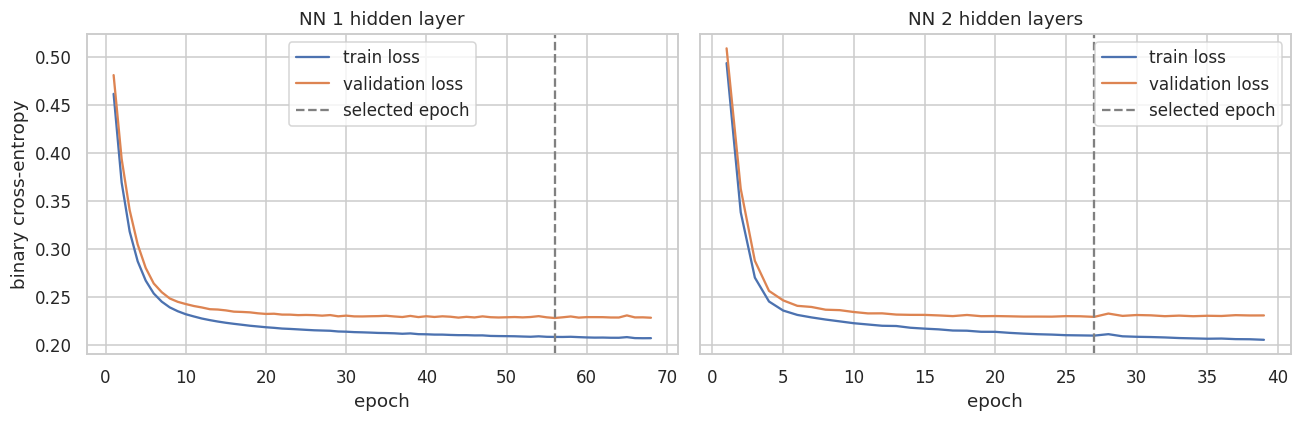

,seed,val_pr_auc,val_roc_auc,best_epoch
0,0,0.7366,0.9280,99
1,1,0.7217,0.9264,57
2,2,0.7133,0.9265,80
3,3,0.7230,0.9275,54
4,4,0.7335,0.9275,78


Validation PR-AUC over 5 seeds: 0.7256 +/- 0.0095


In [342]:
NN_NAMES = ["NN 1 hidden layer", "NN 2 hidden layers"]
nn_best = max(NN_NAMES, key=lambda n: average_precision_score(y_val, VAL_P[n]))
print("Better network on validation PR-AUC:", nn_best, BEST_PARAMS[nn_best])

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, n in zip(axes, NN_NAMES):
    h = pd.DataFrame(FITTED[n].history)
    ax.plot(h.epoch, h.train_loss, label="train loss"); ax.plot(h.epoch, h.val_loss, label="validation loss")
    ax.axvline(FITTED[n].best_epoch, color="gray", ls="--", label="selected epoch")
    ax.set_title(n); ax.set_xlabel("epoch"); ax.legend()
axes[0].set_ylabel("binary cross-entropy")
plt.tight_layout(); save_fig("s8_nn_training_curves"); plt.show()

rows = []
for s in range(5):
    m = TorchMLP(val=(X_val, y_val), seed=s, **BEST_PARAMS[nn_best]).fit(X_train, y_train)
    p = m.predict_proba(X_val)[:, 1]
    rows.append({"seed": s, "val_pr_auc": average_precision_score(y_val, p),
                 "val_roc_auc": roc_auc_score(y_val, p), "best_epoch": m.best_epoch})
seeds = pd.DataFrame(rows)
display(seeds.round(4))
print(f"Validation PR-AUC over 5 seeds: {seeds.val_pr_auc.mean():.4f} +/- {seeds.val_pr_auc.std():.4f}")

,threshold,train_pr_auc,val_pr_auc,val_roc_auc,val_f1,pr_gap_train_minus_val,d_pr_vs_baseline,ci_low,ci_high,verdict
model,,,,,,,,,,
LR baseline,0.2330,0.6986,0.7327,0.9316,0.7104,-0.0341,NaN,NaN,NaN,NaN
LR tuned,0.2375,0.6994,0.7360,0.9327,0.7054,-0.0366,0.0033,-0.0004,0.0072,within noise
Random forest,0.3139,0.7603,0.7302,0.9329,0.7126,0.0302,-0.0025,-0.0491,0.0352,within noise
Gradient boosting,0.3355,0.7149,0.7320,0.9336,0.7227,-0.0171,-0.0007,-0.0399,0.0388,within noise
NN 1 hidden layer,0.4217,0.7176,0.7345,0.9281,0.7018,-0.0169,0.0018,-0.0257,0.0267,within noise
NN 2 hidden layers,0.4229,0.7131,0.7290,0.9271,0.7018,-0.0159,-0.0038,-0.0273,0.0194,within noise


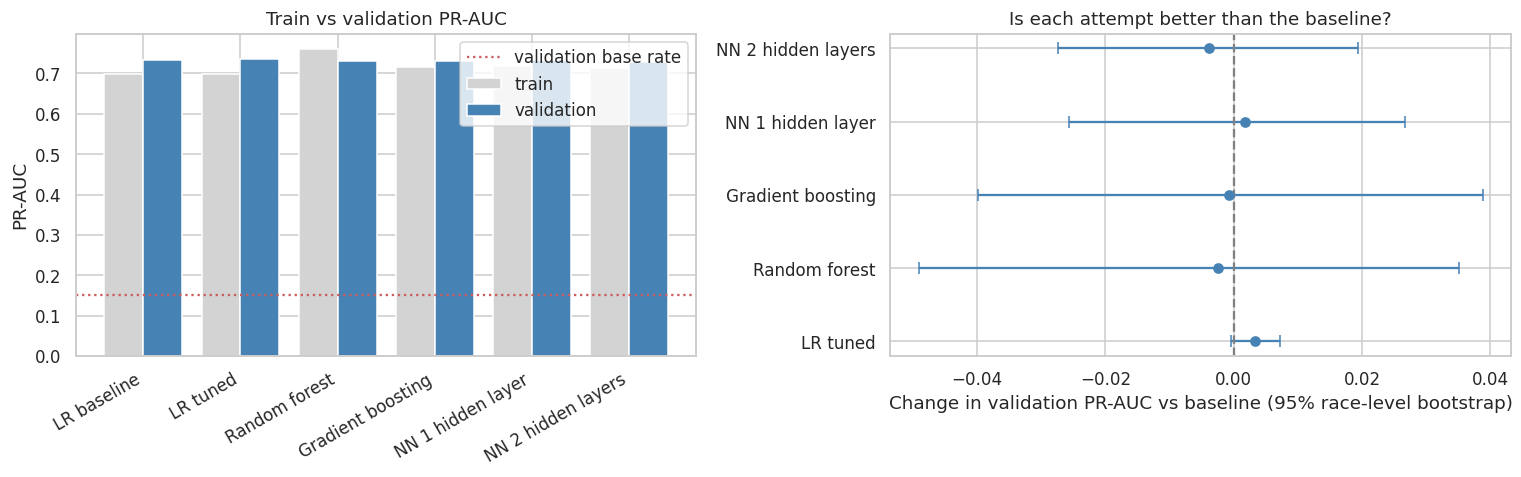

In [343]:
ALL = [BASE, "LR tuned", "Random forest", "Gradient boosting", "NN 1 hidden layer", "NN 2 hidden layers"]
val_tbl = val_summary(ALL)
display(val_tbl)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
x = np.arange(len(ALL))
axes[0].bar(x - 0.2, val_tbl.train_pr_auc, 0.4, label="train", color="lightgray")
axes[0].bar(x + 0.2, val_tbl.val_pr_auc, 0.4, label="validation", color="steelblue")
axes[0].axhline(y_val.mean(), color="indianred", ls=":", label="validation base rate")
axes[0].set_xticks(x); axes[0].set_xticklabels(ALL, rotation=30, ha="right")
axes[0].set_ylabel("PR-AUC"); axes[0].set_title("Train vs validation PR-AUC"); axes[0].legend()

d = val_tbl.drop(index=BASE)
y_ = np.arange(len(d))
axes[1].errorbar(d.d_pr_vs_baseline, y_, xerr=[d.d_pr_vs_baseline - d.ci_low, d.ci_high - d.d_pr_vs_baseline],
                 fmt="o", color="steelblue", capsize=4)
axes[1].axvline(0, color="gray", ls="--")
axes[1].set_yticks(y_); axes[1].set_yticklabels(d.index)
axes[1].set_xlabel("Change in validation PR-AUC vs baseline (95% race-level bootstrap)")
axes[1].set_title("Is each attempt better than the baseline?")
plt.tight_layout(); save_fig("s8_validation_comparison"); plt.show()

In [344]:
def best_of(names):
    return max(names, key=lambda n: average_precision_score(y_val, VAL_P[n]))

BEST_STAT = best_of([BASE, "LR tuned", "Random forest", "Gradient boosting"])
BEST_NN = nn_best
FINAL_NAME = best_of(ALL)                                    # primary model for ablation, XAI and inference
SHOW3 = [best_of([BASE, "LR tuned"]), best_of(["Random forest", "Gradient boosting"]), BEST_NN]

print("Best statistical model:", BEST_STAT)
print("Best neural network:  ", BEST_NN)
print("Primary model (best validation PR-AUC):", FINAL_NAME)
print("Thresholds chosen on validation:", {n: round(THR[n], 3) for n in ALL})
FROZEN = True

Best statistical model: LR tuned
Best neural network:   NN 1 hidden layer
Primary model (best validation PR-AUC): LR tuned
Thresholds chosen on validation: {'LR baseline': 0.233, 'LR tuned': 0.238, 'Random forest': 0.314, 'Gradient boosting': 0.336, 'NN 1 hidden layer': 0.422, 'NN 2 hidden layers': 0.423}


In [345]:
assert FROZEN and not TEST_EVALUATED, "test set already scored: do not re-tune after looking at it"
for n in ALL:
    TEST_P[n] = FITTED[n].predict_proba(X_test)[:, 1]
REF_TEST = {n: f(te_df, X_test) for n, f in REF_PRED.items()}
REF_TRAIN = {n: f(tr_df, X_train) for n, f in REF_PRED.items()}
TEST_EVALUATED = True

rows = []
for n in ALL:
    for split, y, p, rids in [("train", y_train, TRAIN_P[n], rid_tr), ("val", y_val, VAL_P[n], rid_va),
                              ("test", y_test, TEST_P[n], rid_te)]:
        rows.append({"model": n, "family": FAMILY[n], "split": split, "threshold": THR[n], **metric_row(y, p, THR[n], rids)})
for n in REF_PRED:
    for split, y, p, rids in [("train", y_train, REF_TRAIN[n], rid_tr), ("val", y_val, REF_VAL[n], rid_va),
                              ("test", y_test, REF_TEST[n], rid_te)]:
        rows.append({"model": n, "family": "reference", "split": split, "threshold": REF_THR[n], **metric_row(y, p, REF_THR[n], rids)})
final_long = pd.DataFrame(rows)

cols = pd.MultiIndex.from_product([["roc_auc", "pr_auc", "f1"], ["train", "val", "test"]])
final_wide = (final_long.pivot(index="model", columns="split", values=["roc_auc", "pr_auc", "f1"])
              .reindex(columns=cols).reindex(ALL + list(REF_PRED)))
test_ci = pd.Series(["{:.3f} to {:.3f}".format(*np.percentile(pr_boot(y_test, TEST_P[n], BOOT_TEST), [2.5, 97.5]))
                     if n in ALL else "" for n in final_wide.index], index=final_wide.index, name="test PR-AUC 95% CI")
display(final_wide.round(3))
display(test_ci.to_frame())

print("Test base rate (random-ranking PR-AUC):", round(y_test.mean(), 3))
display(final_long[(final_long.split == "test")].set_index("model")[["threshold", "precision", "recall", "top3_prec"]].round(3))
final_long.to_csv(OUT / "model_comparison_long.csv", index=False)
flat_wide = final_wide.copy(); flat_wide.columns = [f"{a}_{b}" for a, b in flat_wide.columns]
flat_wide.join(test_ci).to_csv(OUT / "model_comparison_wide.csv")

roc_auc               pr_auc                   f1              
                       train    val   test  train    val   test  train    val   test
model                                                                               
LR baseline           0.9330 0.9320 0.9380 0.6990 0.7330 0.7080 0.6640 0.7100 0.6730
LR tuned              0.9330 0.9330 0.9380 0.6990 0.7360 0.7080 0.6670 0.7050 0.6830
Random forest         0.9520 0.9330 0.9400 0.7600 0.7300 0.7140 0.7060 0.7130 0.6770
Gradient boosting     0.9400 0.9340 0.9410 0.7150 0.7320 0.7110 0.6790 0.7230 0.6900
NN 1 hidden layer     0.9400 0.9280 0.9380 0.7180 0.7350 0.7160 0.6800 0.7020 0.6650
NN 2 hidden layers    0.9390 0.9270 0.9360 0.7130 0.7290 0.7010 0.6770 0.7020 0.6570
Ref: rule grid <= 3   0.9090 0.9100 0.9130 0.6280 0.6480 0.6470 0.6480 0.6950 0.6490
Ref: LR on grid only  0.9090 0.9100 0.9130 0.6280 0.6480 0.6470 0.6480 0.6950 0.6490

,test PR-AUC 95% CI
model,
LR baseline,0.645 to 0.777
LR tuned,0.646 to 0.777
Random forest,0.660 to 0.769
Gradient boosting,0.651 to 0.769
NN 1 hidden layer,0.659 to 0.775
NN 2 hidden layers,0.643 to 0.767
Ref: rule grid <= 3,
Ref: LR on grid only,


Test base rate (random-ranking PR-AUC): 0.151


,threshold,precision,recall,top3_prec
model,,,,
LR baseline,0.2330,0.5580,0.8480,0.6520
LR tuned,0.2380,0.5730,0.8430,0.6520
Random forest,0.3140,0.6170,0.7500,0.6570
Gradient boosting,0.3360,0.6490,0.7350,0.6570
NN 1 hidden layer,0.4220,0.6590,0.6720,0.6420
NN 2 hidden layers,0.4230,0.6620,0.6520,0.6420
Ref: rule grid <= 3,0.2500,0.6500,0.6470,0.6520
Ref: LR on grid only,0.4760,0.6500,0.6470,0.6520


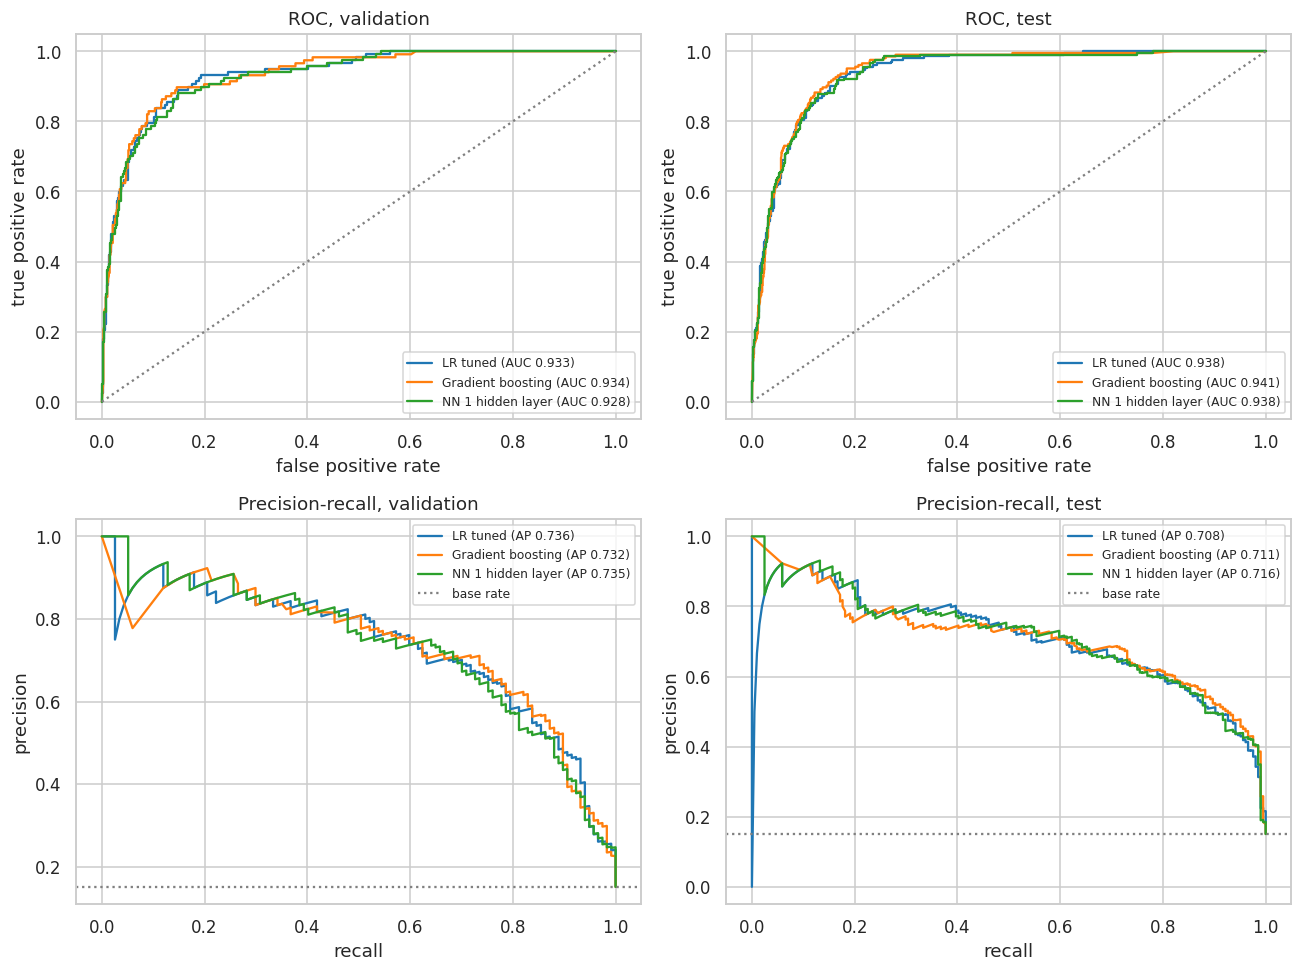

In [346]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
cols_ = sns.color_palette("tab10", len(SHOW3))
for j, (split, y, P) in enumerate([("validation", y_val, VAL_P), ("test", y_test, TEST_P)]):
    for n, c in zip(SHOW3, cols_):
        fpr, tpr, _ = roc_curve(y, P[n]); pr, rc, _ = precision_recall_curve(y, P[n])
        axes[0, j].plot(fpr, tpr, color=c, label=f"{n} (AUC {roc_auc_score(y, P[n]):.3f})")
        axes[1, j].plot(rc, pr, color=c, label=f"{n} (AP {average_precision_score(y, P[n]):.3f})")
    axes[0, j].plot([0, 1], [0, 1], color="gray", ls=":")
    axes[1, j].axhline(y.mean(), color="gray", ls=":", label="base rate")
    axes[0, j].set_title(f"ROC, {split}"); axes[0, j].set_xlabel("false positive rate"); axes[0, j].set_ylabel("true positive rate")
    axes[1, j].set_title(f"Precision-recall, {split}"); axes[1, j].set_xlabel("recall"); axes[1, j].set_ylabel("precision")
    axes[0, j].legend(fontsize=8, loc="lower right"); axes[1, j].legend(fontsize=8, loc="upper right")
plt.tight_layout(); save_fig("s8_roc_pr_curves"); plt.show()

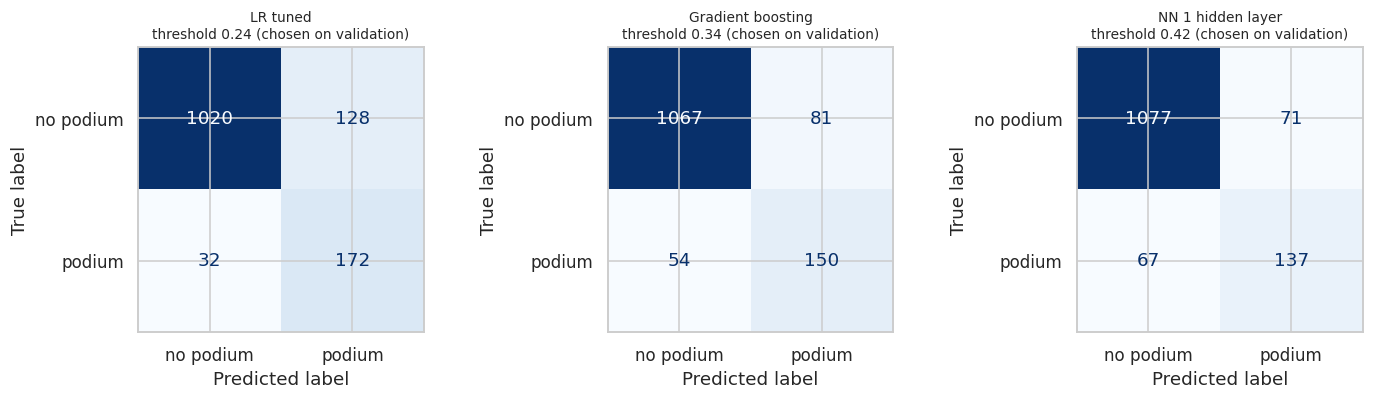

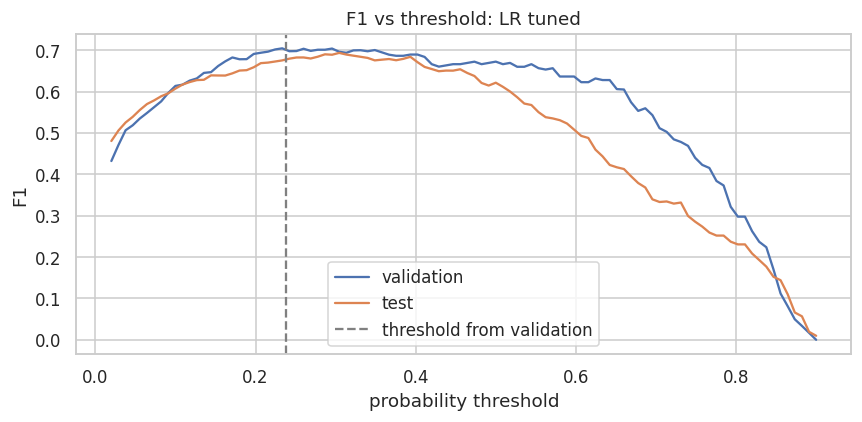

In [347]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, n in zip(axes, SHOW3):
    ConfusionMatrixDisplay.from_predictions(y_test, TEST_P[n] >= THR[n], ax=ax, colorbar=False, cmap="Blues",
                                            display_labels=["no podium", "podium"])
    ax.set_title(f"{n}\nthreshold {THR[n]:.2f} (chosen on validation)", fontsize=9)
plt.tight_layout(); save_fig("s8_confusion_test"); plt.show()

ths = np.linspace(0.02, 0.9, 100)
fig, ax = plt.subplots(figsize=(8, 4))
for split, y, p in [("validation", y_val, VAL_P[FINAL_NAME]), ("test", y_test, TEST_P[FINAL_NAME])]:
    ax.plot(ths, [f1_score(y, p >= t) for t in ths], label=split)
ax.axvline(THR[FINAL_NAME], color="gray", ls="--", label="threshold from validation")
ax.set_xlabel("probability threshold"); ax.set_ylabel("F1")
ax.set_title(f"F1 vs threshold: {FINAL_NAME}"); ax.legend()
plt.tight_layout(); save_fig("s8_f1_vs_threshold"); plt.show()

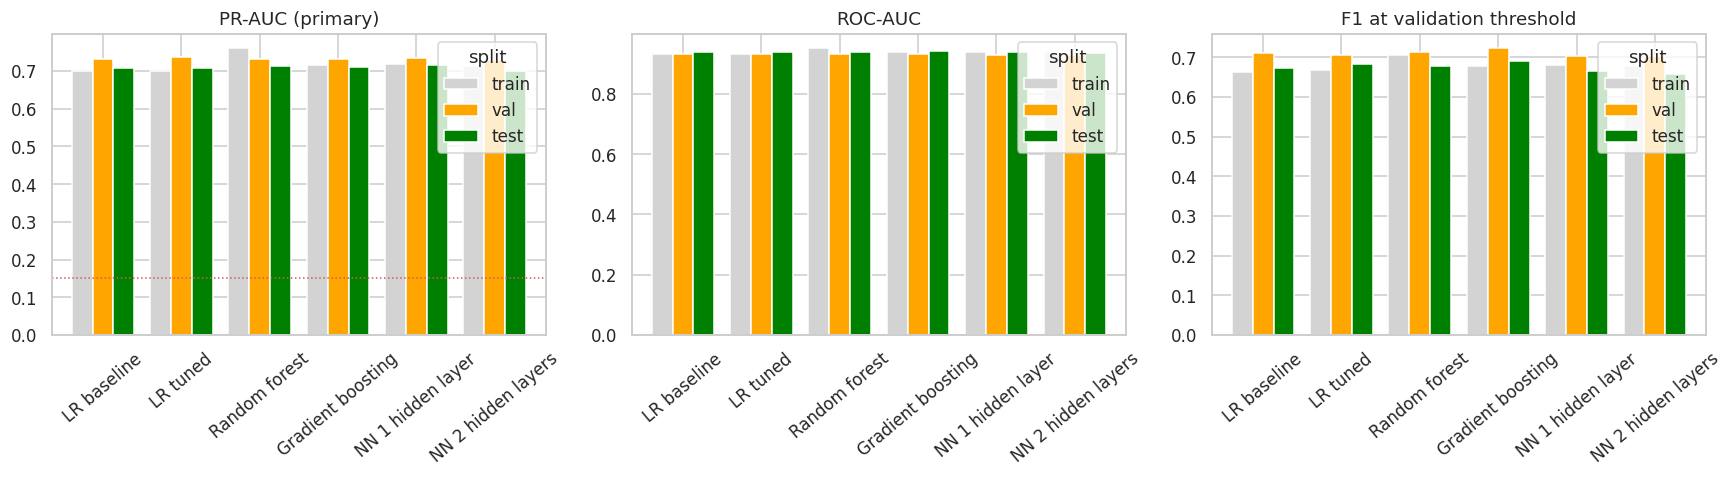

In [348]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=False)
for ax, met, lab_ in zip(axes, ["pr_auc", "roc_auc", "f1"], ["PR-AUC (primary)", "ROC-AUC", "F1 at validation threshold"]):
    t = final_long[final_long.model.isin(ALL)].pivot(index="model", columns="split", values=met).reindex(ALL)[["train", "val", "test"]]
    t.plot(kind="bar", ax=ax, color=["lightgray", "orange", "green"], width=0.8)
    ax.set_title(lab_); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=40)
    if met == "pr_auc":
        ax.axhline(y_test.mean(), color="indianred", ls=":", lw=1)
plt.tight_layout(); save_fig("s8_train_val_test_bars"); plt.show()

In [349]:
joblib.dump({n: FITTED[n] for n in ALL if FAMILY[n] == "statistical"}, OUT / "stat_models.joblib")
torch.save({"state": FITTED[BEST_NN].net.state_dict(), "params": BEST_PARAMS[BEST_NN],
            "d_in": X_train.shape[1], "columns": list(X_train.columns)}, OUT / "nn_best.pt")
pd.Series({**THR, **REF_THR}, name="threshold").to_csv(OUT / "thresholds.csv")
pd.Series({"best_stat": BEST_STAT, "best_nn": BEST_NN, "final": FINAL_NAME}).to_csv(OUT / "selected_models.csv")
print("Saved to", OUT)

Saved to /kaggle/working/clean


## Modeling findings
- **Baseline:** logistic regression reaches validation PR-AUC 0.733 and ROC-AUC 0.932 (base rate 0.151). The reference that uses only the start slot (`grid_eff`; the rule "grid <= 3" and a logistic regression on `grid_eff` give identical metrics) reaches 0.648 on validation and 0.647 on test, so the full feature set adds about 0.09 PR-AUC on validation and 0.06 on test (tuned LR: 0.736 and 0.708).
- **Attempts vs baseline (validation PR-AUC change, 95% CI):** tuned LR +0.0033 (-0.0004 to 0.0072), random forest -0.0025 (-0.0491 to 0.0352), gradient boosting -0.0007 (-0.0399 to 0.0388), NN 1 layer +0.0018 (-0.0257 to 0.0267), NN 2 layers -0.0038 (-0.0273 to 0.0194). All verdicts are "within noise", so no attempt beats the baseline and the added complexity is not earning its place.
- **Overfitting:** the train-minus-validation PR-AUC gap is largest for the random forest (+0.030; train ROC-AUC 0.952 vs 0.933). Logistic regression (-0.034, -0.037), gradient boosting (-0.017) and the networks (-0.017, -0.016) score higher on validation than on train, because the validation seasons have a higher base rate (15.1% vs 14.2%).
- **Neural network:** the best shallow network has one hidden layer of 32 units, dropout 0.3 and weight decay 1e-4; early stopping on validation loss selected epoch 56, and validation PR-AUC over 5 seeds is 0.726 +/- 0.010 (the selected run, 0.735, is optimistic). The two-layer network (32, 16, dropout 0.1) reaches 0.729 and stops at epoch 27. Neither beats the tuned logistic regression.
- **Selected primary model:** tuned logistic regression (C = 10, no class weights), the best validation PR-AUC (0.736) although only +0.0033 above the baseline. Primary metric is PR-AUC because podiums are rare (about 15% of rows) and it measures how well podium finishers are ranked above the rest without a threshold; ROC-AUC (0.933) is secondary; the F1 threshold (0.238) was chosen on validation.
- **Unseen test (2022-2024):** primary model PR-AUC 0.708 (95% CI 0.646 to 0.777), ROC-AUC 0.938, F1 0.683, precision 0.573, recall 0.843, top-3 precision 0.652. All six models score 0.701-0.716 PR-AUC on test with overlapping intervals, and the drop of 0.028 from validation is within the interval.
- **Limitations:** (1) validation is two seasons, so close models cannot be separated, and C = 10 sits at the edge of the tuning grid; (2) each driver is scored independently although exactly three drivers podium per race: the mean sum of predicted probabilities per test race is 2.80, and only 65% of each race's three highest-ranked drivers actually podium; (3) no pace information beyond qualifying gap and past form, and retirements, rain and safety cars are unpredictable; (4) forest probabilities are not calibrated, and thresholds differ between models (the networks' 0.42 gives recall 0.65-0.67 and the lowest test F1, 0.657-0.665).

# 9. Feature-Group Ablation

**Question:** how much does each feature group actually contribute after training?

**Method:** for each group, remove all its features, **refit the preprocessor and the model** (same hyperparameters, same rows, same split) and compare against the full model refit the same way. The loss in PR-AUC is the group's contribution.

**Extras**
- *Combined drops* (grid + qualifying, driver + constructor form): correlated groups can hide each other's value, so a single-group drop may look small when the information is simply duplicated elsewhere.
- *Only-this-group* models: the other direction, what each group can do alone.
- Two models: the primary model and the logistic-regression baseline, to check that conclusions do not depend on one model family.
- Neural networks are refit with 3 seeds and their probabilities averaged, to reduce seed noise.

**Evidence standard:** validation PR-AUC change with a 95% race-level paired bootstrap interval. Test results are shown for confirmation only. Nothing is selected on them.

**Why ablation and not just feature importance:** this step justifies each group by measured performance loss after retraining, while Section 10 explains how the trained model uses its inputs. The two can disagree, and a triangulation cell in Section 10 compares them.

In [350]:
ABL_MODELS = list(dict.fromkeys([FINAL_NAME, BASE]))
ABL_NN_SEEDS = 3
ABL_PRED, ABL_MET = {}, {}

def fit_predict_subset(model_name, feats):
    miss = [c for c in MISS_COLS if c in feats]
    prep = PodiumPrep(feats, miss, **PREP_CFG).fit(tr_df[feats])
    Xtr, Xva, Xte = (prep.transform(d[feats]) for d in (tr_df, va_df, te_df))
    prm = BEST_PARAMS[model_name]
    if FAMILY[model_name] == "neural":
        pv, pt = [], []
        for s in range(ABL_NN_SEEDS):
            m = TorchMLP(val=(Xva, y_val), seed=SEED + s, **prm).fit(Xtr, y_train)
            pv.append(m.predict_proba(Xva)[:, 1]); pt.append(m.predict_proba(Xte)[:, 1])
        return np.mean(pv, axis=0), np.mean(pt, axis=0), Xtr.shape[1]
    m = MAKERS[model_name](**prm).fit(Xtr, y_train)
    return m.predict_proba(Xva)[:, 1], m.predict_proba(Xte)[:, 1], Xtr.shape[1]

GROUPS = [g for g, fs in FEATURE_GROUPS.items() if fs]
SETS = {"full (refit)": list(FEATURES)}
for g in GROUPS:
    SETS[f"drop {g}"] = [f for f in FEATURES if f not in FEATURE_GROUPS[g]]
for combo in [("grid", "qualifying"), ("driver_form", "constructor_form")]:
    if all(g in GROUPS for g in combo):
        SETS["drop " + " + ".join(combo)] = [f for f in FEATURES if all(f not in FEATURE_GROUPS[g] for g in combo)]
for g in GROUPS:
    SETS[f"only {g}"] = list(FEATURE_GROUPS[g])

print({k: len(v) for k, v in SETS.items()})
assert all(len(v) > 0 for v in SETS.values()), "an ablation set is empty"

{'full (refit)': 26, 'drop grid': 21, 'drop qualifying': 21, 'drop driver_form': 21, 'drop constructor_form': 22, 'drop standings': 22, 'drop context': 23, 'drop grid + qualifying': 16, 'drop driver_form + constructor_form': 17, 'only grid': 5, 'only qualifying': 5, 'only driver_form': 5, 'only constructor_form': 4, 'only standings': 4, 'only context': 3}


In [351]:
t0 = time.time()
for mname in ABL_MODELS:
    for label, feats in SETS.items():
        pv, pt, n_in = fit_predict_subset(mname, feats)
        thr = best_threshold(y_val, pv)[0]            # threshold from validation only
        ABL_PRED[(mname, label)] = (pv, pt)
        ABL_MET[(mname, label)] = {"n_features": len(feats), "n_inputs": n_in, "threshold": thr,
                                   "val": metric_row(y_val, pv, thr, rid_va),
                                   "test": metric_row(y_test, pt, thr, rid_te)}
    print(f"{mname}: {len(SETS)} refits done ({time.time() - t0:.0f}s)")

LR tuned: 15 refits done (4s)
LR baseline: 15 refits done (7s)


In [352]:
def ablation_table(mname):
    ref_v = pr_boot(y_val, ABL_PRED[(mname, "full (refit)")][0], BOOT_VAL)
    ref_t = pr_boot(y_test, ABL_PRED[(mname, "full (refit)")][1], BOOT_TEST)
    full = ABL_MET[(mname, "full (refit)")]
    rows = []
    for label in SETS:
        pv, pt = ABL_PRED[(mname, label)]
        mt_ = ABL_MET[(mname, label)]
        dv, dt = pr_boot(y_val, pv, BOOT_VAL) - ref_v, pr_boot(y_test, pt, BOOT_TEST) - ref_t
        v_lo, v_hi = np.percentile(dv, [2.5, 97.5]); t_lo, t_hi = np.percentile(dt, [2.5, 97.5])
        verdict = ("reference" if label == "full (refit)" else
                   "significant loss" if v_hi < 0 else "gain" if v_lo > 0 else "within noise")
        rows.append({"set": label, "features": mt_["n_features"],
                     "val_roc": mt_["val"]["roc_auc"], "val_pr": mt_["val"]["pr_auc"], "val_f1": mt_["val"]["f1"],
                     "test_roc": mt_["test"]["roc_auc"], "test_pr": mt_["test"]["pr_auc"], "test_f1": mt_["test"]["f1"],
                     "d_val_pr": mt_["val"]["pr_auc"] - full["val"]["pr_auc"], "val_ci_low": v_lo, "val_ci_high": v_hi,
                     "d_test_pr": mt_["test"]["pr_auc"] - full["test"]["pr_auc"], "test_ci_low": t_lo, "test_ci_high": t_hi,
                     "verdict_val": verdict})
    return pd.DataFrame(rows).set_index("set")

ABL_TAB = {m: ablation_table(m) for m in ABL_MODELS}
for m in ABL_MODELS:
    print(f"\n=== {m} (validation base rate {y_val.mean():.3f}, test base rate {y_test.mean():.3f}) ===")
    display(ABL_TAB[m].round(4))
    ABL_TAB[m].to_csv(OUT / f"ablation_{m.replace(' ', '_')}.csv")


=== LR tuned (validation base rate 0.151, test base rate 0.151) ===


,features,val_roc,val_pr,val_f1,test_roc,test_pr,test_f1,d_val_pr,val_ci_low,val_ci_high,d_test_pr,test_ci_low,test_ci_high,verdict_val
set,,,,,,,,,,,,,,
full (refit),26,0.9327,0.7360,0.7054,0.9381,0.7079,0.6825,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,reference
drop grid,21,0.9326,0.7316,0.7143,0.9358,0.7099,0.6826,-0.0044,-0.0144,0.0056,0.0020,-0.0071,0.0096,within noise
drop qualifying,21,0.9272,0.7208,0.6971,0.9381,0.7021,0.6681,-0.0152,-0.0334,0.0015,-0.0058,-0.0133,0.0022,within noise
drop driver_form,21,0.9319,0.7184,0.7160,0.9388,0.7141,0.6734,-0.0176,-0.0304,-0.0017,0.0062,-0.0127,0.0239,significant loss
drop constructor_form,22,0.9334,0.7387,0.7120,0.9386,0.7058,0.6789,0.0027,-0.0029,0.0085,-0.0020,-0.0075,0.0027,within noise
drop standings,22,0.9314,0.7294,0.7059,0.9384,0.7121,0.6812,-0.0066,-0.0178,0.0031,0.0042,-0.0006,0.0093,within noise
drop context,23,0.9327,0.7386,0.7126,0.9384,0.7065,0.6880,0.0026,-0.0019,0.0078,-0.0014,-0.0067,0.0032,within noise
drop grid + qualifying,16,0.8971,0.6379,0.6803,0.8974,0.5791,0.5842,-0.0981,-0.1513,-0.0525,-0.1288,-0.1755,-0.0787,significant loss
drop driver_form + constructor_form,17,0.9315,0.7332,0.7073,0.9374,0.7028,0.6757,-0.0028,-0.0248,0.0170,-0.0051,-0.0271,0.0140,within noise



=== LR baseline (validation base rate 0.151, test base rate 0.151) ===


,features,val_roc,val_pr,val_f1,test_roc,test_pr,test_f1,d_val_pr,val_ci_low,val_ci_high,d_test_pr,test_ci_low,test_ci_high,verdict_val
set,,,,,,,,,,,,,,
full (refit),26,0.9316,0.7327,0.7104,0.9383,0.7078,0.6732,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,reference
drop grid,21,0.9316,0.7294,0.7143,0.9355,0.7090,0.6798,-0.0033,-0.0146,0.0076,0.0011,-0.0088,0.0091,within noise
drop qualifying,21,0.9270,0.7193,0.6947,0.9385,0.7041,0.6692,-0.0134,-0.0288,0.0012,-0.0037,-0.0101,0.0032,within noise
drop driver_form,21,0.9307,0.7159,0.7099,0.9387,0.7133,0.6706,-0.0168,-0.0296,-0.0015,0.0055,-0.0139,0.0219,significant loss
drop constructor_form,22,0.9322,0.7364,0.7120,0.9386,0.7057,0.6845,0.0037,-0.0033,0.0105,-0.0021,-0.0074,0.0027,within noise
drop standings,22,0.9306,0.7296,0.7082,0.9385,0.7118,0.6719,-0.0031,-0.0103,0.0061,0.0040,-0.0008,0.0091,within noise
drop context,23,0.9316,0.7346,0.7073,0.9385,0.7067,0.6851,0.0018,-0.0033,0.0082,-0.0012,-0.0062,0.0031,within noise
drop grid + qualifying,16,0.8974,0.6381,0.6803,0.8977,0.5790,0.5855,-0.0946,-0.1440,-0.0516,-0.1288,-0.1748,-0.0805,significant loss
drop driver_form + constructor_form,17,0.9298,0.7263,0.7045,0.9377,0.7064,0.6707,-0.0064,-0.0290,0.0132,-0.0014,-0.0246,0.0171,within noise


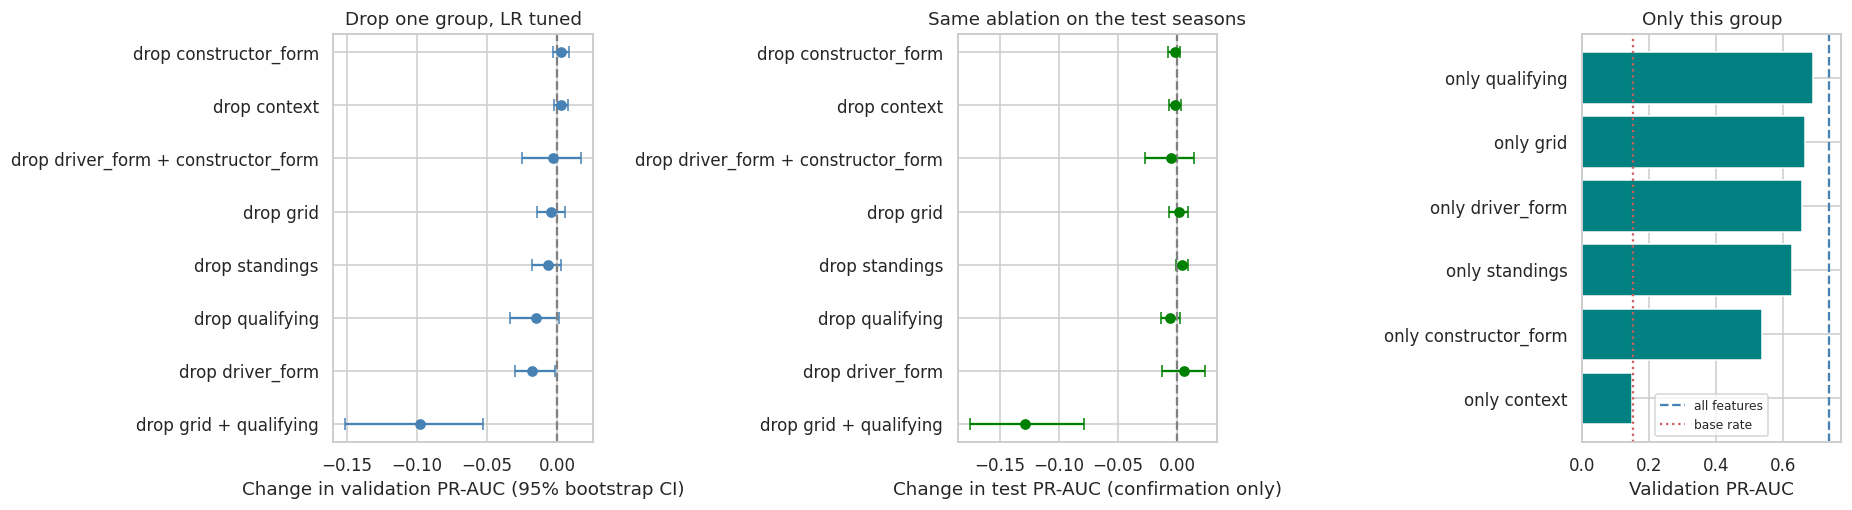

Rank agreement of group drops, LR tuned vs LR baseline: Spearman = 0.90


In [353]:
m = FINAL_NAME
t = ABL_TAB[m]
drops = t[t.index.str.startswith("drop ")].sort_values("d_val_pr")
only = t[t.index.str.startswith("only ")].sort_values("val_pr")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
y_ = np.arange(len(drops))
axes[0].errorbar(drops.d_val_pr, y_, xerr=[drops.d_val_pr - drops.val_ci_low, drops.val_ci_high - drops.d_val_pr],
                 fmt="o", color="steelblue", capsize=4)
axes[0].axvline(0, color="gray", ls="--")
axes[0].set_yticks(y_); axes[0].set_yticklabels(drops.index)
axes[0].set_xlabel("Change in validation PR-AUC (95% bootstrap CI)")
axes[0].set_title(f"Drop one group, {m}")

axes[1].errorbar(drops.d_test_pr, y_, xerr=[drops.d_test_pr - drops.test_ci_low, drops.test_ci_high - drops.d_test_pr],
                 fmt="o", color="green", capsize=4)
axes[1].axvline(0, color="gray", ls="--")
axes[1].set_yticks(y_); axes[1].set_yticklabels(drops.index)
axes[1].set_xlabel("Change in test PR-AUC (confirmation only)")
axes[1].set_title("Same ablation on the test seasons")

axes[2].barh(only.index, only.val_pr, color="teal")
axes[2].axvline(t.loc["full (refit)", "val_pr"], color="steelblue", ls="--", label="all features")
axes[2].axvline(y_val.mean(), color="indianred", ls=":", label="base rate")
axes[2].set_xlabel("Validation PR-AUC"); axes[2].set_title("Only this group"); axes[2].legend(fontsize=8)
plt.tight_layout(); save_fig("s9_ablation"); plt.show()

# Does the conclusion depend on the model family?
if len(ABL_MODELS) > 1:
    a, b = (ABL_TAB[k].loc[drops.index, "d_val_pr"] for k in ABL_MODELS)
    print(f"Rank agreement of group drops, {ABL_MODELS[0]} vs {ABL_MODELS[1]}: Spearman = {a.rank().corr(b.rank()):.2f}")

## Ablation findings
- **Full model (refit):** validation PR-AUC 0.736 (test 0.708) with 26 features.
- **Largest loss when removed:** driver form (-0.0176, CI -0.0304 to -0.0017), the only "significant loss" among single groups on validation. It is not stable across eras: on the test seasons dropping driver form gains +0.0062 (-0.0127 to 0.0239). Dropping qualifying costs -0.0152 (CI -0.0334 to 0.0015, within noise) on validation and -0.0058 on test.
- **Smallest or negative:** removing the grid group (-0.0044), standings (-0.0066), constructor form (+0.0027) or context (+0.0026) is within noise. A group with no loss is either uninformative or redundant: constructor form overlaps with standings and `team_best_grid`, and context (`home_race`, `circ_move_hist`, `round`) carries no signal at all (alone: ROC-AUC 0.49, PR-AUC 0.148 against a base rate of 0.151).
- **Redundancy check:** dropping grid alone costs -0.0044 and qualifying alone -0.0152, but dropping both costs -0.0981 (CI -0.1513 to -0.0525; -0.1288 on test, CI -0.1755 to -0.0787), so the two groups carry overlapping pace information. Dropping driver form and constructor form together costs only -0.0028 (within noise).
- **Only-this-group (validation PR-AUC):** qualifying 0.687, grid 0.663, driver form 0.655, standings 0.626, constructor form 0.537, context 0.148, against 0.736 for all features. The groups are complementary; qualifying and the start information carry most of the pace signal.
- **Consistency:** the ordering is similar for the logistic baseline (Spearman 0.90 across group drops), although both models are logistic regressions, so this is weak independent evidence. On the test seasons only dropping grid + qualifying clearly hurts; every single-group drop is within noise.
- **Caveat:** two validation seasons give wide intervals, so small drops cannot be distinguished from noise. "Within noise" means the data cannot tell, not that the group is useless.

# 10. Model Explainability (XAI)

**Model explained:** the primary model selected in Section 8 (`FINAL_NAME`).

| Level | Method | Question answered |
|---|---|---|
| Global | permutation importance | how much does performance drop if a feature is shuffled? |
| Global | SHAP | how much does each feature move the predicted probability, and in which direction? |
| Local | SHAP waterfall | why did the model give *this* probability to *this* driver in *this* race? |
| Local | LIME | a second, independent local explanation of the same rows |

> ### These explanations are not causal effects
> A feature being important to the model means the model **relies on it to make predictions**. It is not evidence that the feature **causes** podium finishes.
> - Many features are proxies for the same thing, mainly car pace: grid, qualifying gap, constructor form and standings all move together.
> - The explanations describe this model, trained on this data. Another model with the same accuracy could rely on different features.
> - Shuffling or masking features (permutation importance, SHAP, LIME) creates combinations that never occur in real races, so correlated features can split or hide importance.
> - Penalties, mechanical failures, safety cars and strategy are not in the features, so their effects are absorbed by the features that are.
>
> Statements below are therefore phrased as "the model relies on ...", never "X causes ...".

**Data used:** permutation importance on validation and test (the model is frozen, so nothing is tuned on them); SHAP global on a random sample of validation rows; local explanations on selected **test** rows.

In [354]:
import sys, subprocess, importlib

def ensure(pkg, mod=None):
    try:
        return importlib.import_module(mod or pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
        return importlib.import_module(mod or pkg)

shap = ensure("shap")
ensure("lime")
from lime.lime_tabular import LimeTabularExplainer

model = FITTED[FINAL_NAME]
COLS = list(X_train.columns)
base_feat = lambda c: c[:-4] if c.endswith("__na") else c
col_group = {c: F2G.get(base_feat(c), "other") for c in COLS}

def predict_cols(A):                       # preprocessed matrix -> P(podium)
    return model.predict_proba(pd.DataFrame(np.asarray(A, dtype=float), columns=COLS))[:, 1]

def predict_raw(df_raw):                   # raw features -> preprocess -> P(podium)
    return model.predict_proba(prep_final.transform(df_raw[FEATURES]))[:, 1]

assert np.allclose(predict_raw(va_df), VAL_P[FINAL_NAME], atol=1e-6), "wrapper disagrees with Section 8"
print(f"Explaining: {FINAL_NAME} | model inputs: {len(COLS)} ({len(FEATURES)} features + indicators) | shap {shap.__version__}")

Explaining: LR tuned | model inputs: 42 (26 features + indicators) | shap 0.52.0


In [355]:
PI_REPEATS = 10

def perm_importance(df_raw, y, units, repeats=PI_REPEATS, seed=SEED):
    df = df_raw[FEATURES].reset_index(drop=True)
    rng = np.random.default_rng(seed)
    p0 = predict_raw(df)
    base_pr, base_roc = average_precision_score(y, p0), roc_auc_score(y, p0)
    rows = []
    for name, cols in units.items():
        dpr, droc = [], []
        for _ in range(repeats):
            d = df.copy()
            d[cols] = df[cols].values[rng.permutation(len(df))]     # a group is shuffled jointly
            p = predict_raw(d)
            dpr.append(base_pr - average_precision_score(y, p)); droc.append(base_roc - roc_auc_score(y, p))
        rows.append({"unit": name, "pr_drop": np.mean(dpr), "pr_std": np.std(dpr), "roc_drop": np.mean(droc)})
    return pd.DataFrame(rows).set_index("unit").sort_values("pr_drop", ascending=False)

FEAT_UNITS = {f: [f] for f in FEATURES}
GROUP_UNITS = {g: FEATURE_GROUPS[g] for g in GROUPS}

PI = {}
for split, d, y in [("val", va_df, y_val), ("test", te_df, y_test)]:
    PI[("feat", split)] = perm_importance(d, y, FEAT_UNITS)
    PI[("group", split)] = perm_importance(d, y, GROUP_UNITS)

print("Top 12 features by permutation importance (validation, drop in PR-AUC):")
display(pd.concat([PI[("feat", "val")].add_suffix("_val"), PI[("feat", "test")].add_suffix("_test")], axis=1)
          .sort_values("pr_drop_val", ascending=False).head(12).round(4))
print("Groups:")
display(pd.concat([PI[("group", "val")].add_suffix("_val"), PI[("group", "test")].add_suffix("_test")], axis=1).round(4))

Top 12 features by permutation importance (validation, drop in PR-AUC):


,pr_drop_val,pr_std_val,roc_drop_val,pr_drop_test,pr_std_test,roc_drop_test
unit,,,,,,
quali_pos,0.1835,0.0310,0.0771,0.2043,0.0350,0.0813
team_best_grid,0.0397,0.0157,0.0165,0.0676,0.0137,0.0215
con_pos5,0.0231,0.0132,0.0047,0.0305,0.0170,0.0069
drv_pod_career,0.0184,0.0101,0.0026,0.0073,0.0047,0.0018
con_pod5,0.0168,0.0064,0.0025,0.0076,0.0043,0.0019
qgap_pct,0.0153,0.0127,0.0049,0.0108,0.0102,0.0007
c_pos_bef,0.0152,0.0090,0.0042,0.0164,0.0033,0.0035
con_pod_season,0.0141,0.0170,0.0022,0.0136,0.0113,0.0039
drv_dnf5,0.0120,0.0115,0.0023,-0.0000,0.0049,0.0013


Groups:


,pr_drop_val,pr_std_val,roc_drop_val,pr_drop_test,pr_std_test,roc_drop_test
unit,,,,,,
qualifying,0.1906,0.0334,0.0843,0.2223,0.0335,0.0920
driver_form,0.0960,0.0341,0.0163,0.0736,0.0263,0.0165
grid,0.0504,0.0229,0.0184,0.0652,0.0123,0.0208
standings,0.0286,0.0094,0.0048,0.0283,0.0127,0.0056
constructor_form,0.0214,0.0228,0.0039,0.0207,0.0145,0.0059
context,-0.0031,0.0022,-0.0003,-0.0006,0.0035,-0.0001


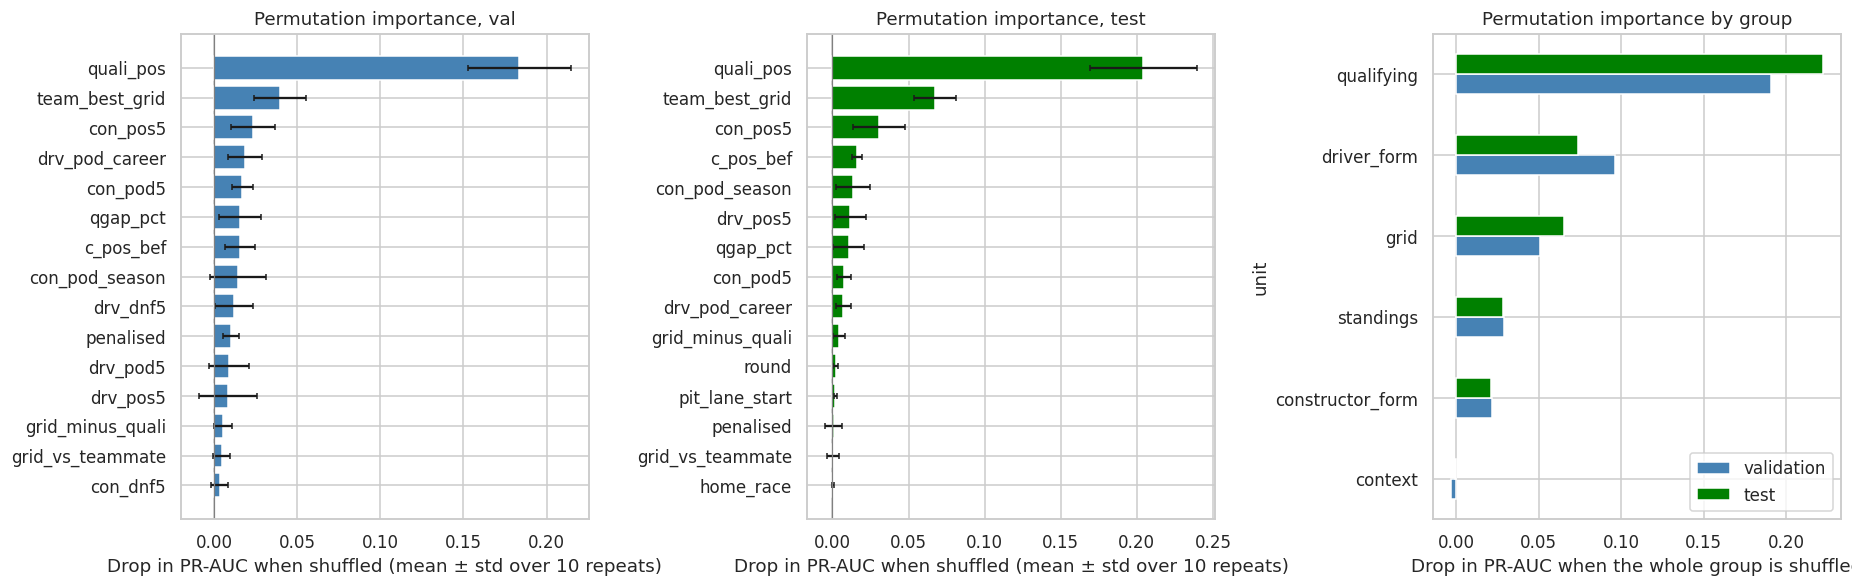

In [356]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))
for ax, split, col in [(axes[0], "val", "steelblue"), (axes[1], "test", "green")]:
    t = PI[("feat", split)].head(15).iloc[::-1]
    ax.barh(t.index, t.pr_drop, xerr=t.pr_std, color=col, capsize=2)
    ax.axvline(0, color="gray", lw=0.8)
    ax.set_xlabel("Drop in PR-AUC when shuffled (mean ± std over 10 repeats)")
    ax.set_title(f"Permutation importance, {split}")
g = pd.DataFrame({"validation": PI[("group", "val")].pr_drop, "test": PI[("group", "test")].pr_drop}).sort_values("validation")
g.plot(kind="barh", ax=axes[2], color=["steelblue", "green"])
axes[2].set_xlabel("Drop in PR-AUC when the whole group is shuffled"); axes[2].set_title("Permutation importance by group")
plt.tight_layout(); save_fig("s10_permutation_importance"); plt.show()

In [357]:
N_EXPLAIN, N_BG, EVAL_MULT = 300, 50, 4          # raise N_EXPLAIN / EVAL_MULT for smoother values if runtime allows
rng = np.random.default_rng(SEED)
bg = X_train.values[rng.choice(len(X_train), N_BG, replace=False)]
ex_idx = rng.choice(len(X_val), min(N_EXPLAIN, len(X_val)), replace=False)

masker = shap.maskers.Independent(bg, max_samples=N_BG)
explainer = shap.Explainer(predict_cols, masker, algorithm="permutation", feature_names=COLS, seed=SEED)

t0 = time.time()
sv = explainer(X_val.values[ex_idx], max_evals=EVAL_MULT * len(COLS) + 1, silent=True)
print(f"SHAP computed for {len(ex_idx)} validation rows in {time.time() - t0:.0f}s")

# Additivity check: base value + sum of SHAP values should reproduce the predicted probability
pred = predict_cols(X_val.values[ex_idx])
print("Max additivity error:", float(np.abs(sv.base_values + sv.values.sum(1) - pred).max()))

# Display data: raw feature values (indicator columns keep their 0/1)
disp = X_val.iloc[ex_idx].copy()
for f in FEATURES:
    disp[f] = va_df.iloc[ex_idx][f].values
expl = shap.Explanation(values=sv.values, base_values=sv.base_values, data=disp.values, feature_names=COLS)

mabs = pd.Series(np.abs(sv.values).mean(0), index=COLS)
shap_feat = mabs.groupby(base_feat).sum().sort_values(ascending=False)
shap_group = mabs.groupby(col_group).sum().sort_values(ascending=False)
print(f"Average predicted probability in the sample: {pred.mean():.3f} (SHAP base value {sv.base_values.mean():.3f})")
display(shap_feat.head(12).round(4).to_frame("mean |SHAP| (probability points)"))

SHAP computed for 300 validation rows in 2s
Max additivity error: 1.1102230246251565e-15
Average predicted probability in the sample: 0.154 (SHAP base value 0.106)


,mean |SHAP| (probability points)
quali_pos,0.0667
team_best_grid,0.0382
con_pos5,0.0202
drv_pos5,0.0186
con_pod_season,0.0182
drv_pod5,0.0177
con_pod5,0.0162
drv_pod_career,0.0133
drv_dnf5,0.0113
c_pos_bef,0.0106


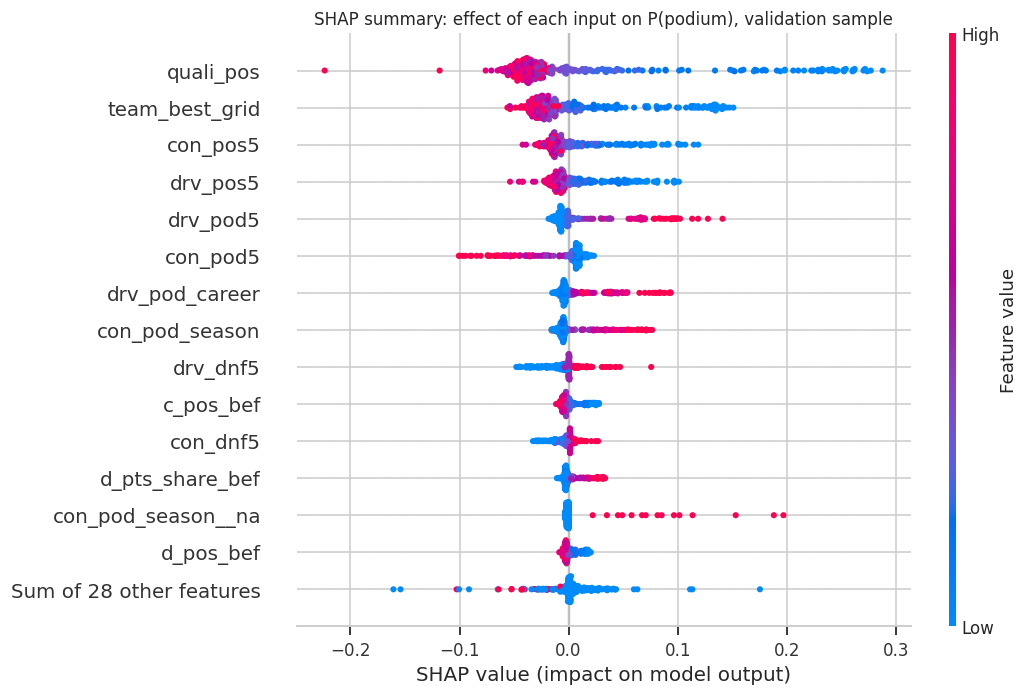

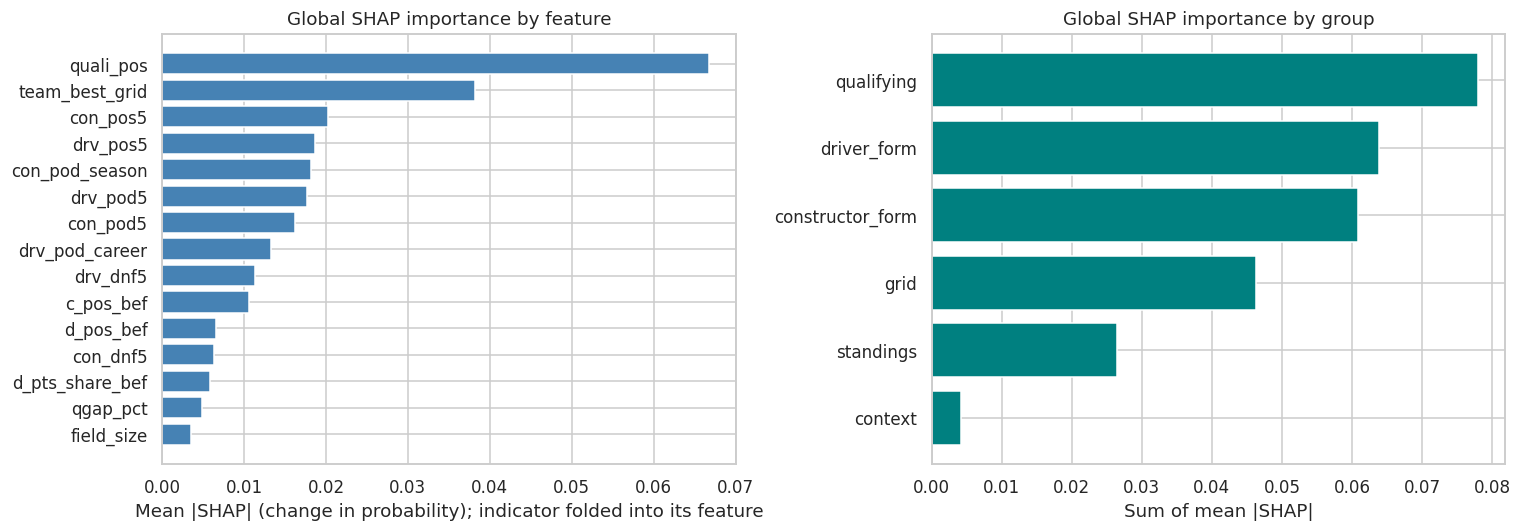

In [358]:
shap.plots.beeswarm(expl, max_display=15, show=False, plot_size=(9, 7))
plt.title("SHAP summary: effect of each input on P(podium), validation sample", fontsize=11)
save_fig("s10_shap_beeswarm"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
t = shap_feat.head(15).iloc[::-1]
axes[0].barh(t.index, t.values, color="steelblue")
axes[0].set_xlabel("Mean |SHAP| (change in probability); indicator folded into its feature")
axes[0].set_title("Global SHAP importance by feature")
sg = shap_group.iloc[::-1]
axes[1].barh(sg.index, sg.values, color="teal")
axes[1].set_xlabel("Sum of mean |SHAP|"); axes[1].set_title("Global SHAP importance by group")
plt.tight_layout(); save_fig("s10_shap_bars"); plt.show()

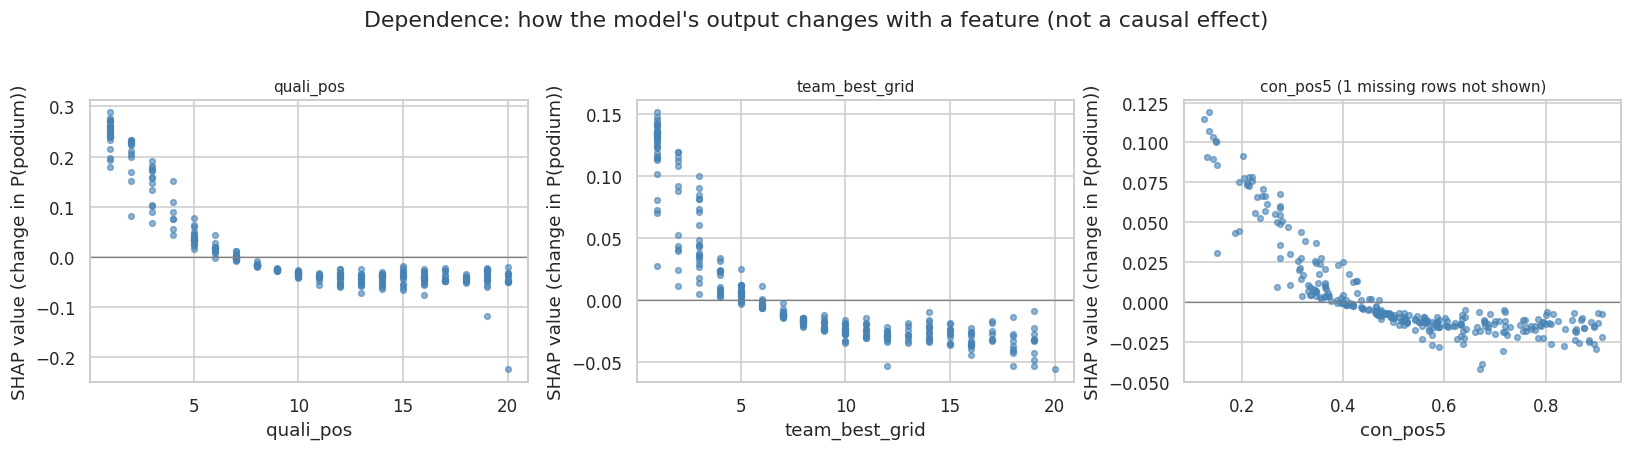

In [359]:
top3 = [f for f in shap_feat.index if f in FEATURES][:3]
raw_ex = va_df.iloc[ex_idx]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, f in zip(axes, top3):
    x, y = raw_ex[f].values.astype(float), sv.values[:, COLS.index(f)]
    ok = ~np.isnan(x)
    ax.scatter(x[ok], y[ok], s=14, alpha=0.6, color="steelblue")
    ax.axhline(0, color="gray", lw=0.8)
    ax.set_xlabel(f); ax.set_ylabel("SHAP value (change in P(podium))")
    ax.set_title(f"{f}" + (f" ({int((~ok).sum())} missing rows not shown)" if (~ok).any() else ""), fontsize=10)
plt.suptitle("Dependence: how the model's output changes with a feature (not a causal effect)", y=1.02)
plt.tight_layout(); save_fig("s10_shap_dependence"); plt.show()

Spearman rank correlation, permutation vs SHAP: 0.83 | overlap of top-8: 6/8
Top-8 by permutation only: ['c_pos_bef', 'qgap_pct'] | by SHAP only: ['drv_pod5', 'drv_pos5']


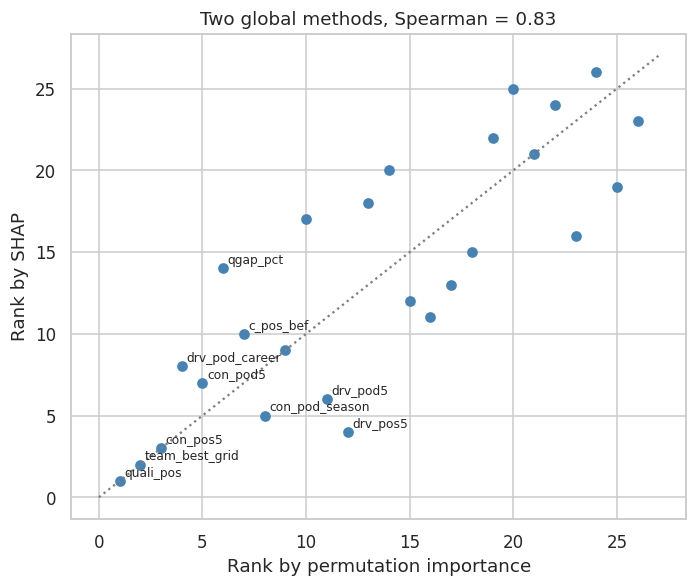

In [360]:
pi_feat = PI[("feat", "val")].pr_drop
agree = pd.DataFrame({"permutation": pi_feat, "shap": shap_feat.reindex(pi_feat.index).fillna(0)})
agree["rank_perm"] = agree.permutation.rank(ascending=False)
agree["rank_shap"] = agree.shap.rank(ascending=False)
rho = agree.rank_perm.corr(agree.rank_shap)
top_p, top_s = set(agree.nsmallest(8, "rank_perm").index), set(agree.nsmallest(8, "rank_shap").index)
print(f"Spearman rank correlation, permutation vs SHAP: {rho:.2f} | overlap of top-8: {len(top_p & top_s)}/8")
print("Top-8 by permutation only:", sorted(top_p - top_s), "| by SHAP only:", sorted(top_s - top_p))

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.scatter(agree.rank_perm, agree.rank_shap, color="steelblue")
for f, r in agree.iterrows():
    if min(r.rank_perm, r.rank_shap) <= 8:
        ax.annotate(f, (r.rank_perm, r.rank_shap), fontsize=8, xytext=(3, 3), textcoords="offset points")
lim = len(agree) + 1
ax.plot([0, lim], [0, lim], color="gray", ls=":")
ax.set_xlabel("Rank by permutation importance"); ax.set_ylabel("Rank by SHAP")
ax.set_title(f"Two global methods, Spearman = {rho:.2f}")
plt.tight_layout(); save_fig("s10_perm_vs_shap"); plt.show()

In [361]:
p_te, thr = TEST_P[FINAL_NAME], THR[FINAL_NAME]
info = (te_df[["raceId", "driverId", "year", GRID_COL]]
        .merge(base[["raceId", "driverId", "driver_name", "race_name", "positionOrder"]], on=["raceId", "driverId"], how="left"))
info.index = te_df.index
info["p_podium"], info["podium"] = p_te, y_test
info["rank_in_race"] = info.groupby("raceId").p_podium.rank(ascending=False, method="first")

picks = {
    "Correct podium call (highest-probability podium)": info[info.podium == 1].p_podium.idxmax(),
    "Surprise podium (lowest-probability podium finisher)": info[info.podium == 1].p_podium.idxmin(),
    "False alarm (highest-probability non-podium)": info[info.podium == 0].p_podium.idxmax(),
}
loc_idx = list(picks.values())
cols_show = ["driver_name", "race_name", "year", GRID_COL, "p_podium", "rank_in_race", "positionOrder", "podium"]
display(info.loc[loc_idx, cols_show].assign(case=list(picks)).set_index("case").round(3))
print(f"Decision threshold from validation: {thr:.3f}")

,driver_name,race_name,year,grid_eff,p_podium,rank_in_race,positionOrder,podium
case,,,,,,,,
Correct podium call (highest-probability podium),Max Verstappen,Saudi Arabian Grand Prix,2024,1.0000,0.9030,1.0000,1.0000,1
Surprise podium (lowest-probability podium finisher),Pierre Gasly,São Paulo Grand Prix,2024,13.0000,0.0030,13.0000,3.0000,1
False alarm (highest-probability non-podium),Max Verstappen,Australian Grand Prix,2024,1.0000,0.9040,1.0000,19.0000,0


Decision threshold from validation: 0.238


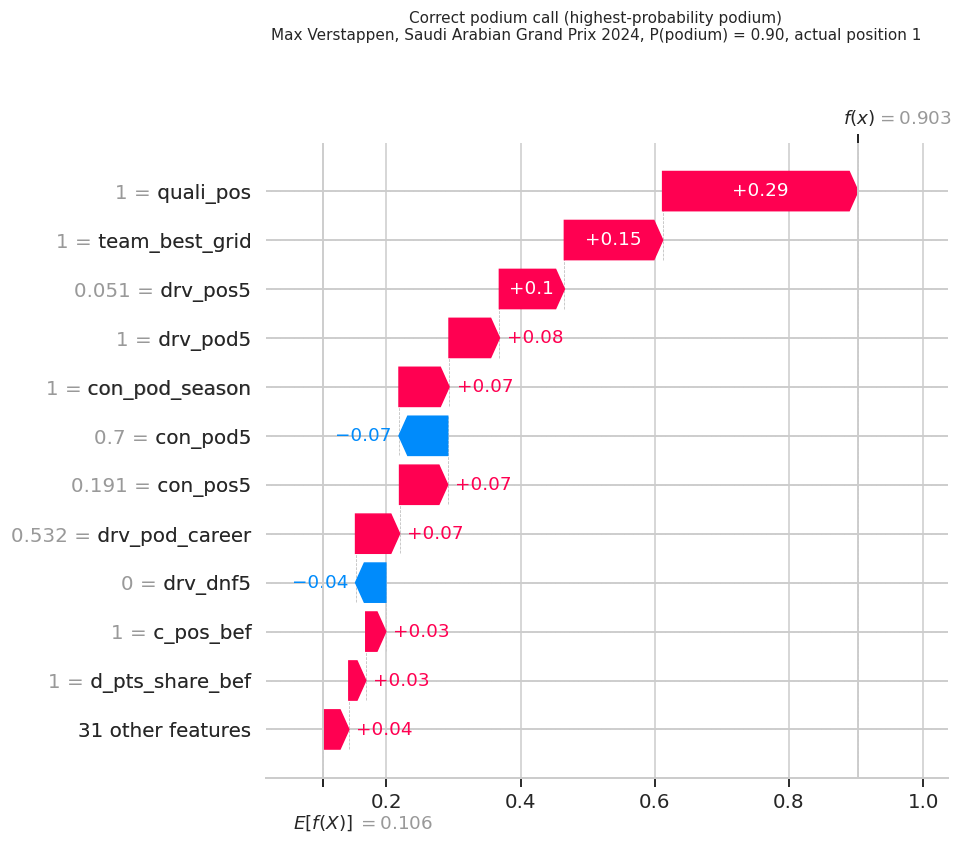

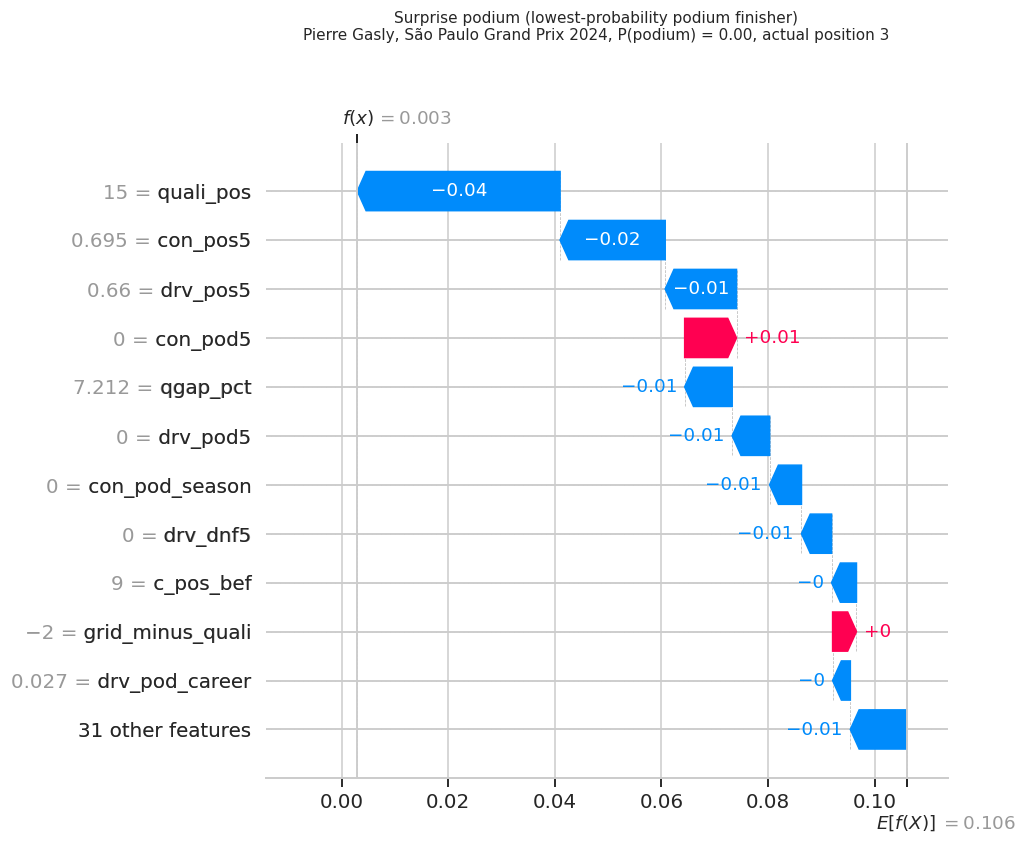

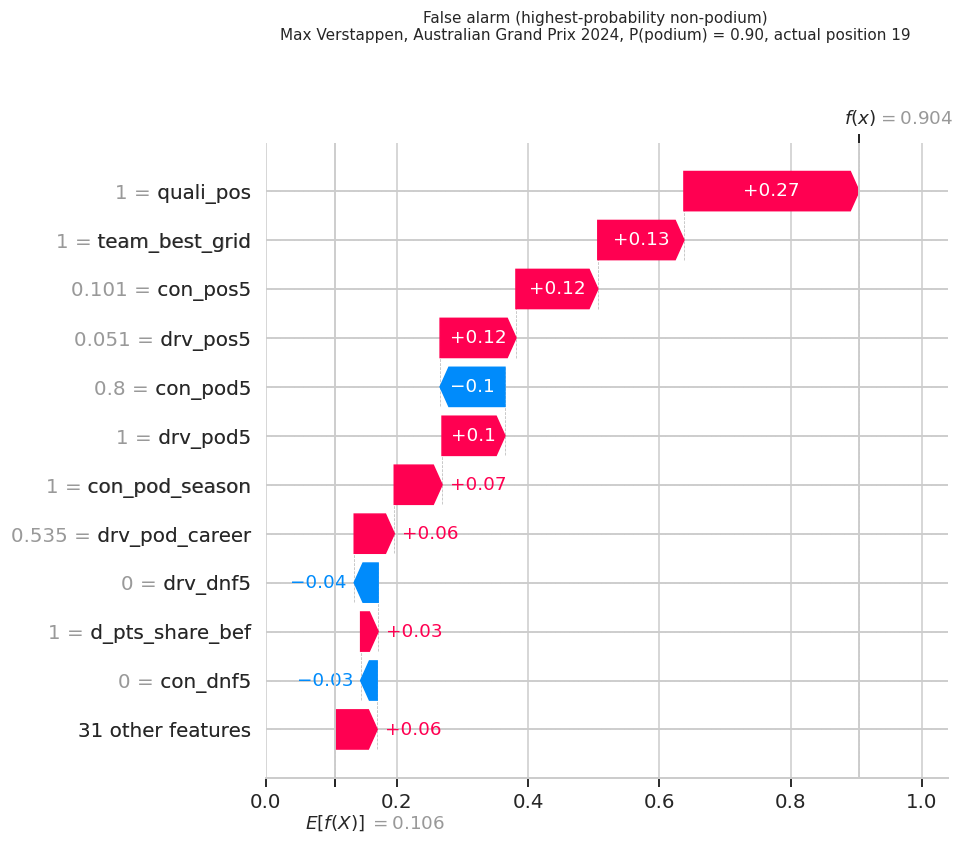

In [362]:
Xl = X_test.loc[loc_idx]
sv_l = explainer(Xl.values, max_evals=EVAL_MULT * len(COLS) + 1, silent=True)
disp_l = Xl.copy()
for f in FEATURES:
    disp_l[f] = te_df.loc[loc_idx, f].values
expl_l = shap.Explanation(values=sv_l.values, base_values=sv_l.base_values, data=disp_l.values, feature_names=COLS)

for i, (label, idx) in enumerate(picks.items()):
    shap.plots.waterfall(expl_l[i], max_display=12, show=False)
    r = info.loc[idx]
    plt.gcf().suptitle(f"{label}\n{r.driver_name}, {r.race_name} {int(r.year)}, "
                       f"P(podium) = {r.p_podium:.2f}, actual position {int(r.positionOrder)}", y=1.04, fontsize=10)
    save_fig(f"s10_shap_local_{i + 1}"); plt.show()

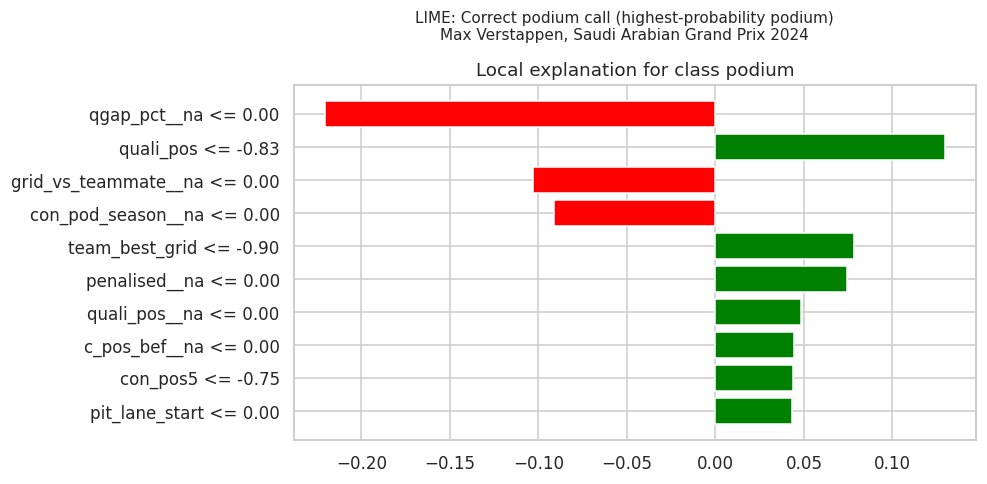

  Model P(podium) = 0.903 | LIME local surrogate prediction = 0.249 | surrogate R² = 0.50


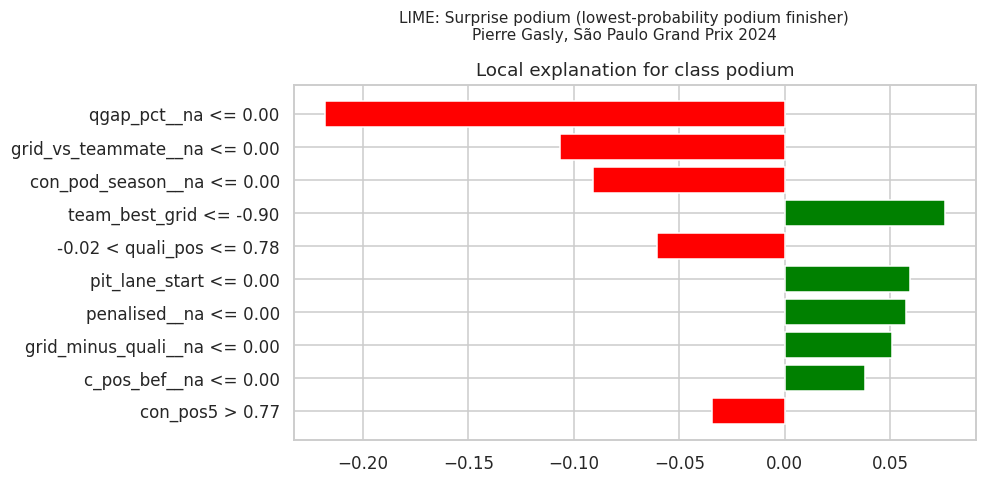

  Model P(podium) = 0.003 | LIME local surrogate prediction = 0.049 | surrogate R² = 0.28


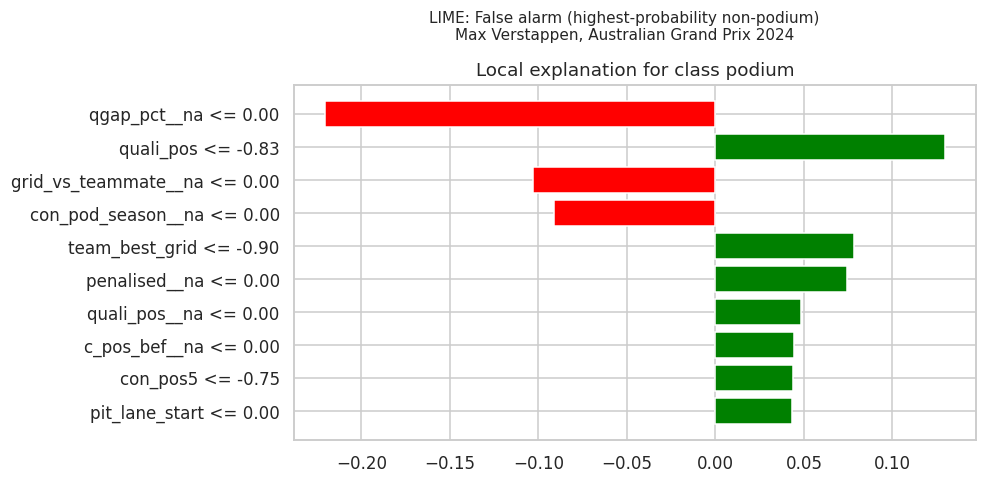

  Model P(podium) = 0.904 | LIME local surrogate prediction = 0.249 | surrogate R² = 0.50


In [363]:
def make_lime(seed=SEED):
    return LimeTabularExplainer(X_train.values, feature_names=COLS, class_names=["no podium", "podium"],
                                mode="classification", discretize_continuous=True, random_state=seed)

lime_fn = lambda A: model.predict_proba(pd.DataFrame(np.asarray(A, dtype=float), columns=COLS))

def lime_attr(e, name):
    """LIME versions differ: some store score/local_pred as a scalar, others as a dict keyed by label."""
    v = getattr(e, name)
    return v[1] if isinstance(v, dict) else v

LIME = {}
for i, (label, idx) in enumerate(picks.items()):
    e = make_lime().explain_instance(X_test.loc[idx].values, lime_fn, num_features=10, num_samples=5000)
    LIME[idx] = e
    r = info.loc[idx]
    fig = e.as_pyplot_figure(label=1)
    fig.set_size_inches(8, 4.2)
    fig.suptitle(f"LIME: {label}\n{r.driver_name}, {r.race_name} {int(r.year)}", y=1.04, fontsize=10)
    save_fig(f"s10_lime_local_{i + 1}"); plt.show()
    print(f"  Model P(podium) = {r.p_podium:.3f} | LIME local surrogate prediction = "
          f"{float(np.ravel(lime_attr(e, 'local_pred'))[0]):.3f} | surrogate R² = {float(lime_attr(e, 'score')):.2f}")

In [364]:
def top_cols(weights, k=5):
    return [c for c, _ in sorted(weights.items(), key=lambda kv: -abs(kv[1]))[:k]]

rows = []
for i, idx in enumerate(loc_idx):
    shap_w = dict(zip(COLS, sv_l.values[i]))
    lime_w = {COLS[j]: w for j, w in LIME[idx].as_map()[1]}
    s5, l5 = top_cols(shap_w), top_cols(lime_w)
    common = [c for c in s5 if c in l5]
    sign_ok = sum(np.sign(shap_w[c]) == np.sign(lime_w[c]) for c in common)
    rows.append({"case": list(picks)[i], "top5_overlap": len(common), "same_sign_in_overlap": f"{sign_ok}/{len(common)}",
                 "shap_top5": ", ".join(s5), "lime_top5": ", ".join(l5)})
display(pd.DataFrame(rows).set_index("case"))

# LIME depends on random sampling: how stable is its top-5 across seeds?
x0 = X_test.loc[loc_idx[0]].values
sets = [set(top_cols({COLS[j]: w for j, w in make_lime(s).explain_instance(x0, lime_fn, num_features=10, num_samples=5000)
                      .as_map()[1]})) for s in range(5)]
jac = [len(a & b) / len(a | b) for k, a in enumerate(sets) for b in sets[k + 1:]]
print(f"LIME top-5 stability over 5 seeds (mean Jaccard): {np.mean(jac):.2f}")

,top5_overlap,same_sign_in_overlap,shap_top5,lime_top5
case,,,,
Correct podium call (highest-probability podium),2,2/2,"quali_pos, team_best_grid, drv_pos5, drv_pod5,...","qgap_pct__na, quali_pos, grid_vs_teammate__na,..."
Surprise podium (lowest-probability podium finisher),1,1/1,"quali_pos, con_pos5, drv_pos5, con_pod5, qgap_pct","qgap_pct__na, grid_vs_teammate__na, con_pod_se..."
False alarm (highest-probability non-podium),2,2/2,"quali_pos, team_best_grid, con_pos5, drv_pos5,...","qgap_pct__na, quali_pos, grid_vs_teammate__na,..."


LIME top-5 stability over 5 seeds (mean Jaccard): 0.73


,ablation (retrained),permutation (frozen model),SHAP (mean |value|)
grid,0.0044,0.0504,0.0463
qualifying,0.0152,0.1906,0.0780
driver_form,0.0176,0.0960,0.0639
constructor_form,-0.0027,0.0214,0.0609
standings,0.0066,0.0286,0.0265
context,-0.0026,-0.0031,0.0041


,rank: ablation (retrained),rank: permutation (frozen model),rank: SHAP (mean |value|)
grid,4,3,4
qualifying,2,1,1
driver_form,1,2,2
constructor_form,6,5,3
standings,3,4,5
context,5,6,6


Spearman rank correlations between the three views:


,ablation (retrained),permutation (frozen model),SHAP (mean |value|)
ablation (retrained),1.0000,0.8300,0.5400
permutation (frozen model),0.8300,1.0000,0.8300
SHAP (mean |value|),0.5400,0.8300,1.0000


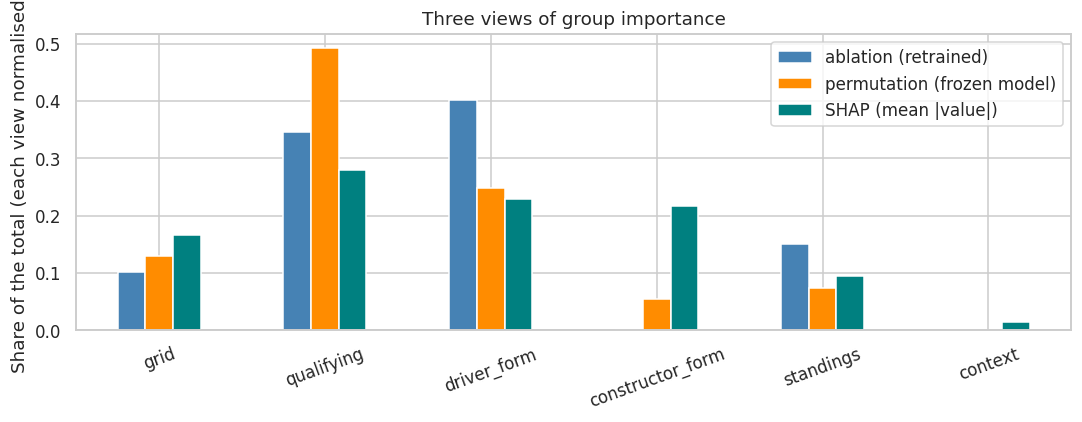

In [365]:
abl = -ABL_TAB[FINAL_NAME].loc[[f"drop {g}" for g in GROUPS], "d_val_pr"]
abl.index = GROUPS
tri = pd.DataFrame({"ablation (retrained)": abl,
                    "permutation (frozen model)": PI[("group", "val")].pr_drop.reindex(GROUPS),
                    "SHAP (mean |value|)": shap_group.reindex(GROUPS).fillna(0)})
display(tri.round(4))
display(tri.rank(ascending=False).astype(int).add_prefix("rank: "))
print("Spearman rank correlations between the three views:")
display(tri.corr(method="spearman").round(2))

norm = tri.clip(lower=0) / tri.clip(lower=0).sum()
norm.plot(kind="bar", figsize=(10, 4), color=["steelblue", "darkorange", "teal"])
plt.ylabel("Share of the total (each view normalised)"); plt.xlabel("")
plt.title("Three views of group importance")
plt.xticks(rotation=20); plt.tight_layout(); save_fig("s10_triangulation"); plt.show()

tri.to_csv(OUT / "xai_group_triangulation.csv")
PI[("feat", "val")].to_csv(OUT / "permutation_importance_val.csv")
shap_feat.to_csv(OUT / "shap_importance_feature.csv", header=["mean_abs_shap"])

## XAI findings
**Important: all statements describe what the model relies on, not what causes podiums.**

- **Global, permutation importance (validation, confirmed on test):** shuffling `quali_pos` lowers PR-AUC the most (0.184 on validation, 0.204 on test), followed by `team_best_grid` (0.040 / 0.068), `con_pos5` (0.023 / 0.031), `drv_pod_career` (0.018 / 0.007), `con_pod5` (0.017 / 0.008) and `qgap_pct` (0.015 / 0.011). By group: qualifying 0.191 > driver form 0.096 > grid 0.050 > standings 0.029 > constructor form 0.021 > context -0.003 (validation); the test order is the same.
- **Global, SHAP (300 validation rows, 50 background rows, additivity error 1e-15):** the output moves most with `quali_pos` (mean |SHAP| 0.067 probability points), then `team_best_grid` (0.038), `con_pos5` (0.020), `drv_pos5` (0.019), `con_pod_season` (0.018) and `drv_pod5` (0.018). Because the model is a logistic regression, each feature's effect on the log-odds is monotone; for `quali_pos` and `team_best_grid` better (lower) values push the predicted podium probability up, matching the univariate directions in Section 5.
- **Agreement:** permutation and SHAP rankings agree (Spearman 0.83, top-8 overlap 6 of 8). The differences are `c_pos_bef` and `qgap_pct` (ranked higher by permutation) versus `drv_pod5` and `drv_pos5` (higher by SHAP), which is what correlated features do: `c_pos_bef` overlaps with constructor form, `qgap_pct` with `quali_pos`, and the driver-form features with each other.
- **Triangulation:** the three views agree that qualifying and driver form are the two most relied-on groups (ablation ranks driver form first; permutation and SHAP rank qualifying first). They disagree about constructor form (ranked last by ablation, fifth by permutation and third by SHAP) and standings (third by ablation, fifth by SHAP). This is plausibly redundancy: the retrained model can replace constructor form with standings and `team_best_grid`, while the frozen model cannot. Spearman between views: ablation-permutation 0.83, ablation-SHAP 0.54, permutation-SHAP 0.83.
- **Local explanations (test seasons):**
  - *Correct call:* Max Verstappen, Saudi Arabian GP 2024, started on pole, P = 0.903 and finished first. The largest pushes were `quali_pos` and `team_best_grid`.
  - *Surprise podium:* Pierre Gasly, São Paulo GP 2024, qualified 15th and started 13th, P = 0.003 (13th highest in the race) and finished 3rd. Nothing in the pre-race features (grid, form, standings) hints at it; it was a race where conditions and strategy, not pre-race pace, decided the order.
  - *False alarm:* Max Verstappen, Australian GP 2024, started on pole, P = 0.904 and was classified 19th after an early mechanical retirement, which no pre-race feature can predict.
- **LIME vs SHAP:** the top-5 overlap is 2, 1 and 2 of 5 for the three cases (same sign on every shared feature). LIME's local surrogate is weak: it predicts 0.249 where the model says 0.903 (R-squared 0.50), 0.049 against 0.003 (R-squared 0.28) and 0.249 against 0.904 (0.50). LIME mostly highlights missing-value indicator columns (`qgap_pct__na`, `grid_vs_teammate__na`), because it perturbs binary indicators by sampling the training frequencies. Its top-5 is moderately stable across seeds (mean Jaccard 0.73). SHAP is therefore the primary local explanation and LIME a cross-check.
- **Limitations:** (1) correlated features share or hide importance (grid, qualifying gap, standings and constructor form describe the same pace); (2) permutation, SHAP and LIME all evaluate unrealistic feature combinations; (3) SHAP here uses 300 validation rows, 50 background rows and a sampling approximation; (4) importance depends on the era: the validation ranking differs from the test one for some features (for example `drv_pod_career`, `drv_dnf5`); (5) none of this is causal.

# 11. Inference Function

**Purpose:** given the pre-race information about one driver in one race, return the probability that the driver finishes on the podium.

**What it does**
1. Accepts a dict, Series, DataFrame or list of dicts (one record = one driver in one race).
2. **Rejects post-race fields** (points, status, laps, finishing position, ...) with an error, so the cutoff cannot be violated by accident.
3. Ignores identifier columns, warns about unknown fields, and turns unparseable values (including the dataset's `\N` sentinel) into missing values.
4. Warns about values outside the training range.
5. Applies the **frozen** preprocessor from Section 6 (medians, scalers and clipping learned on the training window only, plus missing-value indicators), so a partially-missing record still gets a prediction.
6. Returns the probability, a podium call at the **validation-chosen** threshold, and a data-quality summary (which inputs were missing, which feature groups were absent entirely).

**Demonstrations:** a complete record, a partially-missing record, edge cases, a whole race, and a stress test of how performance degrades as inputs go missing.

In [366]:
INF_MODEL_NAME = FINAL_NAME
INF_MODEL = FITTED[INF_MODEL_NAME]
INF_PREP = prep_final
INF_THR = THR[INF_MODEL_NAME]

IDENTIFIERS = {"raceId", "driverId", "constructorId", "circuitId", "year", "race_idx", "split"}
FORBIDDEN = set(LEAKY) | {"status", "statusText", "finish_position", "laps_completed", "fastest_lap"}
BIN_FEATS = [f for f in FEATURES if tr_df[f].nunique(dropna=True) <= 2]
TRAIN_RANGE = tr_df[FEATURES].agg(["min", "max"]).T

print(f"Model: {INF_MODEL_NAME} | decision threshold (from validation): {INF_THR:.3f}")
print(f"{len(FEATURES)} features | binary: {BIN_FEATS}")
print("Features that have a missing-value indicator in the model:",
      sorted({c[:-4] for c in INF_PREP.ind_keep_}))
print("Features WITHOUT an indicator (a missing value is treated as a typical value):",
      sorted(set(FEATURES) - {c[:-4] for c in INF_PREP.ind_keep_}))

Model: LR tuned | decision threshold (from validation): 0.238
26 features | binary: ['pit_lane_start', 'penalised', 'has_quali', 'home_race']
Features that have a missing-value indicator in the model: ['c_pos_bef', 'circ_move_hist', 'con_dnf5', 'con_pod5', 'con_pod_season', 'con_pos5', 'd_pos_bef', 'drv_dnf5', 'drv_pod5', 'drv_pod_career', 'drv_pos5', 'grid_minus_quali', 'grid_vs_teammate', 'penalised', 'qgap_pct', 'quali_pos']
Features WITHOUT an indicator (a missing value is treated as a typical value): ['c_pts_share_bef', 'd_pts_share_bef', 'drv_starts', 'field_size', 'grid_eff', 'has_quali', 'home_race', 'pit_lane_start', 'round', 'team_best_grid']


In [367]:
def _as_frame(record):
    if isinstance(record, pd.DataFrame):
        return record.copy(), False
    if isinstance(record, pd.Series):
        return pd.DataFrame([record.to_dict()]), True
    if isinstance(record, dict):
        return pd.DataFrame([record]), True
    if isinstance(record, (list, tuple)) and record and all(isinstance(r, dict) for r in record):
        return pd.DataFrame(list(record)), False
    raise TypeError("record must be a dict, Series, DataFrame or list of dicts")


def predict_podium(record, threshold=None, strict=True):
    """
    P(podium) for one or many driver-race records, using ONLY pre-race information
    (grid, qualifying, form and standings from earlier races, circuit/calendar facts).

    record    : dict / Series (one record) or DataFrame / list of dicts (many records).
                Missing features may be omitted, None, NaN, or the sentinel string "\\N".
    threshold : decision threshold for the podium call (default: chosen on validation).
    strict    : if True, post-race fields raise ValueError (the prediction cutoff is
                after qualifying, before the race).

    Returns a dict for a single record, otherwise a DataFrame indexed like the input.
    """
    df, single = _as_frame(record)
    thr = INF_THR if threshold is None else float(threshold)
    n = len(df)

    leaky = sorted(set(df.columns) & FORBIDDEN)
    if leaky and strict:
        raise ValueError(f"Post-race fields are not allowed at the pre-race cutoff: {leaky}")
    unknown = sorted(set(df.columns) - set(FEATURES) - IDENTIFIERS - set(leaky))
    notes = [[] for _ in range(n)]
    if unknown:
        for r in notes:
            r.append(f"ignored unknown fields: {unknown}")

    # 1) coerce to numeric; unparseable values (e.g. the "\N" sentinel) become missing
    cols = {}
    for f in FEATURES:
        if f in df.columns:
            raw = df[f]
            num = pd.to_numeric(raw, errors="coerce")
            bad = (raw.notna() & num.isna()).values
            for i in np.where(bad)[0]:
                notes[i].append(f"{f}: {raw.iloc[i]!r} is not numeric, treated as missing")
            cols[f] = num.astype(float).replace([np.inf, -np.inf], np.nan)
        else:
            cols[f] = pd.Series(np.nan, index=df.index)
    X = pd.DataFrame(cols, index=df.index)[FEATURES]

    # 2) range checks against the training window
    for f in FEATURES:
        v = X[f]
        if f in BIN_FEATS:
            bad, msg = v.notna() & ~v.isin([0, 1]), "expected 0 or 1"
        else:
            lo, hi = TRAIN_RANGE.loc[f, "min"], TRAIN_RANGE.loc[f, "max"]
            bad, msg = v.notna() & ((v < lo) | (v > hi)), f"outside the training range [{lo:.3g}, {hi:.3g}]"
        for i in np.where(bad.values)[0]:
            notes[i].append(f"{f}={v.iloc[i]:.4g} {msg}")

    # 3) missingness summary
    miss = X.isna()
    n_miss = miss.sum(axis=1).values
    fully = [[] for _ in range(n)]
    for g, fs in FEATURE_GROUPS.items():
        if fs:
            for i in np.where(miss[fs].all(axis=1).values)[0]:
                fully[i].append(g)
    quality = np.where(n_miss == 0, "complete", np.where(n_miss / len(FEATURES) <= 0.5, "partial", "mostly missing"))
    for i in range(n):
        if fully[i]:
            notes[i].append(f"no information at all from: {fully[i]}")
        if quality[i] == "mostly missing":
            notes[i].append("more than half of the inputs are missing: the probability is close to the "
                            "training average and should not be trusted")

    # 4) frozen preprocessing + model
    p = INF_MODEL.predict_proba(INF_PREP.transform(X))[:, 1]

    out = pd.DataFrame({
        "p_podium": p, "predicted_podium": p >= thr, "threshold": thr,
        "n_missing": n_miss, "input_quality": quality,
        "missing_features": [list(X.columns[miss.iloc[i].values]) for i in range(n)],
        "fully_missing_groups": fully, "notes": notes}, index=df.index)
    if single:
        r = out.iloc[0].to_dict()
        r.update(p_podium=float(r["p_podium"]), predicted_podium=bool(r["predicted_podium"]),
                 n_missing=int(r["n_missing"]))
        return r
    return out


def show(res, title):
    print(f"--- {title}")
    print(f"P(podium) = {res['p_podium']:.3f} | podium call at threshold {res['threshold']:.2f}: "
          f"{res['predicted_podium']} | quality: {res['input_quality']} ({res['n_missing']} of {len(FEATURES)} missing)")
    for note in res["notes"]:
        print("   note:", note)

In [368]:
if "loc_idx" in globals() and te_df.loc[loc_idx[0], FEATURES].notna().all():
    demo_idx = loc_idx[0]
else:
    demo_idx = te_df[te_df[FEATURES].notna().all(axis=1)].index[0]

rec_full = {k: float(v) for k, v in te_df.loc[demo_idx, FEATURES].items()}
if "info" in globals():
    r = info.loc[demo_idx]
    print(f"Record: {r.driver_name}, {r.race_name} {int(r.year)}")

display(pd.DataFrame({"value": pd.Series(rec_full), "group": pd.Series({f: F2G[f] for f in FEATURES})})
        .sort_values("group").round(3))

res_full = predict_podium(rec_full)
show(res_full, "complete record")

pos = te_df.index.get_loc(demo_idx)
print(f"Actual outcome: podium = {int(te_df.loc[demo_idx, TARGET])} | "
      f"Section 8 test prediction for this row: {TEST_P[FINAL_NAME][pos]:.3f}")

Record: Max Verstappen, Saudi Arabian Grand Prix 2024


,value,group
con_pod_season,1.0000,constructor_form
con_dnf5,0.1000,constructor_form
con_pos5,0.1910,constructor_form
con_pod5,0.7000,constructor_form
round,2.0000,context
home_race,0.0000,context
circ_move_hist,2.7780,context
drv_starts,186.0000,driver_form
drv_pod_career,0.5320,driver_form
drv_pos5,0.0510,driver_form


--- complete record
P(podium) = 0.903 | podium call at threshold 0.24: True | quality: complete (0 of 26 missing)
Actual outcome: podium = 1 | Section 8 test prediction for this row: 0.903


In [369]:
# Three kinds of "missing": keys omitted, explicit None, and the dataset's "\N" sentinel string
omit = [f for f in ["quali_pos", "qgap_pct", "grid_minus_quali", "penalised",
                    "drv_pod5", "drv_pos5", "drv_dnf5"] if f in FEATURES]
none_f = next(f for f in ["con_pod5", "con_pos5"] if f in FEATURES and f not in omit)
sent_f = next(f for f in ["d_pts_share_bef", "d_pos_bef"] if f in FEATURES)

rec_part = {k: v for k, v in rec_full.items() if k not in omit}
rec_part[none_f] = None
rec_part[sent_f] = r"\N"
print("Omitted:", omit, "| None:", none_f, "| sentinel:", sent_f)

res_part = predict_podium(rec_part)
show(res_part, "partially-missing record")
print("Missing features:", res_part["missing_features"])

cmp_ = pd.DataFrame({"complete": res_full, "partially missing": res_part}).loc[
    ["p_podium", "predicted_podium", "n_missing", "input_quality"]]
display(cmp_)
print(f"Change in P(podium) caused by the missing inputs: {res_part['p_podium'] - res_full['p_podium']:+.3f}")

Omitted: ['quali_pos', 'qgap_pct', 'grid_minus_quali', 'penalised', 'drv_pod5', 'drv_pos5', 'drv_dnf5'] | None: con_pod5 | sentinel: d_pts_share_bef
--- partially-missing record
P(podium) = 0.082 | podium call at threshold 0.24: False | quality: partial (9 of 26 missing)
   note: d_pts_share_bef: '\\N' is not numeric, treated as missing
Missing features: ['quali_pos', 'qgap_pct', 'grid_minus_quali', 'penalised', 'drv_pod5', 'drv_pos5', 'drv_dnf5', 'con_pod5', 'd_pts_share_bef']


,complete,partially missing
p_podium,0.9027,0.0818
predicted_podium,True,False
n_missing,0,9
input_quality,complete,partial


Change in P(podium) caused by the missing inputs: -0.821


In [370]:
cases = {
    "empty record {}": {},
    "only grid information": {k: rec_full[k] for k in ["grid", "grid_eff", "pit_lane_start"] if k in rec_full},
    "unknown field": {**rec_full, "favourite_colour": "red"},
    "out-of-range value": {**rec_full, GRID_COL: 999},
    "identifier columns are ignored": {**rec_full, "raceId": 1234, "driverId": 5},
}
for name, rec in cases.items():
    show(predict_podium(rec), name)

try:
    predict_podium({**rec_full, "points": 25})
except ValueError as e:
    print("--- record containing a post-race field\n   rejected:", e)

--- empty record {}
P(podium) = 0.028 | podium call at threshold 0.24: False | quality: mostly missing (26 of 26 missing)
   note: no information at all from: ['grid', 'qualifying', 'driver_form', 'constructor_form', 'standings', 'context']
   note: more than half of the inputs are missing: the probability is close to the training average and should not be trusted
--- only grid information
P(podium) = 0.026 | podium call at threshold 0.24: False | quality: mostly missing (24 of 26 missing)
   note: no information at all from: ['qualifying', 'driver_form', 'constructor_form', 'standings', 'context']
   note: more than half of the inputs are missing: the probability is close to the training average and should not be trusted
--- unknown field
P(podium) = 0.903 | podium call at threshold 0.24: True | quality: complete (0 of 26 missing)
   note: ignored unknown fields: ['favourite_colour']
--- out-of-range value
P(podium) = 0.914 | podium call at threshold 0.24: True | quality: complete (0 

In [371]:
import copy

# 1. Same numbers as the evaluation pipeline (Section 8)
batch = predict_podium(te_df[FEATURES])
assert np.allclose(batch["p_podium"].values, TEST_P[FINAL_NAME], atol=1e-6), "differs from Section 8 test predictions"
assert abs(res_full["p_podium"] - TEST_P[FINAL_NAME][pos]) < 1e-6

# 2. Omitted keys, None, NaN and the "\N" sentinel all mean the same thing
nan_rec = {**rec_full, **{k: np.nan for k in omit}, none_f: np.nan, sent_f: np.nan}
assert np.isclose(predict_podium(nan_rec)["p_podium"], res_part["p_podium"]), "missing encodings disagree"

# 3. Key order does not matter; the input is not modified; the output is deterministic
before = copy.deepcopy(rec_part)
assert np.isclose(predict_podium(dict(reversed(list(rec_part.items()))))["p_podium"], res_part["p_podium"])
assert rec_part == before, "input was modified"
assert predict_podium(rec_part)["p_podium"] == predict_podium(rec_part)["p_podium"]

# 4. Single-record and batch calls agree
as_df = predict_podium(pd.DataFrame([rec_full, rec_part]))
assert np.allclose(as_df["p_podium"].values, [res_full["p_podium"], res_part["p_podium"]])

# 5. Output is a valid probability, even for an empty record
assert 0 <= predict_podium({})["p_podium"] <= 1

# 6. Post-race fields are rejected
for bad in ["points", "positionOrder", "statusId", "laps", "podium"]:
    try:
        predict_podium({**rec_full, bad: 1}); raise AssertionError(f"{bad} was accepted")
    except ValueError:
        pass
print("All inference tests passed.")

All inference tests passed.


In [372]:
rid = te_df.loc[demo_idx, "raceId"]
race = te_df[te_df.raceId == rid]
rb = predict_podium(race[FEATURES])
rb["driver"] = (info.loc[race.index, "driver_name"] if "info" in globals() else race["driverId"]).values
rb["actual_podium"] = race[TARGET].values
rb["rank_in_race"] = rb.p_podium.rank(ascending=False, method="first").astype(int)

display(rb.sort_values("rank_in_race")[["driver", "p_podium", "predicted_podium", "rank_in_race",
                                        "actual_podium", "input_quality"]].head(8).round(3))
print(f"Sum of probabilities in this race: {rb.p_podium.sum():.2f} (exactly 3 drivers podium per race)")
print("Podiums among the 3 highest-ranked drivers:", int(rb.loc[rb.rank_in_race <= 3, "actual_podium"].sum()), "of 3")

per_race = batch.assign(raceId=te_df.raceId.values).groupby("raceId").p_podium.sum()
print(f"Test seasons: mean sum of probabilities per race = {per_race.mean():.2f} (actual 3.00) | "
      f"rows with a range warning: {int((batch.notes.map(len) > 0).sum())} of {len(batch)}")

,driver,p_podium,predicted_podium,rank_in_race,actual_podium,input_quality
24137,Max Verstappen,0.9030,True,1,1,complete
24141,Charles Leclerc,0.6710,True,2,1,complete
24133,Sergio Pérez,0.6180,True,3,1,complete
24131,Fernando Alonso,0.1970,False,4,0,complete
24149,Oliver Bearman,0.1700,False,5,0,partial
24142,Lando Norris,0.1460,False,6,0,complete
24143,George Russell,0.1060,False,7,0,complete
24147,Oscar Piastri,0.1010,False,8,0,complete


Sum of probabilities in this race: 3.08 (exactly 3 drivers podium per race)
Podiums among the 3 highest-ranked drivers: 3 of 3
Test seasons: mean sum of probabilities per race = 2.80 (actual 3.00) | rows with a range warning: 198 of 1352


## Stress test: how much does performance depend on complete inputs?
The model was trained on mostly complete rows, so a partially-missing record is handled by imputation, not by a model trained for it. This test measures what that costs, by blanking inputs on the **validation** seasons and re-scoring with the frozen pipeline. The test seasons are not used.

,roc_auc,pr_auc,top3_prec,pr_auc_loss
scenario,,,,
no missing values (as evaluated),0.9327,0.7360,0.6752,0.0000
grid missing,0.9309,0.7316,0.6838,0.0045
qualifying missing,0.9159,0.6844,0.6667,0.0516
driver_form missing,0.9303,0.7221,0.7094,0.0139
constructor_form missing,0.9319,0.7339,0.7009,0.0022
standings missing,0.9305,0.7266,0.6838,0.0094
context missing,0.9328,0.7375,0.6752,-0.0014
grid + qualifying missing,0.8910,0.6452,0.6667,0.0908
random 20% of values missing (mean of 5),0.8494,0.5282,0.5231,0.2079


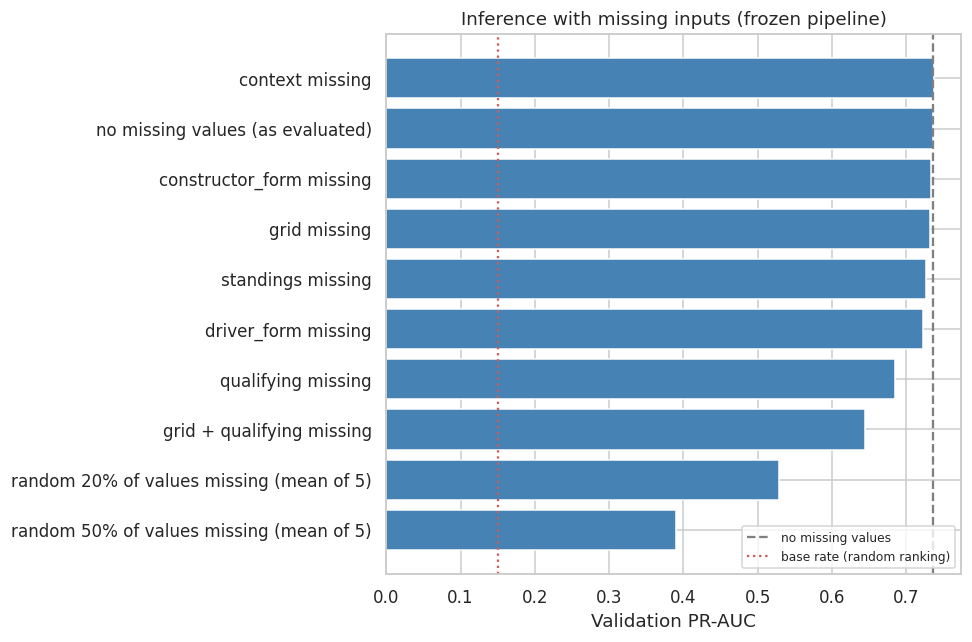

In [373]:
def batch_p(df_raw):
    return INF_MODEL.predict_proba(INF_PREP.transform(df_raw[FEATURES]))[:, 1]

def scores(p):
    return {"roc_auc": roc_auc_score(y_val, p), "pr_auc": average_precision_score(y_val, p),
            "top3_prec": top3_prec(rid_va, y_val, p)}

rows = [{"scenario": "no missing values (as evaluated)", **scores(batch_p(va_df))}]

for g, fs in FEATURE_GROUPS.items():
    if fs:
        d = va_df[FEATURES].copy(); d[fs] = np.nan
        rows.append({"scenario": f"{g} missing", **scores(batch_p(d))})

combo = [f for g in ("grid", "qualifying") for f in FEATURE_GROUPS.get(g, [])]
d = va_df[FEATURES].copy(); d[combo] = np.nan
rows.append({"scenario": "grid + qualifying missing", **scores(batch_p(d))})

rng = np.random.default_rng(SEED)
for frac in [0.2, 0.5]:
    sc = []
    for _ in range(5):
        d = va_df[FEATURES].mask(rng.random((len(va_df), len(FEATURES))) < frac)
        sc.append(scores(batch_p(d)))
    rows.append({"scenario": f"random {int(frac * 100)}% of values missing (mean of 5)",
                 **pd.DataFrame(sc).mean().to_dict()})

stress = pd.DataFrame(rows).set_index("scenario")
stress["pr_auc_loss"] = stress.loc["no missing values (as evaluated)", "pr_auc"] - stress.pr_auc
display(stress.round(4))

s = stress.sort_values("pr_auc")
fig, ax = plt.subplots(figsize=(9, 0.45 * len(s) + 1.5))
ax.barh(s.index, s.pr_auc, color="steelblue")
ax.axvline(stress.iloc[0].pr_auc, color="gray", ls="--", label="no missing values")
ax.axvline(y_val.mean(), color="indianred", ls=":", label="base rate (random ranking)")
ax.set_xlabel("Validation PR-AUC"); ax.set_title("Inference with missing inputs (frozen pipeline)")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); save_fig("s11_missing_stress"); plt.show()
stress.to_csv(OUT / "inference_missing_stress.csv")

In [374]:
BUNDLE = {"model_name": INF_MODEL_NAME, "model": INF_MODEL, "prep": INF_PREP, "features": list(FEATURES),
          "threshold": INF_THR, "train_range": TRAIN_RANGE, "binary_features": BIN_FEATS}
try:
    joblib.dump(BUNDLE, OUT / "inference_bundle.joblib")
    loaded = joblib.load(OUT / "inference_bundle.joblib")
    X_part = (pd.DataFrame([rec_part])
                .reindex(columns=loaded["features"])
                .replace(r"\N", np.nan)
                .apply(pd.to_numeric, errors="coerce"))
    p_loaded = loaded["model"].predict_proba(loaded["prep"].transform(X_part))[:, 1][0]
    assert abs(p_loaded - res_part["p_podium"]) < 1e-9
    print("Bundle saved and reloaded: identical prediction", round(float(p_loaded), 4))
except Exception as e:
    print("Bundle could not be saved/reloaded:", type(e).__name__, e)

Bundle saved and reloaded: identical prediction 0.0818


## Inference findings
- **Complete record** (Max Verstappen, Saudi Arabian Grand Prix 2024): P(podium) = 0.903, above the validation threshold 0.238, so the call is podium; it matches the Section 8 test prediction exactly, and he won.
- **Partially-missing record** (qualifying and three driver-form inputs omitted, `con_pod5` = None, `d_pts_share_bef` = `\N`): 9 of 26 inputs missing, flagged `partial`; P(podium) = 0.082 (change -0.821) and the call becomes "no podium". Omitted keys, None, NaN and the `\N` sentinel all give the same result.
- **Safety:** the post-race field `points` is rejected with an error; an unknown field is ignored with a warning; `grid_eff` = 999 is flagged as outside the training range [1, 24]; identifier columns are ignored; an empty record still returns a probability (0.028) but is flagged `mostly missing (26 of 26)`.
- **Stress test (validation):** PR-AUC falls from 0.736 to 0.684 without qualifying (-0.052), 0.722 without driver form (-0.014), 0.727 without standings (-0.009), 0.732 without the grid group (-0.005) and 0.645 without grid and qualifying (-0.091); constructor form or context missing costs nothing material. With 20% of values missing at random PR-AUC is 0.528 and with 50% it is 0.391 (base rate 0.151). The model degrades gracefully when one group is missing but sharply when many inputs are missing at once.
- **Whole race (Saudi Arabian GP 2024):** the predicted probabilities sum to 3.08 against 3 actual podiums, and all 3 of the highest-ranked drivers finished on the podium. Over the test seasons the mean sum is 2.80, and 198 of 1,352 test rows trigger a training-range warning (field size and driver experience drift).
- **Limitations:** ten features (`drv_starts`, `field_size`, `grid_eff`, `has_quali`, `home_race`, `pit_lane_start`, `round`, `team_best_grid`, `d_pts_share_bef`, `c_pts_share_bef`) were never missing in training and have no missing-value indicator, so a missing value there is treated as a typical value. `grid_eff` correlates 0.97 with `quali_pos`, and the logistic regression gives it almost no weight (an out-of-range `grid_eff` of 999 even moves P slightly up, from 0.903 to 0.914, an artifact of winsorising and collinearity); a record with only grid information therefore gets P = 0.026, the same as an empty record. The prediction is driven by qualifying position and team form, so records without qualifying information should be read as approximate.